# # 08 — AML Candidate Validation

This notebook validates the computationally shortlisted AML drug–target interactions using external evidence.

The validation workflow includes:

1. Preparing the candidate and reference-control validation set
2. Retrieving known drug–target activity evidence
3. Searching AML-specific literature
4. Reviewing clinical-development evidence
5. Assessing reference-control recovery
6. Assigning an external evidence strength
7. Producing the final validated candidate shortlist

Predicted affinity scores are computational hypotheses and are not treated as experimental confirmation.

# Imports and project setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import sys

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import config as cfg

AML_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "aml"
)

PREDICTIONS_DIR = cfg.PREDICTIONS_DIR
METRICS_DIR = cfg.METRICS_DIR

VALIDATION_RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "validation"
)

VALIDATION_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:", PROJECT_ROOT)
print("AML data directory:", AML_DATA_DIR)
print(
    "Validation results directory:",
    VALIDATION_RESULTS_DIR,
)

Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing
AML data directory: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml
Validation results directory: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation


# Define validation input paths

In [2]:
aml_ranked_predictions_path = (
    PREDICTIONS_DIR
    / "aml_ranked_screening_predictions.csv"
)

aml_top_candidates_per_target_path = (
    AML_DATA_DIR
    / "aml_top_candidates_per_target.csv"
)

aml_overall_candidate_shortlist_path = (
    AML_DATA_DIR
    / "aml_overall_candidate_shortlist.csv"
)

aml_candidate_drug_summary_path = (
    AML_DATA_DIR
    / "aml_candidate_drug_summary.csv"
)

aml_reference_drug_rankings_path = (
    AML_DATA_DIR
    / "aml_reference_drug_rankings.csv"
)

validation_input_paths = [
    aml_ranked_predictions_path,
    aml_top_candidates_per_target_path,
    aml_overall_candidate_shortlist_path,
    aml_candidate_drug_summary_path,
    aml_reference_drug_rankings_path,
]

for input_path in validation_input_paths:
    print(
        input_path.name,
        "→",
        input_path.exists(),
    )

assert all(
    input_path.exists()
    for input_path in validation_input_paths
)

print("All candidate-validation inputs found.")

aml_ranked_screening_predictions.csv → True
aml_top_candidates_per_target.csv → True
aml_overall_candidate_shortlist.csv → True
aml_candidate_drug_summary.csv → True
aml_reference_drug_rankings.csv → True
All candidate-validation inputs found.


# Load the candidate-ranking results

In [3]:
aml_ranked_predictions_df = pd.read_csv(
    aml_ranked_predictions_path
)

aml_top_candidates_per_target_df = pd.read_csv(
    aml_top_candidates_per_target_path
)

aml_overall_candidate_shortlist_df = pd.read_csv(
    aml_overall_candidate_shortlist_path
)

aml_candidate_drug_summary_df = pd.read_csv(
    aml_candidate_drug_summary_path
)

aml_reference_drug_rankings_df = pd.read_csv(
    aml_reference_drug_rankings_path
)

print(
    "All ranked predictions:",
    aml_ranked_predictions_df.shape,
)

print(
    "Top candidates per target:",
    aml_top_candidates_per_target_df.shape,
)

print(
    "Overall shortlist:",
    aml_overall_candidate_shortlist_df.shape,
)

print(
    "Candidate-drug summary:",
    aml_candidate_drug_summary_df.shape,
)

print(
    "Reference-drug pairs:",
    aml_reference_drug_rankings_df.shape,
)

All ranked predictions: (72, 49)
Top candidates per target: (18, 51)
Overall shortlist: (10, 52)
Candidate-drug summary: (6, 16)
Reference-drug pairs: (36, 50)


# Inspect the shortlist tables

In [4]:
print("Top candidates per AML target")

display(
    aml_top_candidates_per_target_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "candidate_rank_within_target",
        ]
    ].head(10)
)

print("Overall candidate shortlist")

display(
    aml_overall_candidate_shortlist_df[
        [
            "overall_shortlist_rank",
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
        ]
    ]
)

Top candidates per AML target


,pair_id,drug_name,gene_symbol,predicted_kiba_score,candidate_rank_within_target
0,AMLPAIR_000043,nilotinib,BCL2,11.831854,1
1,AMLPAIR_000061,sorafenib,BCL2,11.711703,2
2,AMLPAIR_000067,sunitinib,BCL2,11.672861,3
3,AMLPAIR_000068,sunitinib,FLT3,12.930372,1
4,AMLPAIR_000062,sorafenib,FLT3,12.698849,2
5,AMLPAIR_000044,nilotinib,FLT3,12.511866,3
6,AMLPAIR_000045,nilotinib,IDH1,11.788089,1
7,AMLPAIR_000063,sorafenib,IDH1,11.654645,2
8,AMLPAIR_000069,sunitinib,IDH1,11.615656,3
9,AMLPAIR_000046,nilotinib,IDH2,11.817014,1


Overall candidate shortlist


,overall_shortlist_rank,pair_id,drug_name,gene_symbol,predicted_kiba_score
0,1,AMLPAIR_000068,sunitinib,FLT3,12.930372
1,2,AMLPAIR_000047,nilotinib,MEN1,11.935020
2,3,AMLPAIR_000048,nilotinib,IL3RA,11.878899
3,4,AMLPAIR_000043,nilotinib,BCL2,11.831854
4,5,AMLPAIR_000046,nilotinib,IDH2,11.817014
5,6,AMLPAIR_000045,nilotinib,IDH1,11.788089
6,7,AMLPAIR_000062,sorafenib,FLT3,12.698849
7,8,AMLPAIR_000065,sorafenib,MEN1,11.835679
8,9,AMLPAIR_000066,sorafenib,IL3RA,11.716854
9,10,AMLPAIR_000061,sorafenib,BCL2,11.711703


# Validate required columns

In [5]:
required_ranked_columns = [
    "pair_id",
    "drug_id",
    "drug_name",
    "canonical_smiles",
    "target_id",
    "gene_symbol",
    "target_name",
    "predicted_kiba_score",
    "ranking_group",
    "checkpoint_prediction_status",
]

missing_ranked_columns = [
    column_name
    for column_name in required_ranked_columns
    if column_name
    not in aml_ranked_predictions_df.columns
]

if missing_ranked_columns:
    raise KeyError(
        "Ranked prediction table is missing: "
        f"{missing_ranked_columns}"
    )

assert (
    aml_ranked_predictions_df[
        "pair_id"
    ].is_unique
)

assert np.isfinite(
    pd.to_numeric(
        aml_ranked_predictions_df[
            "predicted_kiba_score"
        ],
        errors="coerce",
    )
).all()

print("Candidate-validation inputs validated.")

Candidate-validation inputs validated.


# Build the candidate validation set — Identify shortlisted candidate pairs

In [6]:
target_shortlist_pair_ids = set(
    aml_top_candidates_per_target_df[
        "pair_id"
    ].astype(str)
)

overall_shortlist_pair_ids = set(
    aml_overall_candidate_shortlist_df[
        "pair_id"
    ].astype(str)
)

candidate_validation_pair_ids = (
    target_shortlist_pair_ids
    | overall_shortlist_pair_ids
)

print(
    "Target-shortlist pairs:",
    len(target_shortlist_pair_ids),
)

print(
    "Overall-shortlist pairs:",
    len(overall_shortlist_pair_ids),
)

print(
    "Unique candidate pairs selected "
    "for validation:",
    len(candidate_validation_pair_ids),
)

Target-shortlist pairs: 18
Overall-shortlist pairs: 10
Unique candidate pairs selected for validation: 18


# Create the candidate validation table

In [7]:
candidate_validation_df = (
    aml_ranked_predictions_df[
        aml_ranked_predictions_df[
            "pair_id"
        ]
        .astype(str)
        .isin(
            candidate_validation_pair_ids
        )
    ]
    .copy()
)

candidate_validation_df[
    "in_target_shortlist"
] = (
    candidate_validation_df[
        "pair_id"
    ]
    .astype(str)
    .isin(
        target_shortlist_pair_ids
    )
)

candidate_validation_df[
    "in_overall_shortlist"
] = (
    candidate_validation_df[
        "pair_id"
    ]
    .astype(str)
    .isin(
        overall_shortlist_pair_ids
    )
)

candidate_validation_df[
    "validation_scope"
] = np.select(
    [
        (
            candidate_validation_df[
                "in_target_shortlist"
            ]
            & candidate_validation_df[
                "in_overall_shortlist"
            ]
        ),
        candidate_validation_df[
            "in_target_shortlist"
        ],
        candidate_validation_df[
            "in_overall_shortlist"
        ],
    ],
    [
        "target_and_overall_shortlist",
        "target_shortlist",
        "overall_shortlist",
    ],
    default="candidate_shortlist",
)

candidate_validation_df[
    "validation_record_type"
] = "repurposing_candidate"

print(
    "Candidate validation records:",
    len(candidate_validation_df),
)

display(
    candidate_validation_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "validation_scope",
        ]
    ]
    .sort_values(
        "predicted_kiba_score",
        ascending=False,
    )
)

Candidate validation records: 18


,pair_id,drug_name,gene_symbol,predicted_kiba_score,validation_scope
49,AMLPAIR_000068,sunitinib,FLT3,12.930372,target_and_overall_shortlist
51,AMLPAIR_000062,sorafenib,FLT3,12.698849,target_and_overall_shortlist
52,AMLPAIR_000044,nilotinib,FLT3,12.511866,target_shortlist
1,AMLPAIR_000047,nilotinib,MEN1,11.935020,target_and_overall_shortlist
37,AMLPAIR_000048,nilotinib,IL3RA,11.878899,target_and_overall_shortlist
3,AMLPAIR_000065,sorafenib,MEN1,11.835679,target_and_overall_shortlist
25,AMLPAIR_000043,nilotinib,BCL2,11.831854,target_and_overall_shortlist
61,AMLPAIR_000046,nilotinib,IDH2,11.817014,target_and_overall_shortlist
5,AMLPAIR_000071,sunitinib,MEN1,11.806074,target_shortlist
13,AMLPAIR_000045,nilotinib,IDH1,11.788089,target_and_overall_shortlist


# Prepare reference-control records — Prepare reference-drug validation pairs

In [8]:
reference_validation_df = (
    aml_reference_drug_rankings_df
    .copy()
)

reference_validation_df[
    "in_target_shortlist"
] = False

reference_validation_df[
    "in_overall_shortlist"
] = False

reference_validation_df[
    "validation_scope"
] = "reference_panel"

reference_validation_df[
    "validation_record_type"
] = "reference_control"

print(
    "Reference validation records:",
    len(reference_validation_df),
)

display(
    reference_validation_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "reference_drug_rank_within_target",
        ]
    ].head(12)
)

Reference validation records: 36


,pair_id,drug_name,gene_symbol,predicted_kiba_score,reference_drug_rank_within_target
0,AMLPAIR_000019,midostaurin,BCL2,12.836241,1
1,AMLPAIR_000007,gilteritinib,BCL2,11.820067,2
2,AMLPAIR_000025,quizartinib,BCL2,11.687417,3
3,AMLPAIR_000001,enasidenib,BCL2,11.634454,4
4,AMLPAIR_000031,venetoclax,BCL2,11.596877,5
5,AMLPAIR_000013,ivosidenib,BCL2,11.558054,6
6,AMLPAIR_000020,midostaurin,FLT3,13.457742,1
7,AMLPAIR_000026,quizartinib,FLT3,12.808944,2
8,AMLPAIR_000008,gilteritinib,FLT3,12.326099,3
9,AMLPAIR_000032,venetoclax,FLT3,12.265362,4


# Combine candidates and reference controls

In [9]:
common_validation_columns = sorted(
    set(
        candidate_validation_df.columns
    )
    | set(
        reference_validation_df.columns
    )
)

candidate_validation_df = (
    candidate_validation_df.reindex(
        columns=common_validation_columns
    )
)

reference_validation_df = (
    reference_validation_df.reindex(
        columns=common_validation_columns
    )
)

aml_validation_pairs_df = pd.concat(
    [
        candidate_validation_df,
        reference_validation_df,
    ],
    ignore_index=True,
)

aml_validation_pairs_df = (
    aml_validation_pairs_df
    .drop_duplicates(
        subset="pair_id",
        keep="first",
    )
    .reset_index(drop=True)
)

aml_validation_pairs_df[
    "predicted_kiba_score"
] = pd.to_numeric(
    aml_validation_pairs_df[
        "predicted_kiba_score"
    ],
    errors="coerce",
)

aml_validation_pairs_df = (
    aml_validation_pairs_df
    .sort_values(
        [
            "validation_record_type",
            "gene_symbol",
            "predicted_kiba_score",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

print(
    "Total validation pairs:",
    len(aml_validation_pairs_df),
)

print(
    aml_validation_pairs_df[
        "validation_record_type"
    ].value_counts()
)

Total validation pairs: 54
validation_record_type
reference_control        36
repurposing_candidate    18
Name: count, dtype: int64


# Validate the combined validation set

In [10]:
assert (
    aml_validation_pairs_df[
        "pair_id"
    ].is_unique
)

assert not (
    aml_validation_pairs_df[
        "drug_name"
    ].isna().any()
)

assert not (
    aml_validation_pairs_df[
        "gene_symbol"
    ].isna().any()
)

assert not (
    aml_validation_pairs_df[
        "canonical_smiles"
    ].isna().any()
)

assert np.isfinite(
    aml_validation_pairs_df[
        "predicted_kiba_score"
    ]
).all()

assert set(
    aml_validation_pairs_df[
        "validation_record_type"
    ]
) == {
    "repurposing_candidate",
    "reference_control",
}

print("Combined validation set validated.")

Combined validation set validated.


# Prepare external database queries — Create the unique drug query table

In [11]:
drug_query_columns = [
    "drug_id",
    "drug_name",
    "canonical_smiles",
]

for optional_column in [
    "development_status",
    "candidate_source",
    "drug_source_reference",
]:
    if (
        optional_column
        in aml_validation_pairs_df.columns
    ):
        drug_query_columns.append(
            optional_column
        )

validation_drug_queries_df = (
    aml_validation_pairs_df[
        drug_query_columns
    ]
    .drop_duplicates(
        subset="drug_id"
    )
    .reset_index(drop=True)
)

validation_drug_queries_df[
    "chembl_query_name"
] = (
    validation_drug_queries_df[
        "drug_name"
    ]
    .astype(str)
    .str.strip()
)

validation_drug_queries_df[
    "pubmed_query_name"
] = (
    validation_drug_queries_df[
        "drug_name"
    ]
    .astype(str)
    .str.strip()
)

validation_drug_queries_df[
    "clinical_trials_query_name"
] = (
    validation_drug_queries_df[
        "drug_name"
    ]
    .astype(str)
    .str.strip()
)

print(
    "Unique validation drugs:",
    len(validation_drug_queries_df),
)

display(
    validation_drug_queries_df
)

Unique validation drugs: 9


,drug_id,drug_name,canonical_smiles,development_status,candidate_source,drug_source_reference,chembl_query_name,pubmed_query_name,clinical_trials_query_name
0,PUBCHEM_9829523,midostaurin,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,reference_control,aml_reference_panel,PubChem CID:9829523,midostaurin,midostaurin,midostaurin
1,PUBCHEM_49803313,gilteritinib,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,reference_control,aml_reference_panel,PubChem CID:49803313,gilteritinib,gilteritinib,gilteritinib
2,PUBCHEM_24889392,quizartinib,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,reference_control,aml_reference_panel,PubChem CID:24889392,quizartinib,quizartinib,quizartinib
3,PUBCHEM_89683805,enasidenib,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,reference_control,aml_reference_panel,PubChem CID:89683805,enasidenib,enasidenib,enasidenib
4,PUBCHEM_49846579,venetoclax,CC1(C)CCC(CN2CCN(c3ccc(C(=O)NS(=O)(=O)c4ccc(NC...,reference_control,aml_reference_panel,PubChem CID:49846579,venetoclax,venetoclax,venetoclax
5,PUBCHEM_71657455,ivosidenib,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,reference_control,aml_reference_panel,PubChem CID:71657455,ivosidenib,ivosidenib,ivosidenib
6,PUBCHEM_644241,nilotinib,Cc1cn(-c2cc(NC(=O)c3ccc(C)c(Nc4nccc(-c5cccnc5)...,repurposing_candidate,kinase_inhibitor_panel,PubChem CID:644241,nilotinib,nilotinib,nilotinib
7,PUBCHEM_216239,sorafenib,CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)...,repurposing_candidate,kinase_inhibitor_panel,PubChem CID:216239,sorafenib,sorafenib,sorafenib
8,PUBCHEM_5329102,sunitinib,CCN(CC)CCNC(=O)c1c(C)[nH]c(/C=C2\C(=O)Nc3ccc(F...,repurposing_candidate,kinase_inhibitor_panel,PubChem CID:5329102,sunitinib,sunitinib,sunitinib


# Create the unique target query table

In [12]:
target_query_columns = [
    "target_id",
    "gene_symbol",
    "target_name",
]

for optional_column in [
    "target_class",
    "target_source_reference",
]:
    if (
        optional_column
        in aml_validation_pairs_df.columns
    ):
        target_query_columns.append(
            optional_column
        )

validation_target_queries_df = (
    aml_validation_pairs_df[
        target_query_columns
    ]
    .drop_duplicates(
        subset="target_id"
    )
    .reset_index(drop=True)
)

validation_target_queries_df[
    "uniprot_accession"
] = (
    validation_target_queries_df[
        "target_id"
    ]
    .astype(str)
    .str.strip()
)

validation_target_queries_df[
    "chembl_target_query"
] = (
    validation_target_queries_df[
        "gene_symbol"
    ]
    .astype(str)
    .str.strip()
)

validation_target_queries_df[
    "pubmed_target_query"
] = (
    validation_target_queries_df[
        "gene_symbol"
    ]
    .astype(str)
    .str.strip()
)

print(
    "Unique AML validation targets:",
    len(validation_target_queries_df),
)

display(
    validation_target_queries_df
)

Unique AML validation targets: 6


,target_id,gene_symbol,target_name,target_class,target_source_reference,uniprot_accession,chembl_target_query,pubmed_target_query
0,P10415,BCL2,Apoptosis regulator Bcl-2,apoptosis_regulator,UniProtKB:P10415,P10415,BCL2,BCL2
1,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,protein_kinase,UniProtKB:P36888,P36888,FLT3,FLT3
2,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,metabolic_enzyme,UniProtKB:O75874,O75874,IDH1,IDH1
3,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,metabolic_enzyme,UniProtKB:P48735,P48735,IDH2,IDH2
4,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),cell_surface_receptor,UniProtKB:P26951,P26951,IL3RA,IL3RA
5,O00255,MEN1,Menin,transcriptional_regulator,UniProtKB:O00255,O00255,MEN1,MEN1


# Build the validation evidence table — Define the evidence columns

In [13]:
validation_evidence_columns = [
    "pair_id",
    "validation_record_type",
    "validation_scope",
    "drug_id",
    "drug_name",
    "canonical_smiles",
    "target_id",
    "gene_symbol",
    "target_name",
    "predicted_kiba_score",
    "candidate_rank_within_target",
    "overall_shortlist_rank",
    "checkpoint_prediction_status",

    # ChEMBL drug mapping
    "chembl_compound_id",
    "chembl_compound_name",
    "chembl_compound_match_status",

    # ChEMBL target mapping
    "chembl_target_id",
    "chembl_target_name",
    "chembl_target_match_status",

    # Drug-target activity evidence
    "chembl_activity_count",
    "chembl_direct_binding_count",
    "chembl_best_pchembl_value",
    "chembl_median_pchembl_value",
    "chembl_activity_types",
    "chembl_assay_types",
    "direct_drug_target_evidence",

    # Literature evidence
    "pubmed_drug_target_count",
    "pubmed_aml_count",
    "key_pubmed_ids",
    "aml_literature_evidence",

    # Clinical-development evidence
    "clinical_trial_count",
    "aml_clinical_trial_count",
    "key_clinical_trial_ids",
    "clinical_development_evidence",

    # Final evidence assessment
    "reference_control_recovered",
    "external_evidence_score",
    "external_evidence_strength",
    "validation_status",
    "validation_notes",
    "last_checked_utc",
]

print(
    "Validation evidence columns:",
    len(validation_evidence_columns),
)

Validation evidence columns: 40


# Create the initial evidence table

In [14]:
validation_base_columns = [
    column_name
    for column_name
    in validation_evidence_columns
    if column_name
    in aml_validation_pairs_df.columns
]

validation_evidence_df = (
    aml_validation_pairs_df[
        validation_base_columns
    ]
    .copy()
)

for column_name in validation_evidence_columns:
    if (
        column_name
        not in validation_evidence_df.columns
    ):
        validation_evidence_df[
            column_name
        ] = pd.NA

validation_evidence_df = (
    validation_evidence_df[
        validation_evidence_columns
    ]
)

validation_evidence_df[
    "chembl_activity_count"
] = 0

validation_evidence_df[
    "chembl_direct_binding_count"
] = 0

validation_evidence_df[
    "pubmed_drug_target_count"
] = 0

validation_evidence_df[
    "pubmed_aml_count"
] = 0

validation_evidence_df[
    "clinical_trial_count"
] = 0

validation_evidence_df[
    "aml_clinical_trial_count"
] = 0

validation_evidence_df[
    "reference_control_recovered"
] = False

validation_evidence_df[
    "external_evidence_score"
] = 0

validation_evidence_df[
    "external_evidence_strength"
] = "not_yet_assessed"

validation_evidence_df[
    "validation_status"
] = "pending_external_validation"

validation_evidence_df[
    "last_checked_utc"
] = (
    datetime.now(
        timezone.utc
    ).isoformat()
)

print(
    "Evidence rows:",
    len(validation_evidence_df),
)

display(
    validation_evidence_df[
        [
            "pair_id",
            "validation_record_type",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "validation_status",
        ]
    ].head(12)
)

Evidence rows: 54


,pair_id,validation_record_type,drug_name,gene_symbol,predicted_kiba_score,validation_status
0,AMLPAIR_000019,reference_control,midostaurin,BCL2,12.836241,pending_external_validation
1,AMLPAIR_000007,reference_control,gilteritinib,BCL2,11.820067,pending_external_validation
2,AMLPAIR_000025,reference_control,quizartinib,BCL2,11.687417,pending_external_validation
3,AMLPAIR_000001,reference_control,enasidenib,BCL2,11.634454,pending_external_validation
4,AMLPAIR_000031,reference_control,venetoclax,BCL2,11.596877,pending_external_validation
5,AMLPAIR_000013,reference_control,ivosidenib,BCL2,11.558054,pending_external_validation
6,AMLPAIR_000020,reference_control,midostaurin,FLT3,13.457742,pending_external_validation
7,AMLPAIR_000026,reference_control,quizartinib,FLT3,12.808944,pending_external_validation
8,AMLPAIR_000008,reference_control,gilteritinib,FLT3,12.326099,pending_external_validation
9,AMLPAIR_000032,reference_control,venetoclax,FLT3,12.265362,pending_external_validation


# Define validation output paths

In [15]:
validation_pairs_path = (
    AML_DATA_DIR
    / "validation_pairs.csv"
)

validation_evidence_path = (
    AML_DATA_DIR
    / "validation_evidence.csv"
)

validation_drug_queries_path = (
    VALIDATION_RESULTS_DIR
    / "validation_drug_queries.csv"
)

validation_target_queries_path = (
    VALIDATION_RESULTS_DIR
    / "validation_target_queries.csv"
)

validation_workspace_summary_path = (
    VALIDATION_RESULTS_DIR
    / "validation_workspace_summary.json"
)

print("Validation evidence path:")
print(validation_evidence_path)

Validation evidence path:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/validation_evidence.csv


# Save the validation workspace

In [16]:
aml_validation_pairs_df.to_csv(
    validation_pairs_path,
    index=False,
)

validation_evidence_df.to_csv(
    validation_evidence_path,
    index=False,
)

validation_drug_queries_df.to_csv(
    validation_drug_queries_path,
    index=False,
)

validation_target_queries_df.to_csv(
    validation_target_queries_path,
    index=False,
)

print("Validation workspace saved.")

Validation workspace saved.


# Save the workspace summary

In [17]:
validation_workspace_summary = {
    "total_validation_pairs": int(
        len(aml_validation_pairs_df)
    ),
    "repurposing_candidate_pairs": int(
        (
            aml_validation_pairs_df[
                "validation_record_type"
            ]
            == "repurposing_candidate"
        ).sum()
    ),
    "reference_control_pairs": int(
        (
            aml_validation_pairs_df[
                "validation_record_type"
            ]
            == "reference_control"
        ).sum()
    ),
    "unique_validation_drugs": int(
        aml_validation_pairs_df[
            "drug_id"
        ].nunique()
    ),
    "unique_validation_targets": int(
        aml_validation_pairs_df[
            "target_id"
        ].nunique()
    ),
    "candidate_selection_sources": [
        "top_candidates_per_target",
        "overall_candidate_shortlist",
    ],
    "external_evidence_sources_planned": [
        "ChEMBL",
        "PubMed",
        "ClinicalTrials.gov",
    ],
    "validation_pairs_file": str(
        validation_pairs_path
    ),
    "validation_evidence_file": str(
        validation_evidence_path
    ),
    "drug_query_file": str(
        validation_drug_queries_path
    ),
    "target_query_file": str(
        validation_target_queries_path
    ),
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

with open(
    validation_workspace_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        validation_workspace_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        validation_workspace_summary,
        indent=4,
    )
)

{
    "total_validation_pairs": 54,
    "repurposing_candidate_pairs": 18,
    "reference_control_pairs": 36,
    "unique_validation_drugs": 9,
    "unique_validation_targets": 6,
    "candidate_selection_sources": [
        "top_candidates_per_target",
        "overall_candidate_shortlist"
    ],
    "external_evidence_sources_planned": [
        "ChEMBL",
        "PubMed",
        "ClinicalTrials.gov"
    ],
    "validation_pairs_file": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/validation_pairs.csv",
    "validation_evidence_file": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/validation_evidence.csv",
    "drug_query_file": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/validation_drug_queries.csv",
    "target_query

# Confirm all outputs

In [18]:
validation_workspace_outputs = [
    validation_pairs_path,
    validation_evidence_path,
    validation_drug_queries_path,
    validation_target_queries_path,
    validation_workspace_summary_path,
]

for output_path in (
    validation_workspace_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in validation_workspace_outputs
)

assert len(
    validation_evidence_df
) == len(
    aml_validation_pairs_df
)

assert (
    validation_evidence_df[
        "pair_id"
    ].is_unique
)

print()

print(
    "Candidate-validation workspace "
    "prepared successfully."
)

validation_pairs.csv → True
validation_evidence.csv → True
validation_drug_queries.csv → True
validation_target_queries.csv → True
validation_workspace_summary.json → True

Candidate-validation workspace prepared successfully.


## Candidate Validation Part A Complete

The candidate-validation workspace contains:

- shortlisted repurposing candidate pairs;
- reference-drug prediction pairs;
- unique drug queries;
- unique AML target queries;
- an evidence table for ChEMBL, literature and clinical-trial results.

The next stage maps the candidate drugs and AML targets to ChEMBL identifiers and retrieves available experimental drug–target activity records.

# Candidate Validation Part B — ChEMBL Evidence

This section maps shortlisted drugs and AML targets to ChEMBL identifiers and retrieves available experimental binding records.

Drug mapping is performed primarily using exact Standard InChIKey matching.

Target mapping is performed using UniProt accessions.

Retrieved binding evidence includes:

- ChEMBL activity counts;
- binding assay counts;
- activity types such as IC50, Ki and Kd;
- maximum and median pChEMBL values;
- source document counts;
- data-quality flags.

The presence of a ChEMBL binding record supports a drug–target interaction but does not by itself demonstrate efficacy in AML.

# Install the official ChEMBL client

In [19]:
%pip install -q chembl_webresource_client

Note: you may need to restart the kernel to use updated packages.


# Imports and ChEMBL configuration

In [20]:
import re
import time
from datetime import datetime, timezone

from rdkit import Chem
from tqdm.auto import tqdm

from chembl_webresource_client.new_client import (
    new_client,
)

from chembl_webresource_client.settings import (
    Settings,
)

chembl_settings = Settings.Instance()

chembl_settings.TIMEOUT = 60
chembl_settings.TOTAL_RETRIES = 5
chembl_settings.CACHING = True

print("ChEMBL client configured.")

ChEMBL client configured.


# Reload the validation workspace

In [21]:
validation_evidence_df = pd.read_csv(
    validation_evidence_path
)

validation_drug_queries_df = pd.read_csv(
    validation_drug_queries_path
)

validation_target_queries_df = pd.read_csv(
    validation_target_queries_path
)

print(
    "Validation evidence rows:",
    len(validation_evidence_df),
)

print(
    "Unique drug queries:",
    len(validation_drug_queries_df),
)

print(
    "Unique target queries:",
    len(validation_target_queries_df),
)

display(
    validation_drug_queries_df.head()
)

display(
    validation_target_queries_df.head()
)

Validation evidence rows: 54
Unique drug queries: 9
Unique target queries: 6


,drug_id,drug_name,canonical_smiles,development_status,candidate_source,drug_source_reference,chembl_query_name,pubmed_query_name,clinical_trials_query_name
0,PUBCHEM_9829523,midostaurin,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,reference_control,aml_reference_panel,PubChem CID:9829523,midostaurin,midostaurin,midostaurin
1,PUBCHEM_49803313,gilteritinib,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,reference_control,aml_reference_panel,PubChem CID:49803313,gilteritinib,gilteritinib,gilteritinib
2,PUBCHEM_24889392,quizartinib,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,reference_control,aml_reference_panel,PubChem CID:24889392,quizartinib,quizartinib,quizartinib
3,PUBCHEM_89683805,enasidenib,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,reference_control,aml_reference_panel,PubChem CID:89683805,enasidenib,enasidenib,enasidenib
4,PUBCHEM_49846579,venetoclax,CC1(C)CCC(CN2CCN(c3ccc(C(=O)NS(=O)(=O)c4ccc(NC...,reference_control,aml_reference_panel,PubChem CID:49846579,venetoclax,venetoclax,venetoclax


,target_id,gene_symbol,target_name,target_class,target_source_reference,uniprot_accession,chembl_target_query,pubmed_target_query
0,P10415,BCL2,Apoptosis regulator Bcl-2,apoptosis_regulator,UniProtKB:P10415,P10415,BCL2,BCL2
1,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,protein_kinase,UniProtKB:P36888,P36888,FLT3,FLT3
2,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,metabolic_enzyme,UniProtKB:O75874,O75874,IDH1,IDH1
3,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,metabolic_enzyme,UniProtKB:P48735,P48735,IDH2,IDH2
4,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),cell_surface_receptor,UniProtKB:P26951,P26951,IL3RA,IL3RA


# Create a safe ChEMBL query helper

In [22]:
def run_chembl_query(
    query_factory,
    query_description,
    maximum_attempts=3,
):
    last_error = None

    for attempt in range(
        1,
        maximum_attempts + 1,
    ):
        try:
            return list(
                query_factory()
            )

        except Exception as error:
            last_error = error

            print(
                f"{query_description} failed "
                f"on attempt {attempt}: "
                f"{type(error).__name__}"
            )

            if attempt < maximum_attempts:
                time.sleep(
                    2 * attempt
                )

    raise RuntimeError(
        f"ChEMBL query failed: "
        f"{query_description}"
    ) from last_error


chembl_test_result = run_chembl_query(
    query_factory=lambda: (
        new_client.molecule
        .filter(
            molecule_chembl_id="CHEMBL25"
        )
        .only(
            [
                "molecule_chembl_id",
                "pref_name",
            ]
        )
    ),
    query_description=(
        "ChEMBL connection test"
    ),
)

assert len(chembl_test_result) == 1

print(
    "ChEMBL connection successful:",
    chembl_test_result[0][
        "molecule_chembl_id"
    ],
)

ChEMBL connection successful: CHEMBL25


# Map candidate drugs to ChEMBL — Define drug-mapping helpers

In [23]:
def normalise_mapping_text(value):
    if pd.isna(value):
        return ""

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def calculate_standard_inchi_key(
    smiles,
):
    molecule = Chem.MolFromSmiles(
        str(smiles)
    )

    if molecule is None:
        return None

    try:
        return Chem.MolToInchiKey(
            molecule
        )

    except Exception:
        return None


def safe_numeric_value(
    value,
    default_value=-1,
):
    try:
        if value is None:
            return default_value

        return float(value)

    except (TypeError, ValueError):
        return default_value


def choose_best_compound_match(
    records,
    drug_name,
):
    normalised_drug_name = (
        normalise_mapping_text(
            drug_name
        )
    )

    def compound_sort_key(record):
        molecule_id = str(
            record.get(
                "molecule_chembl_id",
                "",
            )
        )

        preferred_name = (
            normalise_mapping_text(
                record.get("pref_name")
            )
        )

        hierarchy = (
            record.get(
                "molecule_hierarchy"
            )
            or {}
        )

        parent_id = str(
            hierarchy.get(
                "parent_chembl_id",
                "",
            )
        )

        return (
            preferred_name
            == normalised_drug_name,
            parent_id == molecule_id,
            safe_numeric_value(
                record.get("max_phase")
            ),
        )

    return sorted(
        records,
        key=compound_sort_key,
        reverse=True,
    )[0]


print("Drug-mapping helpers created.")

Drug-mapping helpers created.


# Define the ChEMBL compound-mapping function

In [24]:
def map_drug_to_chembl(
    drug_id,
    drug_name,
    canonical_smiles,
):
    standard_inchi_key = (
        calculate_standard_inchi_key(
            canonical_smiles
        )
    )

    matches = []
    match_method = None

    if standard_inchi_key:
        matches = run_chembl_query(
            query_factory=lambda: (
                new_client.molecule.filter(
                    molecule_structures__standard_inchi_key=(
                        standard_inchi_key
                    )
                )
            ),
            query_description=(
                f"InChIKey mapping for "
                f"{drug_name}"
            ),
        )

        if matches:
            match_method = (
                "standard_inchi_key"
            )

    if not matches:
        matches = run_chembl_query(
            query_factory=lambda: (
                new_client.molecule.filter(
                    pref_name__iexact=(
                        str(drug_name)
                    )
                )
            ),
            query_description=(
                f"name mapping for "
                f"{drug_name}"
            ),
        )

        if matches:
            match_method = (
                "preferred_name"
            )

    if not matches:
        return {
            "drug_id": str(drug_id),
            "drug_name": drug_name,
            "standard_inchi_key": (
                standard_inchi_key
            ),
            "chembl_compound_id": pd.NA,
            "chembl_compound_name": pd.NA,
            "chembl_compound_match_status": (
                "unmatched"
            ),
            "chembl_compound_match_method": (
                "none"
            ),
            "chembl_compound_match_count": 0,
            "chembl_max_phase": pd.NA,
            "chembl_molecule_type": pd.NA,
        }

    selected_record = (
        choose_best_compound_match(
            records=matches,
            drug_name=drug_name,
        )
    )

    if len(matches) == 1:
        match_status = (
            "exact_structure_match"
            if match_method
            == "standard_inchi_key"
            else "exact_name_match"
        )

    else:
        match_status = (
            "multiple_matches_selected"
        )

    return {
        "drug_id": str(drug_id),
        "drug_name": drug_name,
        "standard_inchi_key": (
            standard_inchi_key
        ),
        "chembl_compound_id": (
            selected_record.get(
                "molecule_chembl_id"
            )
        ),
        "chembl_compound_name": (
            selected_record.get(
                "pref_name"
            )
        ),
        "chembl_compound_match_status": (
            match_status
        ),
        "chembl_compound_match_method": (
            match_method
        ),
        "chembl_compound_match_count": int(
            len(matches)
        ),
        "chembl_max_phase": (
            selected_record.get(
                "max_phase"
            )
        ),
        "chembl_molecule_type": (
            selected_record.get(
                "molecule_type"
            )
        ),
    }


print(
    "ChEMBL compound-mapping "
    "function created."
)

ChEMBL compound-mapping function created.


# Map all validation drugs

In [25]:
chembl_compound_mapping_records = []

for row in tqdm(
    validation_drug_queries_df.itertuples(
        index=False
    ),
    total=len(
        validation_drug_queries_df
    ),
    desc="Mapping drugs to ChEMBL",
):
    mapping_record = map_drug_to_chembl(
        drug_id=row.drug_id,
        drug_name=row.drug_name,
        canonical_smiles=(
            row.canonical_smiles
        ),
    )

    chembl_compound_mapping_records.append(
        mapping_record
    )

    time.sleep(0.2)

chembl_compound_mapping_df = (
    pd.DataFrame(
        chembl_compound_mapping_records
    )
)

display(
    chembl_compound_mapping_df[
        [
            "drug_name",
            "chembl_compound_id",
            "chembl_compound_name",
            "chembl_compound_match_status",
            "chembl_compound_match_method",
        ]
    ]
)

print(
    "Mapped drugs:",
    int(
        chembl_compound_mapping_df[
            "chembl_compound_id"
        ].notna().sum()
    ),
)

print(
    "Unmatched drugs:",
    int(
        chembl_compound_mapping_df[
            "chembl_compound_id"
        ].isna().sum()
    ),
)

Mapping drugs to ChEMBL:   0%|          | 0/9 [00:00<?, ?it/s]

,drug_name,chembl_compound_id,chembl_compound_name,chembl_compound_match_status,chembl_compound_match_method
0,midostaurin,CHEMBL608533,MIDOSTAURIN,exact_structure_match,standard_inchi_key
1,gilteritinib,CHEMBL3301622,GILTERITINIB,exact_structure_match,standard_inchi_key
2,quizartinib,CHEMBL576982,QUIZARTINIB,exact_structure_match,standard_inchi_key
3,enasidenib,CHEMBL3989908,ENASIDENIB,exact_structure_match,standard_inchi_key
4,venetoclax,CHEMBL3137309,VENETOCLAX,exact_structure_match,standard_inchi_key
5,ivosidenib,CHEMBL3989958,IVOSIDENIB,exact_structure_match,standard_inchi_key
6,nilotinib,CHEMBL255863,NILOTINIB,exact_structure_match,standard_inchi_key
7,sorafenib,CHEMBL1336,SORAFENIB,exact_structure_match,standard_inchi_key
8,sunitinib,CHEMBL535,SUNITINIB,exact_structure_match,standard_inchi_key


Mapped drugs: 9
Unmatched drugs: 0


# Save and validate compound mappings

In [26]:
chembl_compound_mapping_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_compound_mapping.csv"
)

assert (
    chembl_compound_mapping_df[
        "drug_id"
    ].is_unique
)

chembl_compound_mapping_df.to_csv(
    chembl_compound_mapping_path,
    index=False,
)

unmatched_compounds_df = (
    chembl_compound_mapping_df[
        chembl_compound_mapping_df[
            "chembl_compound_id"
        ].isna()
    ]
)

if not unmatched_compounds_df.empty:
    print(
        "Compounds requiring manual review:"
    )

    display(
        unmatched_compounds_df[
            [
                "drug_id",
                "drug_name",
                "standard_inchi_key",
            ]
        ]
    )

print("Compound mappings saved to:")
print(chembl_compound_mapping_path)

Compound mappings saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_compound_mapping.csv


# Map AML targets to ChEMBL — Define the target-mapping function

In [27]:
def choose_best_target_match(
    records,
    gene_symbol,
):
    normalised_gene = (
        normalise_mapping_text(
            gene_symbol
        )
    )

    def target_sort_key(record):
        preferred_name = (
            normalise_mapping_text(
                record.get("pref_name")
            )
        )

        target_type = str(
            record.get(
                "target_type",
                "",
            )
        ).upper()

        organism = str(
            record.get(
                "organism",
                "",
            )
        )

        return (
            target_type
            == "SINGLE PROTEIN",
            organism == "Homo sapiens",
            normalised_gene
            in preferred_name,
        )

    return sorted(
        records,
        key=target_sort_key,
        reverse=True,
    )[0]


def map_target_to_chembl(
    target_id,
    gene_symbol,
    target_name,
):
    accession = str(
        target_id
    ).strip()

    matches = run_chembl_query(
        query_factory=lambda: (
            new_client.target.filter(
                target_components__accession=(
                    accession
                )
            )
        ),
        query_description=(
            f"target mapping for "
            f"{gene_symbol}"
        ),
    )

    human_matches = [
        record
        for record in matches
        if record.get("organism")
        == "Homo sapiens"
    ]

    preferred_matches = [
        record
        for record in human_matches
        if str(
            record.get(
                "target_type",
                "",
            )
        ).upper()
        == "SINGLE PROTEIN"
    ]

    candidate_matches = (
        preferred_matches
        or human_matches
        or matches
    )

    if not candidate_matches:
        return {
            "target_id": accession,
            "gene_symbol": gene_symbol,
            "target_name": target_name,
            "chembl_target_id": pd.NA,
            "chembl_target_name": pd.NA,
            "chembl_target_type": pd.NA,
            "chembl_target_organism": pd.NA,
            "chembl_target_match_status": (
                "unmatched"
            ),
            "chembl_target_match_count": 0,
        }

    selected_record = (
        choose_best_target_match(
            records=candidate_matches,
            gene_symbol=gene_symbol,
        )
    )

    if len(candidate_matches) == 1:
        match_status = (
            "uniprot_single_protein_match"
            if str(
                selected_record.get(
                    "target_type",
                    "",
                )
            ).upper()
            == "SINGLE PROTEIN"
            else "uniprot_target_match"
        )

    else:
        match_status = (
            "multiple_targets_selected"
        )

    return {
        "target_id": accession,
        "gene_symbol": gene_symbol,
        "target_name": target_name,
        "chembl_target_id": (
            selected_record.get(
                "target_chembl_id"
            )
        ),
        "chembl_target_name": (
            selected_record.get(
                "pref_name"
            )
        ),
        "chembl_target_type": (
            selected_record.get(
                "target_type"
            )
        ),
        "chembl_target_organism": (
            selected_record.get(
                "organism"
            )
        ),
        "chembl_target_match_status": (
            match_status
        ),
        "chembl_target_match_count": int(
            len(candidate_matches)
        ),
    }


print(
    "ChEMBL target-mapping "
    "function created."
)

ChEMBL target-mapping function created.


# Map all AML targets

In [28]:
chembl_target_mapping_records = []

for row in tqdm(
    validation_target_queries_df.itertuples(
        index=False
    ),
    total=len(
        validation_target_queries_df
    ),
    desc="Mapping targets to ChEMBL",
):
    mapping_record = (
        map_target_to_chembl(
            target_id=row.target_id,
            gene_symbol=row.gene_symbol,
            target_name=row.target_name,
        )
    )

    chembl_target_mapping_records.append(
        mapping_record
    )

    time.sleep(0.2)

chembl_target_mapping_df = pd.DataFrame(
    chembl_target_mapping_records
)

display(
    chembl_target_mapping_df[
        [
            "gene_symbol",
            "target_id",
            "chembl_target_id",
            "chembl_target_name",
            "chembl_target_type",
            "chembl_target_match_status",
        ]
    ]
)

print(
    "Mapped targets:",
    int(
        chembl_target_mapping_df[
            "chembl_target_id"
        ].notna().sum()
    ),
)

print(
    "Unmatched targets:",
    int(
        chembl_target_mapping_df[
            "chembl_target_id"
        ].isna().sum()
    ),
)

Mapping targets to ChEMBL:   0%|          | 0/6 [00:00<?, ?it/s]

,gene_symbol,target_id,chembl_target_id,chembl_target_name,chembl_target_type,chembl_target_match_status
0,BCL2,P10415,CHEMBL4860,Apoptosis regulator Bcl-2,SINGLE PROTEIN,uniprot_single_protein_match
1,FLT3,P36888,CHEMBL1974,Receptor-type tyrosine-protein kinase FLT3,SINGLE PROTEIN,uniprot_single_protein_match
2,IDH1,O75874,CHEMBL2007625,Isocitrate dehydrogenase [NADP] cytoplasmic,SINGLE PROTEIN,uniprot_single_protein_match
3,IDH2,P48735,CHEMBL3991501,"Isocitrate dehydrogenase [NADP], mitochondrial",SINGLE PROTEIN,uniprot_single_protein_match
4,IL3RA,P26951,CHEMBL3712987,Interleukin-3 receptor subunit alpha,SINGLE PROTEIN,uniprot_single_protein_match
5,MEN1,O00255,CHEMBL1615381,Menin,SINGLE PROTEIN,uniprot_single_protein_match


Mapped targets: 6
Unmatched targets: 0


# Save and validate target mappings

In [29]:
chembl_target_mapping_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_target_mapping.csv"
)

assert (
    chembl_target_mapping_df[
        "target_id"
    ].is_unique
)

chembl_target_mapping_df.to_csv(
    chembl_target_mapping_path,
    index=False,
)

unmatched_targets_df = (
    chembl_target_mapping_df[
        chembl_target_mapping_df[
            "chembl_target_id"
        ].isna()
    ]
)

if not unmatched_targets_df.empty:
    print(
        "Targets requiring manual review:"
    )

    display(
        unmatched_targets_df[
            [
                "target_id",
                "gene_symbol",
                "target_name",
            ]
        ]
    )

print("Target mappings saved to:")
print(chembl_target_mapping_path)

Target mappings saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_target_mapping.csv


# Create pair-level ChEMBL mappings — Add compound and target IDs to each validation pair

In [30]:
pair_mapping_base_columns = [
    "pair_id",
    "validation_record_type",
    "drug_id",
    "drug_name",
    "target_id",
    "gene_symbol",
    "predicted_kiba_score",
]

chembl_pair_mapping_df = (
    validation_evidence_df[
        pair_mapping_base_columns
    ]
    .copy()
)

chembl_pair_mapping_df[
    "drug_id"
] = (
    chembl_pair_mapping_df[
        "drug_id"
    ].astype(str)
)

chembl_pair_mapping_df[
    "target_id"
] = (
    chembl_pair_mapping_df[
        "target_id"
    ].astype(str)
)

compound_mapping_for_merge = (
    chembl_compound_mapping_df[
        [
            "drug_id",
            "chembl_compound_id",
            "chembl_compound_name",
            "chembl_compound_match_status",
        ]
    ]
    .copy()
)

compound_mapping_for_merge[
    "drug_id"
] = (
    compound_mapping_for_merge[
        "drug_id"
    ].astype(str)
)

target_mapping_for_merge = (
    chembl_target_mapping_df[
        [
            "target_id",
            "chembl_target_id",
            "chembl_target_name",
            "chembl_target_type",
            "chembl_target_match_status",
        ]
    ]
    .copy()
)

target_mapping_for_merge[
    "target_id"
] = (
    target_mapping_for_merge[
        "target_id"
    ].astype(str)
)

chembl_pair_mapping_df = (
    chembl_pair_mapping_df
    .merge(
        compound_mapping_for_merge,
        on="drug_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        target_mapping_for_merge,
        on="target_id",
        how="left",
        validate="many_to_one",
    )
)

chembl_pair_mapping_df[
    "pair_mapping_complete"
] = (
    chembl_pair_mapping_df[
        "chembl_compound_id"
    ].notna()
    & chembl_pair_mapping_df[
        "chembl_target_id"
    ].notna()
)

print(
    "Complete pair mappings:",
    int(
        chembl_pair_mapping_df[
            "pair_mapping_complete"
        ].sum()
    ),
)

print(
    "Incomplete pair mappings:",
    int(
        (
            ~chembl_pair_mapping_df[
                "pair_mapping_complete"
            ]
        ).sum()
    ),
)

display(
    chembl_pair_mapping_df.head()
)

Complete pair mappings: 54
Incomplete pair mappings: 0


,pair_id,validation_record_type,drug_id,drug_name,target_id,gene_symbol,predicted_kiba_score,chembl_compound_id,chembl_compound_name,chembl_compound_match_status,chembl_target_id,chembl_target_name,chembl_target_type,chembl_target_match_status,pair_mapping_complete
0,AMLPAIR_000019,reference_control,PUBCHEM_9829523,midostaurin,P10415,BCL2,12.836241,CHEMBL608533,MIDOSTAURIN,exact_structure_match,CHEMBL4860,Apoptosis regulator Bcl-2,SINGLE PROTEIN,uniprot_single_protein_match,True
1,AMLPAIR_000007,reference_control,PUBCHEM_49803313,gilteritinib,P10415,BCL2,11.820067,CHEMBL3301622,GILTERITINIB,exact_structure_match,CHEMBL4860,Apoptosis regulator Bcl-2,SINGLE PROTEIN,uniprot_single_protein_match,True
2,AMLPAIR_000025,reference_control,PUBCHEM_24889392,quizartinib,P10415,BCL2,11.687417,CHEMBL576982,QUIZARTINIB,exact_structure_match,CHEMBL4860,Apoptosis regulator Bcl-2,SINGLE PROTEIN,uniprot_single_protein_match,True
3,AMLPAIR_000001,reference_control,PUBCHEM_89683805,enasidenib,P10415,BCL2,11.634454,CHEMBL3989908,ENASIDENIB,exact_structure_match,CHEMBL4860,Apoptosis regulator Bcl-2,SINGLE PROTEIN,uniprot_single_protein_match,True
4,AMLPAIR_000031,reference_control,PUBCHEM_49846579,venetoclax,P10415,BCL2,11.596877,CHEMBL3137309,VENETOCLAX,exact_structure_match,CHEMBL4860,Apoptosis regulator Bcl-2,SINGLE PROTEIN,uniprot_single_protein_match,True


# Save the pair-mapping table

In [31]:
chembl_pair_mapping_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_pair_mapping.csv"
)

chembl_pair_mapping_df.to_csv(
    chembl_pair_mapping_path,
    index=False,
)

assert (
    chembl_pair_mapping_df[
        "pair_id"
    ].is_unique
)

print("Pair mappings saved to:")
print(chembl_pair_mapping_path)

Pair mappings saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_pair_mapping.csv


# Retrieve ChEMBL binding activities — Prepare mapped compound and target identifiers

In [32]:
mapped_validation_pairs_df = (
    chembl_pair_mapping_df[
        chembl_pair_mapping_df[
            "pair_mapping_complete"
        ]
    ]
    .copy()
)

mapped_compound_ids = sorted(
    mapped_validation_pairs_df[
        "chembl_compound_id"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

mapped_target_ids = sorted(
    mapped_validation_pairs_df[
        "chembl_target_id"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

print(
    "Mapped compounds:",
    len(mapped_compound_ids),
)

print(
    "Mapped targets:",
    len(mapped_target_ids),
)

print(
    "Mapped validation pairs:",
    len(mapped_validation_pairs_df),
)

Mapped compounds: 9
Mapped targets: 6
Mapped validation pairs: 54


# Define the activity fields and output paths

In [33]:
chembl_activity_fields = [
    "activity_id",
    "molecule_chembl_id",
    "target_chembl_id",
    "target_pref_name",
    "target_organism",
    "assay_chembl_id",
    "assay_type",
    "assay_description",
    "bao_label",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "data_validity_comment",
    "potential_duplicate",
    "activity_comment",
    "document_chembl_id",
]

chembl_raw_activities_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_raw_binding_activities.csv"
)

chembl_selected_activities_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_validation_pair_activities.csv"
)

chembl_pair_activity_summary_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_pair_activity_summary.csv"
)

print(
    "Activity fields:",
    len(chembl_activity_fields),
)

Activity fields: 18


# Retrieve binding activities in chunks

In [34]:
COMPOUND_QUERY_CHUNK_SIZE = 4

chembl_raw_activity_records = []

for start_index in tqdm(
    range(
        0,
        len(mapped_compound_ids),
        COMPOUND_QUERY_CHUNK_SIZE,
    ),
    desc="Retrieving ChEMBL activities",
):
    compound_chunk = (
        mapped_compound_ids[
            start_index:
            start_index
            + COMPOUND_QUERY_CHUNK_SIZE
        ]
    )

    chunk_records = run_chembl_query(
        query_factory=lambda chunk=compound_chunk: (
            new_client.activity
            .filter(
                molecule_chembl_id__in=chunk,
                target_chembl_id__in=(
                    mapped_target_ids
                ),
                assay_type="B",
            )
            .only(
                chembl_activity_fields
            )
        ),
        query_description=(
            f"activity query for compounds "
            f"{start_index + 1} to "
            f"{start_index + len(compound_chunk)}"
        ),
    )

    chembl_raw_activity_records.extend(
        chunk_records
    )

    time.sleep(0.5)

chembl_raw_activities_df = pd.DataFrame(
    chembl_raw_activity_records
)

if chembl_raw_activities_df.empty:
    chembl_raw_activities_df = pd.DataFrame(
        columns=chembl_activity_fields
    )

chembl_raw_activities_df.to_csv(
    chembl_raw_activities_path,
    index=False,
)

print(
    "Binding activity records retrieved:",
    len(chembl_raw_activities_df),
)

print("Raw activities saved to:")
print(chembl_raw_activities_path)

Retrieving ChEMBL activities:   0%|          | 0/3 [00:00<?, ?it/s]

Binding activity records retrieved: 718
Raw activities saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_raw_binding_activities.csv


# Keep activities belonging to selected validation pairs

In [35]:
activity_pair_lookup_df = (
    mapped_validation_pairs_df[
        [
            "pair_id",
            "chembl_compound_id",
            "chembl_target_id",
        ]
    ]
    .drop_duplicates()
)

if chembl_raw_activities_df.empty:
    chembl_selected_activities_df = (
        pd.DataFrame(
            columns=(
                ["pair_id"]
                + chembl_activity_fields
            )
        )
    )

else:
    chembl_selected_activities_df = (
        chembl_raw_activities_df
        .merge(
            activity_pair_lookup_df,
            left_on=[
                "molecule_chembl_id",
                "target_chembl_id",
            ],
            right_on=[
                "chembl_compound_id",
                "chembl_target_id",
            ],
            how="inner",
            validate="many_to_many",
        )
        .drop(
            columns=[
                "chembl_compound_id",
                "chembl_target_id",
            ]
        )
    )

chembl_selected_activities_df.to_csv(
    chembl_selected_activities_path,
    index=False,
)

print(
    "Activities for selected pairs:",
    len(
        chembl_selected_activities_df
    ),
)

print(
    "Validation pairs with at least one "
    "binding record:",
    chembl_selected_activities_df[
        "pair_id"
    ].nunique()
    if not chembl_selected_activities_df.empty
    else 0,
)

Activities for selected pairs: 718
Validation pairs with at least one binding record: 13


# Add activity-quality indicators

In [36]:
if not chembl_selected_activities_df.empty:

    chembl_selected_activities_df[
        "pchembl_value"
    ] = pd.to_numeric(
        chembl_selected_activities_df[
            "pchembl_value"
        ],
        errors="coerce",
    )

    chembl_selected_activities_df[
        "standard_value"
    ] = pd.to_numeric(
        chembl_selected_activities_df[
            "standard_value"
        ],
        errors="coerce",
    )

    validity_text = (
        chembl_selected_activities_df[
            "data_validity_comment"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    duplicate_text = (
        chembl_selected_activities_df[
            "potential_duplicate"
        ]
        .fillna(False)
        .astype(str)
        .str.strip()
        .str.lower()
    )

    chembl_selected_activities_df[
        "is_direct_binding_activity"
    ] = (
        chembl_selected_activities_df[
            "assay_type"
        ]
        .astype(str)
        .str.upper()
        .eq("B")
    )

    chembl_selected_activities_df[
        "has_quantitative_pchembl"
    ] = (
        chembl_selected_activities_df[
            "pchembl_value"
        ].notna()
    )

    chembl_selected_activities_df[
        "validity_acceptable"
    ] = (
        validity_text.eq("")
        | validity_text.eq(
            "manually validated"
        )
    )

    chembl_selected_activities_df[
        "is_potential_duplicate"
    ] = duplicate_text.isin(
        {
            "true",
            "1",
            "yes",
        }
    )

    chembl_selected_activities_df[
        "is_high_quality_binding"
    ] = (
        chembl_selected_activities_df[
            "is_direct_binding_activity"
        ]
        & chembl_selected_activities_df[
            "has_quantitative_pchembl"
        ]
        & chembl_selected_activities_df[
            "validity_acceptable"
        ]
        & ~chembl_selected_activities_df[
            "is_potential_duplicate"
        ]
    )

chembl_selected_activities_df.to_csv(
    chembl_selected_activities_path,
    index=False,
)

print(
    "Activity-quality indicators added."
)

if not chembl_selected_activities_df.empty:
    print(
        "Quantitative pChEMBL records:",
        int(
            chembl_selected_activities_df[
                "has_quantitative_pchembl"
            ].sum()
        ),
    )

    print(
        "High-quality binding records:",
        int(
            chembl_selected_activities_df[
                "is_high_quality_binding"
            ].sum()
        ),
    )

Activity-quality indicators added.
Quantitative pChEMBL records: 398
High-quality binding records: 255


# Summarise evidence by drug–target pair — Define aggregation helpers

In [37]:
def join_unique_values(series):
    values = sorted(
        {
            str(value).strip()
            for value in series
            if pd.notna(value)
            and str(value).strip()
        }
    )

    return "; ".join(values)


def count_unique_non_null(series):
    return int(
        series.dropna().nunique()
    )


print("Aggregation helpers created.")

Aggregation helpers created.


# Create the ChEMBL pair summary

In [38]:
pair_summary_base_df = (
    chembl_pair_mapping_df[
        [
            "pair_id",
            "pair_mapping_complete",
        ]
    ]
    .copy()
)

if chembl_selected_activities_df.empty:

    activity_count_summary_df = (
        pd.DataFrame(
            columns=[
                "pair_id",
                "chembl_activity_count",
                "chembl_direct_binding_count",
                "chembl_high_quality_pchembl_count",
                "chembl_document_count",
                "chembl_activity_types",
                "chembl_assay_types",
            ]
        )
    )

    potency_summary_df = pd.DataFrame(
        columns=[
            "pair_id",
            "chembl_best_pchembl_value",
            "chembl_median_pchembl_value",
        ]
    )

else:
    activity_count_summary_df = (
        chembl_selected_activities_df
        .groupby(
            "pair_id",
            as_index=False,
        )
        .agg(
            chembl_activity_count=(
                "activity_id",
                "count",
            ),
            chembl_direct_binding_count=(
                "is_direct_binding_activity",
                "sum",
            ),
            chembl_high_quality_pchembl_count=(
                "is_high_quality_binding",
                "sum",
            ),
            chembl_document_count=(
                "document_chembl_id",
                count_unique_non_null,
            ),
            chembl_activity_types=(
                "standard_type",
                join_unique_values,
            ),
            chembl_assay_types=(
                "assay_type",
                join_unique_values,
            ),
        )
    )

    high_quality_activity_df = (
        chembl_selected_activities_df[
            chembl_selected_activities_df[
                "is_high_quality_binding"
            ]
        ]
    )

    potency_summary_df = (
        high_quality_activity_df
        .groupby(
            "pair_id",
            as_index=False,
        )
        .agg(
            chembl_best_pchembl_value=(
                "pchembl_value",
                "max",
            ),
            chembl_median_pchembl_value=(
                "pchembl_value",
                "median",
            ),
        )
    )

chembl_pair_activity_summary_df = (
    pair_summary_base_df
    .merge(
        activity_count_summary_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        potency_summary_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
)

count_columns = [
    "chembl_activity_count",
    "chembl_direct_binding_count",
    "chembl_high_quality_pchembl_count",
    "chembl_document_count",
]

for column_name in count_columns:
    chembl_pair_activity_summary_df[
        column_name
    ] = (
        chembl_pair_activity_summary_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

for text_column in [
    "chembl_activity_types",
    "chembl_assay_types",
]:
    chembl_pair_activity_summary_df[
        text_column
    ] = (
        chembl_pair_activity_summary_df[
            text_column
        ]
        .fillna("")
    )

chembl_pair_activity_summary_df[
    "direct_drug_target_evidence"
] = (
    chembl_pair_activity_summary_df[
        "chembl_direct_binding_count"
    ] > 0
)

chembl_pair_activity_summary_df[
    "chembl_validation_status"
] = np.select(
    [
        ~chembl_pair_activity_summary_df[
            "pair_mapping_complete"
        ],
        (
            chembl_pair_activity_summary_df[
                "chembl_high_quality_pchembl_count"
            ] > 0
        ),
        (
            chembl_pair_activity_summary_df[
                "chembl_direct_binding_count"
            ] > 0
        ),
    ],
    [
        "chembl_mapping_incomplete",
        "quantitative_binding_evidence_found",
        "binding_evidence_without_valid_pchembl",
    ],
    default="no_chembl_binding_evidence_found",
)

display(
    chembl_pair_activity_summary_df[
        [
            "pair_id",
            "chembl_activity_count",
            "chembl_high_quality_pchembl_count",
            "chembl_best_pchembl_value",
            "chembl_median_pchembl_value",
            "direct_drug_target_evidence",
            "chembl_validation_status",
        ]
    ]
)

,pair_id,chembl_activity_count,chembl_high_quality_pchembl_count,chembl_best_pchembl_value,chembl_median_pchembl_value,direct_drug_target_evidence,chembl_validation_status
0,AMLPAIR_000019,0,0,NaN,NaN,False,no_chembl_binding_evidence_found
1,AMLPAIR_000007,1,0,NaN,NaN,True,binding_evidence_without_valid_pchembl
2,AMLPAIR_000025,0,0,NaN,NaN,False,no_chembl_binding_evidence_found
3,AMLPAIR_000001,0,0,NaN,NaN,False,no_chembl_binding_evidence_found
4,AMLPAIR_000031,85,22,10.74,8.515,True,quantitative_binding_evidence_found
5,AMLPAIR_000013,0,0,NaN,NaN,False,no_chembl_binding_evidence_found
6,AMLPAIR_000020,42,17,9.00,7.820,True,quantitative_binding_evidence_found
7,AMLPAIR_000026,222,77,9.63,8.130,True,quantitative_binding_evidence_found
8,AMLPAIR_000008,47,23,9.80,8.700,True,quantitative_binding_evidence_found
9,AMLPAIR_000032,1,0,NaN,NaN,True,binding_evidence_without_valid_pchembl


# Display pairs with ChEMBL evidence

In [39]:
chembl_supported_pairs_df = (
    chembl_pair_mapping_df
    .merge(
        chembl_pair_activity_summary_df,
        on=[
            "pair_id",
            "pair_mapping_complete",
        ],
        how="left",
        validate="one_to_one",
    )
)

chembl_supported_pairs_df = (
    chembl_supported_pairs_df[
        chembl_supported_pairs_df[
            "direct_drug_target_evidence"
        ]
        .fillna(False)
    ]
    .sort_values(
        [
            "chembl_best_pchembl_value",
            "chembl_activity_count",
        ],
        ascending=[
            False,
            False,
        ],
        na_position="last",
    )
    .reset_index(drop=True)
)

print(
    "Pairs with direct ChEMBL "
    "binding evidence:",
    len(chembl_supported_pairs_df),
)

display(
    chembl_supported_pairs_df[
        [
            "drug_name",
            "gene_symbol",
            "validation_record_type",
            "predicted_kiba_score",
            "chembl_activity_count",
            "chembl_best_pchembl_value",
            "chembl_median_pchembl_value",
            "chembl_activity_types",
        ]
    ].round(4)
)

Pairs with direct ChEMBL binding evidence: 13


,drug_name,gene_symbol,validation_record_type,predicted_kiba_score,chembl_activity_count,chembl_best_pchembl_value,chembl_median_pchembl_value,chembl_activity_types
0,venetoclax,BCL2,reference_control,11.5969,85,10.74,8.515,Activity; EC50; IC50; Kd; Ki; k_off; kon
1,gilteritinib,FLT3,reference_control,12.3261,47,9.80,8.700,Activity; IC50; Inhibition; Kd; Ki; k_off; kon
2,sunitinib,FLT3,repurposing_candidate,12.9304,85,9.66,8.145,IC50; INH; Inhibition; K; Kd; Ki; Ratio; Ratio...
3,quizartinib,FLT3,reference_control,12.8089,222,9.63,8.130,Activity; FC; GI50; IC50; Inhibition; Kd; Ki; ...
4,midostaurin,FLT3,reference_control,13.4577,42,9.00,7.820,GI50; IC50; Kd; Residual Activity; Selectivity
5,sorafenib,FLT3,repurposing_candidate,12.6988,83,8.89,7.455,GI50; IC50; Inhibition; Kd
6,ivosidenib,IDH1,reference_control,11.5048,85,8.46,7.385,Activity; Delta Tm; EC50; IC50; Inhibition; Kd...
7,enasidenib,IDH2,reference_control,11.6270,26,8.05,6.510,IC50; Inhibition; k_off; kon
8,enasidenib,IDH1,reference_control,11.5944,24,6.17,4.925,Activity; Delta Tm; IC50; Imax; Inhibition; Kd
9,ivosidenib,IDH2,reference_control,11.5464,5,5.14,5.140,IC50


# Update the main validation evidence table — Merge ChEMBL results into validation evidence

In [40]:
validation_evidence_updated_df = (
    pd.read_csv(
        validation_evidence_path
    )
)

chembl_columns_to_replace = [
    "chembl_compound_id",
    "chembl_compound_name",
    "chembl_compound_match_status",
    "chembl_target_id",
    "chembl_target_name",
    "chembl_target_match_status",
    "chembl_activity_count",
    "chembl_direct_binding_count",
    "chembl_best_pchembl_value",
    "chembl_median_pchembl_value",
    "chembl_activity_types",
    "chembl_assay_types",
    "direct_drug_target_evidence",
]

validation_evidence_updated_df = (
    validation_evidence_updated_df.drop(
        columns=[
            column_name
            for column_name
            in chembl_columns_to_replace
            if column_name
            in validation_evidence_updated_df.columns
        ]
    )
)

pair_mapping_update_df = (
    chembl_pair_mapping_df[
        [
            "pair_id",
            "chembl_compound_id",
            "chembl_compound_name",
            "chembl_compound_match_status",
            "chembl_target_id",
            "chembl_target_name",
            "chembl_target_match_status",
        ]
    ]
)

activity_summary_update_df = (
    chembl_pair_activity_summary_df[
        [
            "pair_id",
            "chembl_activity_count",
            "chembl_direct_binding_count",
            "chembl_best_pchembl_value",
            "chembl_median_pchembl_value",
            "chembl_activity_types",
            "chembl_assay_types",
            "direct_drug_target_evidence",
            "chembl_validation_status",
        ]
    ]
)

validation_evidence_updated_df = (
    validation_evidence_updated_df
    .merge(
        pair_mapping_update_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        activity_summary_update_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
)

validation_evidence_updated_df[
    "direct_drug_target_evidence"
] = (
    validation_evidence_updated_df[
        "direct_drug_target_evidence"
    ]
    .fillna(False)
    .astype(bool)
)

for column_name in [
    "chembl_activity_count",
    "chembl_direct_binding_count",
]:
    validation_evidence_updated_df[
        column_name
    ] = (
        validation_evidence_updated_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

validation_evidence_updated_df[
    "validation_status"
] = (
    validation_evidence_updated_df[
        "chembl_validation_status"
    ]
)

validation_evidence_updated_df[
    "validation_notes"
] = np.select(
    [
        validation_evidence_updated_df[
            "chembl_validation_status"
        ].eq(
            "quantitative_binding_evidence_found"
        ),
        validation_evidence_updated_df[
            "chembl_validation_status"
        ].eq(
            "binding_evidence_without_valid_pchembl"
        ),
        validation_evidence_updated_df[
            "chembl_validation_status"
        ].eq(
            "no_chembl_binding_evidence_found"
        ),
    ],
    [
        (
            "ChEMBL contains quantitative "
            "binding evidence for this pair."
        ),
        (
            "ChEMBL contains binding records, "
            "but no accepted pChEMBL summary "
            "was available."
        ),
        (
            "No direct ChEMBL binding record "
            "was found for the mapped pair."
        ),
    ],
    default=(
        "ChEMBL compound or target mapping "
        "was incomplete."
    ),
)

validation_evidence_updated_df[
    "last_checked_utc"
] = datetime.now(
    timezone.utc
).isoformat()

display(
    validation_evidence_updated_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "chembl_compound_id",
            "chembl_target_id",
            "chembl_activity_count",
            "chembl_best_pchembl_value",
            "validation_status",
        ]
    ].head(15)
)

,pair_id,drug_name,gene_symbol,chembl_compound_id,chembl_target_id,chembl_activity_count,chembl_best_pchembl_value,validation_status
0,AMLPAIR_000019,midostaurin,BCL2,CHEMBL608533,CHEMBL4860,0,NaN,no_chembl_binding_evidence_found
1,AMLPAIR_000007,gilteritinib,BCL2,CHEMBL3301622,CHEMBL4860,1,NaN,binding_evidence_without_valid_pchembl
2,AMLPAIR_000025,quizartinib,BCL2,CHEMBL576982,CHEMBL4860,0,NaN,no_chembl_binding_evidence_found
3,AMLPAIR_000001,enasidenib,BCL2,CHEMBL3989908,CHEMBL4860,0,NaN,no_chembl_binding_evidence_found
4,AMLPAIR_000031,venetoclax,BCL2,CHEMBL3137309,CHEMBL4860,85,10.74,quantitative_binding_evidence_found
5,AMLPAIR_000013,ivosidenib,BCL2,CHEMBL3989958,CHEMBL4860,0,NaN,no_chembl_binding_evidence_found
6,AMLPAIR_000020,midostaurin,FLT3,CHEMBL608533,CHEMBL1974,42,9.00,quantitative_binding_evidence_found
7,AMLPAIR_000026,quizartinib,FLT3,CHEMBL576982,CHEMBL1974,222,9.63,quantitative_binding_evidence_found
8,AMLPAIR_000008,gilteritinib,FLT3,CHEMBL3301622,CHEMBL1974,47,9.80,quantitative_binding_evidence_found
9,AMLPAIR_000032,venetoclax,FLT3,CHEMBL3137309,CHEMBL1974,1,NaN,binding_evidence_without_valid_pchembl


# Save all ChEMBL outputs

In [41]:
chembl_pair_activity_summary_df.to_csv(
    chembl_pair_activity_summary_path,
    index=False,
)

validation_evidence_updated_df.to_csv(
    validation_evidence_path,
    index=False,
)

chembl_validation_summary_path = (
    VALIDATION_RESULTS_DIR
    / "chembl_validation_summary.json"
)

chembl_validation_summary = {
    "validation_pairs": int(
        len(
            validation_evidence_updated_df
        )
    ),
    "mapped_compounds": int(
        chembl_compound_mapping_df[
            "chembl_compound_id"
        ].notna().sum()
    ),
    "unmatched_compounds": int(
        chembl_compound_mapping_df[
            "chembl_compound_id"
        ].isna().sum()
    ),
    "mapped_targets": int(
        chembl_target_mapping_df[
            "chembl_target_id"
        ].notna().sum()
    ),
    "unmatched_targets": int(
        chembl_target_mapping_df[
            "chembl_target_id"
        ].isna().sum()
    ),
    "binding_activity_records": int(
        len(
            chembl_selected_activities_df
        )
    ),
    "pairs_with_binding_evidence": int(
        validation_evidence_updated_df[
            "direct_drug_target_evidence"
        ].sum()
    ),
    "pairs_with_quantitative_pchembl": int(
        validation_evidence_updated_df[
            "chembl_best_pchembl_value"
        ].notna().sum()
    ),
    "checked_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "outputs": {
        "compound_mapping": str(
            chembl_compound_mapping_path
        ),
        "target_mapping": str(
            chembl_target_mapping_path
        ),
        "pair_mapping": str(
            chembl_pair_mapping_path
        ),
        "raw_activities": str(
            chembl_raw_activities_path
        ),
        "selected_pair_activities": str(
            chembl_selected_activities_path
        ),
        "pair_activity_summary": str(
            chembl_pair_activity_summary_path
        ),
        "updated_validation_evidence": str(
            validation_evidence_path
        ),
    },
}

with open(
    chembl_validation_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        chembl_validation_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        chembl_validation_summary,
        indent=4,
    )
)

{
    "validation_pairs": 54,
    "mapped_compounds": 9,
    "unmatched_compounds": 0,
    "mapped_targets": 6,
    "unmatched_targets": 0,
    "binding_activity_records": 718,
    "pairs_with_binding_evidence": 13,
    "pairs_with_quantitative_pchembl": 11,
    "checked_utc": "2026-08-05T17:01:14.809902+00:00",
    "outputs": {
        "compound_mapping": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_compound_mapping.csv",
        "target_mapping": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_target_mapping.csv",
        "pair_mapping": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/chembl_pair_mapping.csv",
        "raw_activities": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-Buck

# Confirm all Part B outputs

In [42]:
chembl_validation_outputs = [
    chembl_compound_mapping_path,
    chembl_target_mapping_path,
    chembl_pair_mapping_path,
    chembl_raw_activities_path,
    chembl_selected_activities_path,
    chembl_pair_activity_summary_path,
    chembl_validation_summary_path,
    validation_evidence_path,
]

for output_path in (
    chembl_validation_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in chembl_validation_outputs
)

assert len(
    validation_evidence_updated_df
) == len(
    validation_evidence_df
)

assert (
    validation_evidence_updated_df[
        "pair_id"
    ].is_unique
)

print()
print(
    "ChEMBL compound, target and "
    "activity validation completed."
)


chembl_compound_mapping.csv → True
chembl_target_mapping.csv → True
chembl_pair_mapping.csv → True
chembl_raw_binding_activities.csv → True
chembl_validation_pair_activities.csv → True
chembl_pair_activity_summary.csv → True
chembl_validation_summary.json → True
validation_evidence.csv → True

ChEMBL compound, target and activity validation completed.


## Candidate Validation Part B Complete

The shortlisted drugs and AML targets were mapped to ChEMBL identifiers.

Available experimental binding records were retrieved and summarised using:

- binding activity counts;
- quantitative pChEMBL records;
- maximum and median pChEMBL values;
- activity types;
- source document counts;
- data-validity and duplicate indicators.

A ChEMBL record supports the existence of experimental drug–target activity, but it does not independently demonstrate effectiveness in AML.

The next stage searches PubMed for:

- direct drug–target evidence;
- AML-specific evidence;
- supporting mechanistic or preclinical studies.

# Candidate Validation Part C — PubMed Literature Evidence

This section searches PubMed for literature related to each shortlisted drug–target pair.

Four search contexts are used:

1. Drug and target
2. Drug, target and acute myeloid leukaemia
3. Drug and acute myeloid leukaemia
4. Target and acute myeloid leukaemia

The search results are used to identify potentially relevant publications for manual review.

Keyword co-occurrence does not by itself confirm:

- direct experimental binding;
- biological mechanism;
- activity in AML cells;
- clinical efficacy.

Therefore, retrieved publications are recorded as literature candidates rather than automatically accepted validation evidence.

# Import PubMed tools

In [43]:
import os
import time
import xml.etree.ElementTree as ET

from datetime import datetime, timezone

import requests
from tqdm.auto import tqdm

print("PubMed retrieval tools imported.")

PubMed retrieval tools imported.


In [44]:
# Configure NCBI E-utilities

# Replace the email address before running this cell.

NCBI_EMAIL = "bikashlimbu303@gmail.com"

assert (
    NCBI_EMAIL
    != "REPLACE_WITH_YOUR_EMAIL"
), (
    "Replace NCBI_EMAIL with your real "
    "email address before continuing."
)

NCBI_TOOL_NAME = (
    "aml_gnn_dti_dissertation"
)

# An API key is optional.
NCBI_API_KEY = os.getenv(
    "NCBI_API_KEY",
    "",
).strip()

NCBI_EUTILS_BASE_URL = (
    "https://eutils.ncbi.nlm.nih.gov/"
    "entrez/eutils"
)

if NCBI_API_KEY:
    NCBI_REQUEST_DELAY = 0.12
    print("NCBI API key detected.")

else:
    NCBI_REQUEST_DELAY = 0.40
    print(
        "No NCBI API key detected. "
        "Using the lower request rate."
    )

PUBMED_SEARCH_RETURN_LIMIT = 10
PUBMED_FETCH_BATCH_SIZE = 100

print("NCBI email:", NCBI_EMAIL)
print("Request delay:", NCBI_REQUEST_DELAY)
print(
    "PMIDs retained per search:",
    PUBMED_SEARCH_RETURN_LIMIT,
)

No NCBI API key detected. Using the lower request rate.
NCBI email: bikashlimbu303@gmail.com
Request delay: 0.4
PMIDs retained per search: 10


In [45]:
# Create an NCBI request session
ncbi_session = requests.Session()

ncbi_session.headers.update(
    {
        "User-Agent": (
            f"{NCBI_TOOL_NAME}/1.0 "
            f"({NCBI_EMAIL})"
        )
    }
)


def make_ncbi_request(
    endpoint,
    parameters,
    maximum_attempts=4,
):
    request_parameters = {
        **parameters,
        "tool": NCBI_TOOL_NAME,
        "email": NCBI_EMAIL,
    }

    if NCBI_API_KEY:
        request_parameters[
            "api_key"
        ] = NCBI_API_KEY

    request_url = (
        f"{NCBI_EUTILS_BASE_URL}/"
        f"{endpoint}"
    )

    last_error = None

    for attempt in range(
        1,
        maximum_attempts + 1,
    ):
        try:
            response = ncbi_session.get(
                request_url,
                params=request_parameters,
                timeout=90,
            )

            response.raise_for_status()

            time.sleep(
                NCBI_REQUEST_DELAY
            )

            return response

        except requests.RequestException as error:
            last_error = error

            print(
                f"NCBI request failed on "
                f"attempt {attempt}: "
                f"{type(error).__name__}"
            )

            if attempt < maximum_attempts:
                time.sleep(
                    attempt * 2
                )

    raise RuntimeError(
        f"NCBI request failed: {endpoint}"
    ) from last_error


print("NCBI request helper created.")

NCBI request helper created.


In [46]:
# Test the PubMed connection
pubmed_connection_test = (
    make_ncbi_request(
        endpoint="esearch.fcgi",
        parameters={
            "db": "pubmed",
            "term": (
                '"acute myeloid leukemia"'
                "[Title/Abstract]"
            ),
            "retmode": "json",
            "retmax": 1,
        },
    )
)

pubmed_connection_test_json = (
    pubmed_connection_test.json()
)

pubmed_test_count = int(
    pubmed_connection_test_json[
        "esearchresult"
    ]["count"]
)

print(
    "PubMed connection successful."
)

print(
    "AML-related PubMed records found:",
    pubmed_test_count,
)

PubMed connection successful.
AML-related PubMed records found: 48291


In [47]:
# Reload the validation inputs
validation_evidence_df = pd.read_csv(
    validation_evidence_path
)

validation_drug_queries_df = pd.read_csv(
    validation_drug_queries_path
)

validation_target_queries_df = pd.read_csv(
    validation_target_queries_path
)

print(
    "Validation pairs:",
    len(validation_evidence_df),
)

print(
    "Unique drugs:",
    len(validation_drug_queries_df),
)

print(
    "Unique targets:",
    len(validation_target_queries_df),
)

assert (
    validation_evidence_df[
        "pair_id"
    ].is_unique
)

Validation pairs: 54
Unique drugs: 9
Unique targets: 6


In [48]:
# Construct the literature queries — Define PubMed query helpers
def clean_pubmed_phrase(value):
    if pd.isna(value):
        return ""

    return (
        str(value)
        .replace('"', "")
        .strip()
    )


def title_abstract_term(value):
    cleaned_value = clean_pubmed_phrase(
        value
    )

    if not cleaned_value:
        return ""

    return (
        f'"{cleaned_value}"'
        "[Title/Abstract]"
    )


AML_PUBMED_TERM = (
    '('
    '"acute myeloid leukemia"'
    '[Title/Abstract] OR '
    '"acute myelogenous leukemia"'
    '[Title/Abstract] OR '
    '"acute nonlymphocytic leukemia"'
    '[Title/Abstract] OR '
    'AML[Title/Abstract]'
    ')'
)


def build_drug_term(
    drug_name,
):
    return title_abstract_term(
        drug_name
    )


def build_target_term(
    gene_symbol,
    target_name,
):
    possible_terms = []

    gene_term = title_abstract_term(
        gene_symbol
    )

    target_name_term = (
        title_abstract_term(
            target_name
        )
    )

    if gene_term:
        possible_terms.append(
            gene_term
        )

    if (
        target_name_term
        and target_name_term
        not in possible_terms
    ):
        possible_terms.append(
            target_name_term
        )

    return (
        "("
        + " OR ".join(
            possible_terms
        )
        + ")"
    )


print("PubMed query helpers created.")

PubMed query helpers created.


In [49]:
# Create pair-level PubMed queries
pair_query_records = []

for row in (
    validation_evidence_df.itertuples(
        index=False
    )
):
    drug_term = build_drug_term(
        row.drug_name
    )

    target_term = build_target_term(
        gene_symbol=row.gene_symbol,
        target_name=row.target_name,
    )

    direct_query = (
        f"{drug_term} AND "
        f"{target_term}"
    )

    aml_mechanism_query = (
        f"{drug_term} AND "
        f"{target_term} AND "
        f"{AML_PUBMED_TERM}"
    )

    pair_query_records.extend(
        [
            {
                "query_id": (
                    f"{row.pair_id}"
                    "_drug_target"
                ),
                "query_type": (
                    "drug_target"
                ),
                "pair_id": row.pair_id,
                "drug_id": row.drug_id,
                "drug_name": row.drug_name,
                "target_id": row.target_id,
                "gene_symbol": (
                    row.gene_symbol
                ),
                "query_text": (
                    direct_query
                ),
            },
            {
                "query_id": (
                    f"{row.pair_id}"
                    "_drug_target_aml"
                ),
                "query_type": (
                    "drug_target_aml"
                ),
                "pair_id": row.pair_id,
                "drug_id": row.drug_id,
                "drug_name": row.drug_name,
                "target_id": row.target_id,
                "gene_symbol": (
                    row.gene_symbol
                ),
                "query_text": (
                    aml_mechanism_query
                ),
            },
        ]
    )

pubmed_pair_queries_df = pd.DataFrame(
    pair_query_records
)

print(
    "Pair-level queries:",
    len(pubmed_pair_queries_df),
)

display(
    pubmed_pair_queries_df.head()
)

Pair-level queries: 108


,query_id,query_type,pair_id,drug_id,drug_name,target_id,gene_symbol,query_text
0,AMLPAIR_000019_drug_target,drug_target,AMLPAIR_000019,PUBCHEM_9829523,midostaurin,P10415,BCL2,"""midostaurin""[Title/Abstract] AND (""BCL2""[Titl..."
1,AMLPAIR_000019_drug_target_aml,drug_target_aml,AMLPAIR_000019,PUBCHEM_9829523,midostaurin,P10415,BCL2,"""midostaurin""[Title/Abstract] AND (""BCL2""[Titl..."
2,AMLPAIR_000007_drug_target,drug_target,AMLPAIR_000007,PUBCHEM_49803313,gilteritinib,P10415,BCL2,"""gilteritinib""[Title/Abstract] AND (""BCL2""[Tit..."
3,AMLPAIR_000007_drug_target_aml,drug_target_aml,AMLPAIR_000007,PUBCHEM_49803313,gilteritinib,P10415,BCL2,"""gilteritinib""[Title/Abstract] AND (""BCL2""[Tit..."
4,AMLPAIR_000025_drug_target,drug_target,AMLPAIR_000025,PUBCHEM_24889392,quizartinib,P10415,BCL2,"""quizartinib""[Title/Abstract] AND (""BCL2""[Titl..."


In [50]:
# Create drug–AML queries
drug_aml_query_records = []

for row in (
    validation_drug_queries_df
    .itertuples(index=False)
):
    drug_term = build_drug_term(
        row.drug_name
    )

    drug_aml_query_records.append(
        {
            "query_id": (
                f"DRUG_{row.drug_id}_AML"
            ),
            "query_type": "drug_aml",
            "pair_id": pd.NA,
            "drug_id": row.drug_id,
            "drug_name": row.drug_name,
            "target_id": pd.NA,
            "gene_symbol": pd.NA,
            "query_text": (
                f"{drug_term} AND "
                f"{AML_PUBMED_TERM}"
            ),
        }
    )

pubmed_drug_aml_queries_df = (
    pd.DataFrame(
        drug_aml_query_records
    )
)

print(
    "Drug–AML queries:",
    len(pubmed_drug_aml_queries_df),
)

display(
    pubmed_drug_aml_queries_df.head()
)

Drug–AML queries: 9


,query_id,query_type,pair_id,drug_id,drug_name,target_id,gene_symbol,query_text
0,DRUG_PUBCHEM_9829523_AML,drug_aml,<NA>,PUBCHEM_9829523,midostaurin,<NA>,<NA>,"""midostaurin""[Title/Abstract] AND (""acute myel..."
1,DRUG_PUBCHEM_49803313_AML,drug_aml,<NA>,PUBCHEM_49803313,gilteritinib,<NA>,<NA>,"""gilteritinib""[Title/Abstract] AND (""acute mye..."
2,DRUG_PUBCHEM_24889392_AML,drug_aml,<NA>,PUBCHEM_24889392,quizartinib,<NA>,<NA>,"""quizartinib""[Title/Abstract] AND (""acute myel..."
3,DRUG_PUBCHEM_89683805_AML,drug_aml,<NA>,PUBCHEM_89683805,enasidenib,<NA>,<NA>,"""enasidenib""[Title/Abstract] AND (""acute myelo..."
4,DRUG_PUBCHEM_49846579_AML,drug_aml,<NA>,PUBCHEM_49846579,venetoclax,<NA>,<NA>,"""venetoclax""[Title/Abstract] AND (""acute myelo..."


In [51]:
# Create target–AML queries
target_aml_query_records = []

for row in (
    validation_target_queries_df
    .itertuples(index=False)
):
    target_term = build_target_term(
        gene_symbol=row.gene_symbol,
        target_name=row.target_name,
    )

    target_aml_query_records.append(
        {
            "query_id": (
                f"TARGET_{row.target_id}_AML"
            ),
            "query_type": "target_aml",
            "pair_id": pd.NA,
            "drug_id": pd.NA,
            "drug_name": pd.NA,
            "target_id": row.target_id,
            "gene_symbol": (
                row.gene_symbol
            ),
            "query_text": (
                f"{target_term} AND "
                f"{AML_PUBMED_TERM}"
            ),
        }
    )

pubmed_target_aml_queries_df = (
    pd.DataFrame(
        target_aml_query_records
    )
)

print(
    "Target–AML queries:",
    len(
        pubmed_target_aml_queries_df
    ),
)

display(
    pubmed_target_aml_queries_df
)

Target–AML queries: 6


,query_id,query_type,pair_id,drug_id,drug_name,target_id,gene_symbol,query_text
0,TARGET_P10415_AML,target_aml,<NA>,<NA>,<NA>,P10415,BCL2,"(""BCL2""[Title/Abstract] OR ""Apoptosis regulato..."
1,TARGET_P36888_AML,target_aml,<NA>,<NA>,<NA>,P36888,FLT3,"(""FLT3""[Title/Abstract] OR ""Receptor-type tyro..."
2,TARGET_O75874_AML,target_aml,<NA>,<NA>,<NA>,O75874,IDH1,"(""IDH1""[Title/Abstract] OR ""Isocitrate dehydro..."
3,TARGET_P48735_AML,target_aml,<NA>,<NA>,<NA>,P48735,IDH2,"(""IDH2""[Title/Abstract] OR ""Isocitrate dehydro..."
4,TARGET_P26951_AML,target_aml,<NA>,<NA>,<NA>,P26951,IL3RA,"(""IL3RA""[Title/Abstract] OR ""Interleukin-3 rec..."
5,TARGET_O00255_AML,target_aml,<NA>,<NA>,<NA>,O00255,MEN1,"(""MEN1""[Title/Abstract] OR ""Menin""[Title/Abstr..."


In [53]:
# Combine and validate all queries
pubmed_all_queries_df = pd.concat(
    [
        pubmed_pair_queries_df,
        pubmed_drug_aml_queries_df,
        pubmed_target_aml_queries_df,
    ],
    ignore_index=True,
)

assert (
    pubmed_all_queries_df[
        "query_id"
    ].is_unique
)

assert not (
    pubmed_all_queries_df[
        "query_text"
    ].isna().any()
)

assert (
    pubmed_all_queries_df[
        "query_text"
    ].str.len() > 0
).all()

print(
    "Total PubMed queries:",
    len(pubmed_all_queries_df),
)

print()

print(
    pubmed_all_queries_df[
        "query_type"
    ].value_counts()
)

Total PubMed queries: 123

query_type
drug_target        54
drug_target_aml    54
drug_aml            9
target_aml          6
Name: count, dtype: int64


In [54]:
# Search PubMed — Define the PubMed search function
def search_pubmed(
    query_text,
    return_limit=10,
):
    response = make_ncbi_request(
        endpoint="esearch.fcgi",
        parameters={
            "db": "pubmed",
            "term": query_text,
            "retmode": "json",
            "retmax": int(
                return_limit
            ),
            "sort": "relevance",
        },
    )

    search_result = (
        response.json()[
            "esearchresult"
        ]
    )

    pmids = [
        str(pmid)
        for pmid in search_result.get(
            "idlist",
            [],
        )
    ]

    return {
        "total_count": int(
            search_result.get(
                "count",
                0,
            )
        ),
        "returned_pmids": pmids,
    }


print("PubMed search function created.")

PubMed search function created.


In [55]:
# Run all PubMed searches
pubmed_search_result_records = []

for row in tqdm(
    pubmed_all_queries_df.itertuples(
        index=False
    ),
    total=len(
        pubmed_all_queries_df
    ),
    desc="Searching PubMed",
):
    search_result = search_pubmed(
        query_text=row.query_text,
        return_limit=(
            PUBMED_SEARCH_RETURN_LIMIT
        ),
    )

    pubmed_search_result_records.append(
        {
            "query_id": row.query_id,
            "query_type": row.query_type,
            "pair_id": row.pair_id,
            "drug_id": row.drug_id,
            "drug_name": row.drug_name,
            "target_id": row.target_id,
            "gene_symbol": (
                row.gene_symbol
            ),
            "query_text": (
                row.query_text
            ),
            "total_count": (
                search_result[
                    "total_count"
                ]
            ),
            "returned_pmid_count": len(
                search_result[
                    "returned_pmids"
                ]
            ),
            "returned_pmids": ";".join(
                search_result[
                    "returned_pmids"
                ]
            ),
        }
    )

pubmed_search_results_df = (
    pd.DataFrame(
        pubmed_search_result_records
    )
)

print(
    "Completed searches:",
    len(pubmed_search_results_df),
)

display(
    pubmed_search_results_df[
        [
            "query_type",
            "drug_name",
            "gene_symbol",
            "total_count",
            "returned_pmid_count",
        ]
    ].head(20)
)

Searching PubMed:   0%|          | 0/123 [00:00<?, ?it/s]

Completed searches: 123


,query_type,drug_name,gene_symbol,total_count,returned_pmid_count
0,drug_target,midostaurin,BCL2,48,10
1,drug_target_aml,midostaurin,BCL2,42,10
2,drug_target,gilteritinib,BCL2,41,10
3,drug_target_aml,gilteritinib,BCL2,37,10
4,drug_target,quizartinib,BCL2,20,10
5,drug_target_aml,quizartinib,BCL2,19,10
6,drug_target,enasidenib,BCL2,33,10
7,drug_target_aml,enasidenib,BCL2,30,10
8,drug_target,venetoclax,BCL2,1828,10
9,drug_target_aml,venetoclax,BCL2,639,10


In [56]:
# Display search-count summaries
pubmed_query_type_summary_df = (
    pubmed_search_results_df
    .groupby("query_type")
    .agg(
        number_of_queries=(
            "query_id",
            "count",
        ),
        queries_with_results=(
            "total_count",
            lambda values: int(
                (values > 0).sum()
            ),
        ),
        total_records_reported=(
            "total_count",
            "sum",
        ),
        median_records_per_query=(
            "total_count",
            "median",
        ),
    )
    .reset_index()
)

display(
    pubmed_query_type_summary_df
)

,query_type,number_of_queries,queries_with_results,total_records_reported,median_records_per_query
0,drug_aml,9,9,4415,348.0
1,drug_target,54,45,5793,21.5
2,drug_target_aml,54,42,3704,16.5
3,target_aml,6,6,9409,920.0


In [57]:
# Retrieve article metadata — Collect unique returned PMIDs
all_returned_pmids = set()

for pmid_text in (
    pubmed_search_results_df[
        "returned_pmids"
    ].fillna("")
):
    pmids = [
        pmid.strip()
        for pmid in str(
            pmid_text
        ).split(";")
        if pmid.strip()
    ]

    all_returned_pmids.update(
        pmids
    )

all_returned_pmids = sorted(
    all_returned_pmids,
    key=lambda value: int(value),
)

print(
    "Unique PMIDs to retrieve:",
    len(all_returned_pmids),
)

Unique PMIDs to retrieve: 258


In [58]:
# Define PubMed XML parsing helpers
def get_element_text(element):
    if element is None:
        return ""

    return " ".join(
        "".join(
            element.itertext()
        ).split()
    )


def extract_publication_year(
    article_element,
):
    possible_year_paths = [
        (
            ".//Article/"
            "Journal/JournalIssue/"
            "PubDate/Year"
        ),
        ".//ArticleDate/Year",
        ".//DateCompleted/Year",
        ".//DateRevised/Year",
    ]

    for path in possible_year_paths:
        year_value = (
            article_element.findtext(
                path
            )
        )

        if (
            year_value
            and str(year_value).isdigit()
        ):
            return int(year_value)

    medline_date = (
        article_element.findtext(
            ".//Article/Journal/"
            "JournalIssue/PubDate/"
            "MedlineDate"
        )
    )

    if medline_date:
        year_match = re.search(
            r"\b(19|20)\d{2}\b",
            medline_date,
        )

        if year_match:
            return int(
                year_match.group(0)
            )

    return pd.NA


def extract_pubmed_article(
    article_element,
):
    pmid = article_element.findtext(
        ".//MedlineCitation/PMID"
    )

    title = get_element_text(
        article_element.find(
            ".//ArticleTitle"
        )
    )

    abstract_parts = []

    for abstract_element in (
        article_element.findall(
            ".//Abstract/AbstractText"
        )
    ):
        section_label = (
            abstract_element.attrib.get(
                "Label",
                "",
            )
        )

        section_text = get_element_text(
            abstract_element
        )

        if section_label and section_text:
            abstract_parts.append(
                f"{section_label}: "
                f"{section_text}"
            )

        elif section_text:
            abstract_parts.append(
                section_text
            )

    abstract_text = " ".join(
        abstract_parts
    )

    journal = get_element_text(
        article_element.find(
            ".//Article/Journal/Title"
        )
    )

    doi = ""

    for article_id in (
        article_element.findall(
            ".//PubmedData/"
            "ArticleIdList/ArticleId"
        )
    ):
        if (
            article_id.attrib.get(
                "IdType"
            )
            == "doi"
        ):
            doi = get_element_text(
                article_id
            )
            break

    author_names = []

    for author in (
        article_element.findall(
            ".//Article/AuthorList/"
            "Author"
        )
    ):
        collective_name = (
            author.findtext(
                "CollectiveName"
            )
        )

        if collective_name:
            author_names.append(
                collective_name
            )
            continue

        first_name = (
            author.findtext(
                "ForeName"
            )
            or ""
        )

        last_name = (
            author.findtext(
                "LastName"
            )
            or ""
        )

        full_name = (
            f"{first_name} {last_name}"
        ).strip()

        if full_name:
            author_names.append(
                full_name
            )

    publication_types = [
        get_element_text(
            publication_type
        )
        for publication_type
        in article_element.findall(
            ".//PublicationTypeList/"
            "PublicationType"
        )
    ]

    return {
        "pmid": str(pmid),
        "title": title,
        "abstract": abstract_text,
        "journal": journal,
        "publication_year": (
            extract_publication_year(
                article_element
            )
        ),
        "doi": doi,
        "authors": "; ".join(
            author_names
        ),
        "publication_types": "; ".join(
            sorted(
                set(
                    publication_types
                )
            )
        ),
        "pubmed_url": (
            "https://pubmed.ncbi.nlm.nih.gov/"
            f"{pmid}/"
        ),
    }


print("PubMed XML parser created.")

PubMed XML parser created.


In [59]:
# Fetch article metadata in batches
def fetch_pubmed_articles(
    pmid_list,
):
    if not pmid_list:
        return []

    response = make_ncbi_request(
        endpoint="efetch.fcgi",
        parameters={
            "db": "pubmed",
            "id": ",".join(
                pmid_list
            ),
            "retmode": "xml",
        },
    )

    xml_root = ET.fromstring(
        response.content
    )

    article_records = []

    for article_element in (
        xml_root.findall(
            ".//PubmedArticle"
        )
    ):
        article_records.append(
            extract_pubmed_article(
                article_element
            )
        )

    return article_records


pubmed_article_records = []

for start_index in tqdm(
    range(
        0,
        len(all_returned_pmids),
        PUBMED_FETCH_BATCH_SIZE,
    ),
    desc="Fetching PubMed records",
):
    pmid_batch = all_returned_pmids[
        start_index:
        start_index
        + PUBMED_FETCH_BATCH_SIZE
    ]

    batch_records = (
        fetch_pubmed_articles(
            pmid_batch
        )
    )

    pubmed_article_records.extend(
        batch_records
    )

pubmed_articles_df = pd.DataFrame(
    pubmed_article_records
)

if pubmed_articles_df.empty:
    pubmed_articles_df = pd.DataFrame(
        columns=[
            "pmid",
            "title",
            "abstract",
            "journal",
            "publication_year",
            "doi",
            "authors",
            "publication_types",
            "pubmed_url",
        ]
    )

print(
    "Article records retrieved:",
    len(pubmed_articles_df),
)

display(
    pubmed_articles_df[
        [
            "pmid",
            "title",
            "journal",
            "publication_year",
        ]
    ].head()
)

Fetching PubMed records:   0%|          | 0/3 [00:00<?, ?it/s]

Article records retrieved: 251


,pmid,title,journal,publication_year
0,16845442,Sunitinib: a newly approved small-molecule inh...,"Drugs of today (Barcelona, Spain : 1998)",2006
1,17136543,Sunitinib malate.,Cancer chemotherapy and pharmacology,2007
2,17327610,Sunitinib: from rational design to clinical ef...,Journal of clinical oncology : official journa...,2007
3,17382271,Neuroendocrine tumors. Molecular targeted ther...,Best practice & research. Clinical endocrinolo...,2007
4,18184863,Potentiation of antileukemic therapies by the ...,Blood,2008


# Validate the retrieved article table

In [60]:
if not pubmed_articles_df.empty:
    assert (
        pubmed_articles_df[
            "pmid"
        ].is_unique
    )

    retrieved_pmids = set(
        pubmed_articles_df[
            "pmid"
        ].astype(str)
    )

    missing_article_pmids = (
        set(all_returned_pmids)
        - retrieved_pmids
    )

    print(
        "Requested PMIDs:",
        len(all_returned_pmids),
    )

    print(
        "Retrieved PMIDs:",
        len(retrieved_pmids),
    )

    print(
        "PMIDs without parsed records:",
        len(missing_article_pmids),
    )

else:
    print(
        "No PubMed articles were returned."
    )

Requested PMIDs: 258
Retrieved PMIDs: 251
PMIDs without parsed records: 7


In [61]:
# Connect articles to their search contexts — Explode search results into individual PMIDs
pubmed_search_context_df = (
    pubmed_search_results_df.copy()
)

pubmed_search_context_df[
    "pmid"
] = (
    pubmed_search_context_df[
        "returned_pmids"
    ]
    .fillna("")
    .apply(
        lambda value: [
            pmid.strip()
            for pmid in str(
                value
            ).split(";")
            if pmid.strip()
        ]
    )
)

pubmed_search_context_df = (
    pubmed_search_context_df
    .explode("pmid")
)

pubmed_search_context_df = (
    pubmed_search_context_df[
        pubmed_search_context_df[
            "pmid"
        ].notna()
    ]
    .copy()
)

pubmed_search_context_df[
    "pmid"
] = (
    pubmed_search_context_df[
        "pmid"
    ].astype(str)
)

print(
    "Article search-context rows:",
    len(pubmed_search_context_df),
)

Article search-context rows: 890


In [62]:
# Merge article metadata with query context
pubmed_article_context_df = (
    pubmed_search_context_df
    .merge(
        pubmed_articles_df,
        on="pmid",
        how="left",
        validate="many_to_one",
    )
)

pubmed_article_context_df[
    "manual_review_status"
] = (
    "pending_manual_review"
)

pubmed_article_context_df[
    "include_as_evidence"
] = pd.NA

pubmed_article_context_df[
    "evidence_category"
] = pd.NA

pubmed_article_context_df[
    "supports_direct_interaction"
] = pd.NA

pubmed_article_context_df[
    "supports_aml_relevance"
] = pd.NA

pubmed_article_context_df[
    "study_type_review"
] = pd.NA

pubmed_article_context_df[
    "reviewer_notes"
] = pd.NA

display(
    pubmed_article_context_df[
        [
            "query_type",
            "drug_name",
            "gene_symbol",
            "pmid",
            "title",
            "publication_year",
            "manual_review_status",
        ]
    ].head(15)
)

,query_type,drug_name,gene_symbol,pmid,title,publication_year,manual_review_status
0,drug_target,midostaurin,BCL2,39656142,Acute myeloid leukemia management and research...,2025.0,pending_manual_review
1,drug_target,midostaurin,BCL2,39300079,Current status and research directions in acut...,2024.0,pending_manual_review
2,drug_target,midostaurin,BCL2,41761287,The Care and Cure of the Leukemias in 2026.,2026.0,pending_manual_review
3,drug_target,midostaurin,BCL2,35368047,Infectious complications of targeted drugs and...,2022.0,pending_manual_review
4,drug_target,midostaurin,BCL2,34329576,Venetoclax plus intensive chemotherapy with cl...,2021.0,pending_manual_review
5,drug_target,midostaurin,BCL2,37874005,Ivosidenib in acute myeloid leukemia.,2023.0,pending_manual_review
6,drug_target,midostaurin,BCL2,31203996,Venetoclax-based therapies for acute myeloid l...,2019.0,pending_manual_review
7,drug_target,midostaurin,BCL2,41003912,Targeted and epigenetic therapies for acute my...,2025.0,pending_manual_review
8,drug_target,midostaurin,BCL2,40518351,Novel therapies for acute myeloid leukemia. Do...,2025.0,pending_manual_review
9,drug_target,midostaurin,BCL2,29264938,A concise review of BCL-2 inhibition in acute ...,2018.0,pending_manual_review


In [63]:
# Aggregate PubMed evidence by pair — Prepare search summaries by query type
drug_target_search_df = (
    pubmed_search_results_df[
        pubmed_search_results_df[
            "query_type"
        ] == "drug_target"
    ]
    [
        [
            "pair_id",
            "total_count",
            "returned_pmids",
        ]
    ]
    .rename(
        columns={
            "total_count": (
                "pubmed_drug_target_count"
            ),
            "returned_pmids": (
                "drug_target_pmids"
            ),
        }
    )
)

drug_target_aml_search_df = (
    pubmed_search_results_df[
        pubmed_search_results_df[
            "query_type"
        ] == "drug_target_aml"
    ]
    [
        [
            "pair_id",
            "total_count",
            "returned_pmids",
        ]
    ]
    .rename(
        columns={
            "total_count": (
                "pubmed_drug_target_aml_count"
            ),
            "returned_pmids": (
                "drug_target_aml_pmids"
            ),
        }
    )
)

drug_aml_search_df = (
    pubmed_search_results_df[
        pubmed_search_results_df[
            "query_type"
        ] == "drug_aml"
    ]
    [
        [
            "drug_id",
            "total_count",
            "returned_pmids",
        ]
    ]
    .rename(
        columns={
            "total_count": (
                "pubmed_aml_count"
            ),
            "returned_pmids": (
                "drug_aml_pmids"
            ),
        }
    )
)

target_aml_search_df = (
    pubmed_search_results_df[
        pubmed_search_results_df[
            "query_type"
        ] == "target_aml"
    ]
    [
        [
            "target_id",
            "total_count",
            "returned_pmids",
        ]
    ]
    .rename(
        columns={
            "total_count": (
                "pubmed_target_aml_count"
            ),
            "returned_pmids": (
                "target_aml_pmids"
            ),
        }
    )
)

print("Query-type summaries prepared.")

Query-type summaries prepared.


In [64]:
# Combine all PubMed counts with validation pairs
pubmed_pair_summary_df = (
    validation_evidence_df[
        [
            "pair_id",
            "drug_id",
            "drug_name",
            "target_id",
            "gene_symbol",
        ]
    ]
    .copy()
)

pubmed_pair_summary_df[
    "drug_id"
] = (
    pubmed_pair_summary_df[
        "drug_id"
    ].astype(str)
)

pubmed_pair_summary_df[
    "target_id"
] = (
    pubmed_pair_summary_df[
        "target_id"
    ].astype(str)
)

drug_aml_search_df[
    "drug_id"
] = (
    drug_aml_search_df[
        "drug_id"
    ].astype(str)
)

target_aml_search_df[
    "target_id"
] = (
    target_aml_search_df[
        "target_id"
    ].astype(str)
)

pubmed_pair_summary_df = (
    pubmed_pair_summary_df
    .merge(
        drug_target_search_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        drug_target_aml_search_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        drug_aml_search_df,
        on="drug_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        target_aml_search_df,
        on="target_id",
        how="left",
        validate="many_to_one",
    )
)

pubmed_count_columns = [
    "pubmed_drug_target_count",
    "pubmed_drug_target_aml_count",
    "pubmed_aml_count",
    "pubmed_target_aml_count",
]

for column_name in pubmed_count_columns:
    pubmed_pair_summary_df[
        column_name
    ] = (
        pubmed_pair_summary_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

display(
    pubmed_pair_summary_df[
        [
            "drug_name",
            "gene_symbol",
            "pubmed_drug_target_count",
            "pubmed_drug_target_aml_count",
            "pubmed_aml_count",
            "pubmed_target_aml_count",
        ]
    ]
)

,drug_name,gene_symbol,pubmed_drug_target_count,pubmed_drug_target_aml_count,pubmed_aml_count,pubmed_target_aml_count
0,midostaurin,BCL2,48,42,475,1837
1,gilteritinib,BCL2,41,37,488,1837
2,quizartinib,BCL2,20,19,348,1837
3,enasidenib,BCL2,33,30,212,1837
4,venetoclax,BCL2,1828,639,2151,1837
5,ivosidenib,BCL2,29,24,235,1837
6,midostaurin,FLT3,404,378,475,5437
7,quizartinib,FLT3,350,321,348,5437
8,gilteritinib,FLT3,475,441,488,5437
9,venetoclax,FLT3,372,350,2151,5437


In [65]:
# Combine the key PubMed IDs
def combine_pmid_fields(
    *pmid_fields,
    maximum_pmids=15,
):
    combined_pmids = []

    for pmid_field in pmid_fields:
        if pd.isna(pmid_field):
            continue

        for pmid in str(
            pmid_field
        ).split(";"):
            pmid = pmid.strip()

            if (
                pmid
                and pmid
                not in combined_pmids
            ):
                combined_pmids.append(
                    pmid
                )

    return ";".join(
        combined_pmids[
            :maximum_pmids
        ]
    )


pubmed_pair_summary_df[
    "key_pubmed_ids"
] = (
    pubmed_pair_summary_df.apply(
        lambda row: combine_pmid_fields(
            row.get(
                "drug_target_aml_pmids"
            ),
            row.get(
                "drug_target_pmids"
            ),
            row.get(
                "drug_aml_pmids"
            ),
        ),
        axis=1,
    )
)

pubmed_pair_summary_df[
    "target_context_pubmed_ids"
] = (
    pubmed_pair_summary_df[
        "target_aml_pmids"
    ]
    .fillna("")
)

display(
    pubmed_pair_summary_df[
        [
            "drug_name",
            "gene_symbol",
            "key_pubmed_ids",
        ]
    ].head(15)
)

,drug_name,gene_symbol,key_pubmed_ids
0,midostaurin,BCL2,39656142;39300079;35368047;41761287;37874005;3...
1,gilteritinib,BCL2,39656142;39300079;35849791;35857899;35368047;4...
2,quizartinib,BCL2,39656142;39300079;35368047;41761287;39763167;4...
3,enasidenib,BCL2,39656142;39300079;35368047;41761287;37874005;3...
4,venetoclax,BCL2,39656142;37925935;39300079;35245447;38539426;3...
5,ivosidenib,BCL2,39656142;39300079;35368047;41761287;37874005;3...
6,midostaurin,FLT3,39115831;39300079;28644114;39238120;37892567;3...
7,quizartinib,FLT3,39115831;37116523;39300079;39238120;34774343;3...
8,gilteritinib,FLT3,38277619;39115831;31665578;32601974;39300079;3...
9,venetoclax,FLT3,38277619;39115831;33619261;32601974;39300079;3...


In [66]:
# Assign preliminary literature-search status
pubmed_pair_summary_df[
    "pubmed_validation_status"
] = np.select(
    [
        (
            pubmed_pair_summary_df[
                "pubmed_drug_target_aml_count"
            ] > 0
        ),
        (
            (
                pubmed_pair_summary_df[
                    "pubmed_drug_target_count"
                ] > 0
            )
            & (
                pubmed_pair_summary_df[
                    "pubmed_aml_count"
                ] > 0
            )
        ),
        (
            pubmed_pair_summary_df[
                "pubmed_drug_target_count"
            ] > 0
        ),
        (
            pubmed_pair_summary_df[
                "pubmed_aml_count"
            ] > 0
        ),
    ],
    [
        (
            "drug_target_aml_records_"
            "found"
        ),
        (
            "separate_drug_target_and_"
            "aml_records_found"
        ),
        (
            "drug_target_records_found"
        ),
        (
            "drug_aml_records_found"
        ),
    ],
    default="no_pubmed_records_found",
)

pubmed_pair_summary_df[
    "aml_literature_evidence"
] = np.where(
    pubmed_pair_summary_df[
        "pubmed_validation_status"
    ].eq(
        "no_pubmed_records_found"
    ),
    "no_keyword_records_retrieved",
    "records_retrieved_for_manual_review",
)

pubmed_pair_summary_df[
    "pubmed_manual_review_status"
] = np.where(
    pubmed_pair_summary_df[
        "pubmed_validation_status"
    ].eq(
        "no_pubmed_records_found"
    ),
    "no_records_to_review",
    "pending_manual_review",
)

display(
    pubmed_pair_summary_df[
        [
            "drug_name",
            "gene_symbol",
            "pubmed_validation_status",
            "aml_literature_evidence",
            "pubmed_manual_review_status",
        ]
    ]
)

,drug_name,gene_symbol,pubmed_validation_status,aml_literature_evidence,pubmed_manual_review_status
0,midostaurin,BCL2,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
1,gilteritinib,BCL2,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
2,quizartinib,BCL2,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
3,enasidenib,BCL2,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
4,venetoclax,BCL2,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
5,ivosidenib,BCL2,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
6,midostaurin,FLT3,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
7,quizartinib,FLT3,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
8,gilteritinib,FLT3,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review
9,venetoclax,FLT3,drug_target_aml_records_found,records_retrieved_for_manual_review,pending_manual_review


In [67]:
# Save PubMed retrieval outputs — Define PubMed output paths
pubmed_queries_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_search_queries.csv"
)

pubmed_search_results_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_search_results.csv"
)

pubmed_articles_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_retrieved_articles.csv"
)

pubmed_article_context_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_article_review_workspace.csv"
)

pubmed_pair_summary_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_pair_summary.csv"
)

pubmed_query_type_summary_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_query_type_summary.csv"
)

pubmed_validation_summary_path = (
    VALIDATION_RESULTS_DIR
    / "pubmed_validation_summary.json"
)

print("PubMed output paths created.")

PubMed output paths created.


In [68]:
# Save PubMed tables
pubmed_all_queries_df.to_csv(
    pubmed_queries_path,
    index=False,
)

pubmed_search_results_df.to_csv(
    pubmed_search_results_path,
    index=False,
)

pubmed_articles_df.to_csv(
    pubmed_articles_path,
    index=False,
)

pubmed_article_context_df.to_csv(
    pubmed_article_context_path,
    index=False,
)

pubmed_pair_summary_df.to_csv(
    pubmed_pair_summary_path,
    index=False,
)

pubmed_query_type_summary_df.to_csv(
    pubmed_query_type_summary_path,
    index=False,
)

print("PubMed retrieval tables saved.")

PubMed retrieval tables saved.


In [69]:
# Update the main validation evidence table — Merge PubMed results into validation evidence
validation_evidence_pubmed_df = (
    pd.read_csv(
        validation_evidence_path
    )
)

pubmed_columns_to_replace = [
    "pubmed_drug_target_count",
    "pubmed_drug_target_aml_count",
    "pubmed_aml_count",
    "pubmed_target_aml_count",
    "key_pubmed_ids",
    "target_context_pubmed_ids",
    "aml_literature_evidence",
    "pubmed_validation_status",
    "pubmed_manual_review_status",
]

validation_evidence_pubmed_df = (
    validation_evidence_pubmed_df.drop(
        columns=[
            column_name
            for column_name
            in pubmed_columns_to_replace
            if column_name
            in validation_evidence_pubmed_df.columns
        ]
    )
)

pubmed_update_df = (
    pubmed_pair_summary_df[
        [
            "pair_id",
            "pubmed_drug_target_count",
            "pubmed_drug_target_aml_count",
            "pubmed_aml_count",
            "pubmed_target_aml_count",
            "key_pubmed_ids",
            "target_context_pubmed_ids",
            "aml_literature_evidence",
            "pubmed_validation_status",
            "pubmed_manual_review_status",
        ]
    ]
)

validation_evidence_pubmed_df = (
    validation_evidence_pubmed_df
    .merge(
        pubmed_update_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
)

for column_name in pubmed_count_columns:
    validation_evidence_pubmed_df[
        column_name
    ] = (
        validation_evidence_pubmed_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

validation_evidence_pubmed_df[
    "last_checked_utc"
] = datetime.now(
    timezone.utc
).isoformat()

print(
    "Updated validation rows:",
    len(
        validation_evidence_pubmed_df
    ),
)

display(
    validation_evidence_pubmed_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "chembl_activity_count",
            "pubmed_drug_target_count",
            "pubmed_drug_target_aml_count",
            "pubmed_aml_count",
            "pubmed_validation_status",
        ]
    ].head(20)
)

Updated validation rows: 54


,pair_id,drug_name,gene_symbol,chembl_activity_count,pubmed_drug_target_count,pubmed_drug_target_aml_count,pubmed_aml_count,pubmed_validation_status
0,AMLPAIR_000019,midostaurin,BCL2,0,48,42,475,drug_target_aml_records_found
1,AMLPAIR_000007,gilteritinib,BCL2,1,41,37,488,drug_target_aml_records_found
2,AMLPAIR_000025,quizartinib,BCL2,0,20,19,348,drug_target_aml_records_found
3,AMLPAIR_000001,enasidenib,BCL2,0,33,30,212,drug_target_aml_records_found
4,AMLPAIR_000031,venetoclax,BCL2,85,1828,639,2151,drug_target_aml_records_found
5,AMLPAIR_000013,ivosidenib,BCL2,0,29,24,235,drug_target_aml_records_found
6,AMLPAIR_000020,midostaurin,FLT3,42,404,378,475,drug_target_aml_records_found
7,AMLPAIR_000026,quizartinib,FLT3,222,350,321,348,drug_target_aml_records_found
8,AMLPAIR_000008,gilteritinib,FLT3,47,475,441,488,drug_target_aml_records_found
9,AMLPAIR_000032,venetoclax,FLT3,1,372,350,2151,drug_target_aml_records_found


In [70]:
# Add PubMed information to validation notes
def append_validation_note(
    existing_note,
    new_note,
):
    existing_note = (
        ""
        if pd.isna(existing_note)
        else str(existing_note).strip()
    )

    new_note = str(
        new_note
    ).strip()

    if not existing_note:
        return new_note

    if new_note in existing_note:
        return existing_note

    return (
        f"{existing_note} {new_note}"
    )


pubmed_note_mapping = {
    "drug_target_aml_records_found": (
        "PubMed returned records containing "
        "the drug, target and AML terms; "
        "manual article review is required."
    ),
    (
        "separate_drug_target_and_"
        "aml_records_found"
    ): (
        "PubMed returned separate drug–target "
        "and drug–AML records; manual review "
        "is required to establish relevance."
    ),
    "drug_target_records_found": (
        "PubMed returned drug–target records "
        "but no drug–target–AML record in the "
        "current search."
    ),
    "drug_aml_records_found": (
        "PubMed returned drug–AML records but "
        "no direct drug–target record in the "
        "current search."
    ),
    "no_pubmed_records_found": (
        "No matching PubMed records were "
        "retrieved using the current keyword "
        "queries."
    ),
}

validation_evidence_pubmed_df[
    "validation_notes"
] = [
    append_validation_note(
        existing_note,
        pubmed_note_mapping.get(
            pubmed_status,
            (
                "PubMed search completed; "
                "manual review is required."
            ),
        ),
    )
    for existing_note, pubmed_status
    in zip(
        validation_evidence_pubmed_df[
            "validation_notes"
        ],
        validation_evidence_pubmed_df[
            "pubmed_validation_status"
        ],
    )
]

display(
    validation_evidence_pubmed_df[
        [
            "drug_name",
            "gene_symbol",
            "pubmed_validation_status",
            "validation_notes",
        ]
    ].head(10)
)

,drug_name,gene_symbol,pubmed_validation_status,validation_notes
0,midostaurin,BCL2,drug_target_aml_records_found,No direct ChEMBL binding record was found for ...
1,gilteritinib,BCL2,drug_target_aml_records_found,"ChEMBL contains binding records, but no accept..."
2,quizartinib,BCL2,drug_target_aml_records_found,No direct ChEMBL binding record was found for ...
3,enasidenib,BCL2,drug_target_aml_records_found,No direct ChEMBL binding record was found for ...
4,venetoclax,BCL2,drug_target_aml_records_found,ChEMBL contains quantitative binding evidence ...
5,ivosidenib,BCL2,drug_target_aml_records_found,No direct ChEMBL binding record was found for ...
6,midostaurin,FLT3,drug_target_aml_records_found,ChEMBL contains quantitative binding evidence ...
7,quizartinib,FLT3,drug_target_aml_records_found,ChEMBL contains quantitative binding evidence ...
8,gilteritinib,FLT3,drug_target_aml_records_found,ChEMBL contains quantitative binding evidence ...
9,venetoclax,FLT3,drug_target_aml_records_found,"ChEMBL contains binding records, but no accept..."


In [71]:
# Save the updated validation evidence table
validation_evidence_pubmed_df.to_csv(
    validation_evidence_path,
    index=False,
)

print(
    "Updated validation evidence saved to:"
)

print(validation_evidence_path)

Updated validation evidence saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/validation_evidence.csv


In [79]:
pubmed_validation_summary = {
    "validation_pairs_searched": int(
        validation_evidence_pubmed_df.shape[0]
    ),
    "unique_drugs_searched": int(
        validation_drug_queries_df.shape[0]
    ),
    "unique_targets_searched": int(
        validation_target_queries_df.shape[0]
    ),
    "total_queries": int(
        pubmed_all_queries_df.shape[0]
    ),
    "queries_with_results": int(
        (
            pubmed_search_results_df[
                "total_count"
            ] > 0
        ).sum()
    ),
    "unique_pmids_retrieved": int(
        len(pubmed_articles_df)
    ),
    "pairs_with_drug_target_records": int(
        (
            pubmed_pair_summary_df[
                "pubmed_drug_target_count"
            ] > 0
        ).sum()
    ),
    "pairs_with_drug_target_aml_records": int(
        (
            pubmed_pair_summary_df[
                "pubmed_drug_target_aml_count"
            ] > 0
        ).sum()
    ),
    "pairs_with_drug_aml_records": int(
        (
            pubmed_pair_summary_df[
                "pubmed_aml_count"
            ] > 0
        ).sum()
    ),
    "manual_review_records": int(
        len(
            pubmed_article_context_df
        )
    ),
    "search_results_are_keyword_based": True,
    "manual_review_required": True,
    "checked_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "outputs": {
        "queries": str(
            pubmed_queries_path
        ),
        "search_results": str(
            pubmed_search_results_path
        ),
        "retrieved_articles": str(
            pubmed_articles_path
        ),
        "article_review_workspace": str(
            pubmed_article_context_path
        ),
        "pair_summary": str(
            pubmed_pair_summary_path
        ),
        "updated_validation_evidence": str(
            validation_evidence_path
        ),
    },
}

with open(
    pubmed_validation_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        pubmed_validation_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        pubmed_validation_summary,
        indent=4,
    )
)

{
    "validation_pairs_searched": 54,
    "unique_drugs_searched": 9,
    "unique_targets_searched": 6,
    "total_queries": 123,
    "queries_with_results": 102,
    "unique_pmids_retrieved": 251,
    "pairs_with_drug_target_records": 45,
    "pairs_with_drug_target_aml_records": 42,
    "pairs_with_drug_aml_records": 54,
    "manual_review_records": 890,
    "search_results_are_keyword_based": true,
    "manual_review_required": true,
    "checked_utc": "2026-08-05T17:25:31.902446+00:00",
    "outputs": {
        "queries": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/pubmed_search_queries.csv",
        "search_results": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/pubmed_search_results.csv",
        "retrieved_articles": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUn

In [80]:
# Display pairs prioritised for literature review
pubmed_review_priority_df = (
    validation_evidence_pubmed_df[
        validation_evidence_pubmed_df[
            "pubmed_manual_review_status"
        ] == "pending_manual_review"
    ]
    .copy()
)

pubmed_review_priority_df[
    "literature_review_priority"
] = np.select(
    [
        (
            pubmed_review_priority_df[
                "pubmed_drug_target_aml_count"
            ] > 0
        ),
        (
            (
                pubmed_review_priority_df[
                    "pubmed_drug_target_count"
                ] > 0
            )
            & (
                pubmed_review_priority_df[
                    "pubmed_aml_count"
                ] > 0
            )
        ),
        (
            pubmed_review_priority_df[
                "pubmed_drug_target_count"
            ] > 0
        ),
    ],
    [
        1,
        2,
        3,
    ],
    default=4,
)

pubmed_review_priority_df = (
    pubmed_review_priority_df
    .sort_values(
        [
            "literature_review_priority",
            "pubmed_drug_target_aml_count",
            "pubmed_drug_target_count",
            "pubmed_aml_count",
        ],
        ascending=[
            True,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    pubmed_review_priority_df[
        [
            "literature_review_priority",
            "validation_record_type",
            "drug_name",
            "gene_symbol",
            "pubmed_drug_target_count",
            "pubmed_drug_target_aml_count",
            "pubmed_aml_count",
            "key_pubmed_ids",
        ]
    ]
)

,literature_review_priority,validation_record_type,drug_name,gene_symbol,pubmed_drug_target_count,pubmed_drug_target_aml_count,pubmed_aml_count,key_pubmed_ids
0,1,reference_control,venetoclax,BCL2,1828,639,2151,39656142;37925935;39300079;35245447;38539426;3...
1,1,reference_control,gilteritinib,FLT3,475,441,488,38277619;39115831;31665578;32601974;39300079;3...
2,1,reference_control,midostaurin,FLT3,404,378,475,39115831;39300079;28644114;39238120;37892567;3...
3,1,reference_control,venetoclax,FLT3,372,350,2151,38277619;39115831;33619261;32601974;39300079;3...
4,1,reference_control,quizartinib,FLT3,350,321,348,39115831;37116523;39300079;39238120;34774343;3...
5,1,repurposing_candidate,sorafenib,FLT3,404,312,405,40910580;39238120;32673171;35841458;27835920;3...
6,1,reference_control,ivosidenib,IDH1,275,158,235,39115831;35443108;32601974;39300079;29860938;4...
7,1,reference_control,venetoclax,IDH1,168,153,2151,39115831;38343151;32601974;39300079;37944143;3...
8,1,reference_control,enasidenib,IDH2,137,117,212,39115831;32601974;39300079;28588020;39000443;3...
9,1,reference_control,venetoclax,IDH2,102,91,2151,39115831;39300079;32601974;36966300;40818987;4...


In [81]:
print("Checking PubMed validation output files...\n")

missing_pubmed_outputs = []

for output_path in pubmed_validation_outputs:
    output_path = Path(output_path)

    print(
        output_path.name,
        "→",
        output_path.exists(),
        "| Full path:",
        output_path,
    )

    if not output_path.exists():
        missing_pubmed_outputs.append(output_path)

print("\nNumber of missing files:", len(missing_pubmed_outputs))

if missing_pubmed_outputs:
    print("\nMissing files:")

    for missing_path in missing_pubmed_outputs:
        print("-", missing_path)
else:
    print("\nAll PubMed validation files exist.")

Checking PubMed validation output files...

pubmed_search_queries.csv → True | Full path: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/pubmed_search_queries.csv
pubmed_search_results.csv → True | Full path: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/pubmed_search_results.csv
pubmed_retrieved_articles.csv → True | Full path: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/pubmed_retrieved_articles.csv
pubmed_article_review_workspace.csv → True | Full path: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/pubmed_article_review_workspace.csv
pubmed_pair_summary.csv → True | Full path: /Users/bikashlimbu/Library/Cloud

In [82]:
missing_pubmed_outputs = [
    output_path
    for output_path in pubmed_validation_outputs
    if not output_path.exists()
]

if missing_pubmed_outputs:
    print("PubMed validation is not fully complete.")

    print("\nMissing output files:")

    for missing_path in missing_pubmed_outputs:
        print("-", missing_path)

    print(
        "\nPlease rerun the PubMed export/save cells "
        "that create these files."
    )
else:
    print(
        "PubMed validation completed successfully."
    )

    for output_path in pubmed_validation_outputs:
        print(
            output_path.name,
            "→",
            output_path.exists(),
        )

PubMed validation completed successfully.
pubmed_search_queries.csv → True
pubmed_search_results.csv → True
pubmed_retrieved_articles.csv → True
pubmed_article_review_workspace.csv → True
pubmed_pair_summary.csv → True
pubmed_query_type_summary.csv → True
pubmed_validation_summary.json → True
validation_evidence.csv → True


In [83]:
# Confirm all Part C outputs
pubmed_validation_outputs = [
    pubmed_queries_path,
    pubmed_search_results_path,
    pubmed_articles_path,
    pubmed_article_context_path,
    pubmed_pair_summary_path,
    pubmed_query_type_summary_path,
    pubmed_validation_summary_path,
    validation_evidence_path,
]

for output_path in (
    pubmed_validation_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in pubmed_validation_outputs
)

assert len(
    validation_evidence_pubmed_df
) == len(
    validation_evidence_df
)

assert (
    validation_evidence_pubmed_df[
        "pair_id"
    ].is_unique
)

print()

print(
    "PubMed literature retrieval "
    "completed successfully."
)

pubmed_search_queries.csv → True
pubmed_search_results.csv → True
pubmed_retrieved_articles.csv → True
pubmed_article_review_workspace.csv → True
pubmed_pair_summary.csv → True
pubmed_query_type_summary.csv → True
pubmed_validation_summary.json → True
validation_evidence.csv → True

PubMed literature retrieval completed successfully.


## Candidate Validation Part C Complete

PubMed searches were completed for:

- each shortlisted drug–target pair;
- each drug–target–AML combination;
- each drug in the AML context;
- each target in the AML context.

The retrieved publication metadata and abstracts were saved in a manual-review workspace.

Search-result counts represent keyword matches and are not treated as confirmed biological evidence. Individual articles must be reviewed to determine whether they support:

- direct drug–target activity;
- AML-specific biological relevance;
- preclinical activity;
- clinical evidence;
- or only indirect background information.

The next stage retrieves clinical-development and AML trial evidence and then combines ChEMBL, PubMed and clinical evidence into a final candidate assessment.

# Candidate Validation Part D — ClinicalTrials.gov Evidence

This section examines the clinical-development status of shortlisted and reference drugs.

For each unique drug, two searches are conducted:

1. All registered clinical trials involving the drug
2. Trials involving the drug in acute myeloid leukaemia

The retrieved evidence includes:

- total registered trial count;
- AML-specific trial count;
- recruitment status;
- study phase;
- whether study results are available;
- ClinicalTrials.gov identifiers.

Clinical-trial evidence is assessed at the drug–disease level. It does not independently validate the model-predicted molecular target.

# Imports and reload validation data

In [84]:
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests

from tqdm.auto import tqdm


validation_evidence_df = pd.read_csv(
    validation_evidence_path
)

print(
    "Validation evidence rows:",
    len(validation_evidence_df),
)

print(
    "Unique validation drugs:",
    validation_evidence_df[
        "drug_id"
    ].nunique(),
)

assert (
    validation_evidence_df[
        "pair_id"
    ].is_unique
)

Validation evidence rows: 54
Unique validation drugs: 9


In [86]:
# Configure the ClinicalTrials.gov API
CLINICALTRIALS_API_BASE = (
    "https://clinicaltrials.gov/api/v2"
)

CLINICALTRIALS_STUDIES_ENDPOINT = (
    f"{CLINICALTRIALS_API_BASE}/studies"
)

CLINICALTRIALS_VERSION_ENDPOINT = (
    f"{CLINICALTRIALS_API_BASE}/version"
)

CLINICALTRIALS_PAGE_SIZE = 100
CLINICALTRIALS_REQUEST_DELAY = 0.25

clinicaltrials_session = requests.Session()

clinicaltrials_session.headers.update(
    {
        "User-Agent": (
            "aml-gnn-dti-dissertation/1.0"
        )
    }
)

print(
    "ClinicalTrials.gov API configured."
)

ClinicalTrials.gov API configured.


In [87]:
# Create a safe API request function
def make_clinicaltrials_request(
    endpoint,
    parameters=None,
    maximum_attempts=4,
):
    last_error = None

    for attempt in range(
        1,
        maximum_attempts + 1,
    ):
        try:
            response = (
                clinicaltrials_session.get(
                    endpoint,
                    params=parameters,
                    timeout=90,
                )
            )

            response.raise_for_status()

            time.sleep(
                CLINICALTRIALS_REQUEST_DELAY
            )

            return response.json()

        except (
            requests.RequestException,
            ValueError,
        ) as error:
            last_error = error

            print(
                "ClinicalTrials.gov request "
                f"failed on attempt {attempt}: "
                f"{type(error).__name__}"
            )

            if attempt < maximum_attempts:
                time.sleep(
                    attempt * 2
                )

    raise RuntimeError(
        "ClinicalTrials.gov request failed."
    ) from last_error


print(
    "ClinicalTrials.gov request helper "
    "created."
)

ClinicalTrials.gov request helper created.


In [88]:
# Test the API connection
clinicaltrials_version_info = (
    make_clinicaltrials_request(
        CLINICALTRIALS_VERSION_ENDPOINT
    )
)

print(
    "API version:",
    clinicaltrials_version_info.get(
        "apiVersion"
    ),
)

print(
    "Data timestamp:",
    clinicaltrials_version_info.get(
        "dataTimestamp"
    ),
)

assert clinicaltrials_version_info.get(
    "apiVersion"
)

print(
    "ClinicalTrials.gov connection "
    "successful."
)

API version: 2.0.5
Data timestamp: 2026-08-05T09:00:06
ClinicalTrials.gov connection successful.


In [89]:
# Create the unique drug search table
clinical_trial_drugs_df = (
    validation_evidence_df[
        [
            "drug_id",
            "drug_name",
            "validation_record_type",
        ]
    ]
    .drop_duplicates(
        subset=[
            "drug_id",
            "drug_name",
        ]
    )
    .reset_index(drop=True)
)

clinical_trial_drugs_df[
    "drug_id"
] = (
    clinical_trial_drugs_df[
        "drug_id"
    ].astype(str)
)

clinical_trial_drugs_df[
    "drug_name"
] = (
    clinical_trial_drugs_df[
        "drug_name"
    ]
    .astype(str)
    .str.strip()
)

print(
    "Drugs to search:",
    len(clinical_trial_drugs_df),
)

display(
    clinical_trial_drugs_df
)

Drugs to search: 9


,drug_id,drug_name,validation_record_type
0,PUBCHEM_9829523,midostaurin,reference_control
1,PUBCHEM_49803313,gilteritinib,reference_control
2,PUBCHEM_24889392,quizartinib,reference_control
3,PUBCHEM_89683805,enasidenib,reference_control
4,PUBCHEM_49846579,venetoclax,reference_control
5,PUBCHEM_71657455,ivosidenib,reference_control
6,PUBCHEM_644241,nilotinib,repurposing_candidate
7,PUBCHEM_216239,sorafenib,repurposing_candidate
8,PUBCHEM_5329102,sunitinib,repurposing_candidate


In [90]:
# Define study retrieval functions
def retrieve_clinical_trials(
    drug_name,
    aml_only=False,
):
    parameters = {
        "query.intr": str(
            drug_name
        ),
        "format": "json",
        "pageSize": (
            CLINICALTRIALS_PAGE_SIZE
        ),
        "countTotal": "true",
    }

    if aml_only:
        parameters[
            "query.cond"
        ] = "Acute Myeloid Leukemia"

    all_studies = []
    next_page_token = None
    total_count = 0

    while True:
        request_parameters = (
            parameters.copy()
        )

        if next_page_token:
            request_parameters[
                "pageToken"
            ] = next_page_token

        response_data = (
            make_clinicaltrials_request(
                endpoint=(
                    CLINICALTRIALS_STUDIES_ENDPOINT
                ),
                parameters=(
                    request_parameters
                ),
            )
        )

        total_count = int(
            response_data.get(
                "totalCount",
                len(
                    response_data.get(
                        "studies",
                        [],
                    )
                ),
            )
        )

        all_studies.extend(
            response_data.get(
                "studies",
                [],
            )
        )

        next_page_token = (
            response_data.get(
                "nextPageToken"
            )
        )

        if not next_page_token:
            break

    return {
        "total_count": total_count,
        "studies": all_studies,
    }


print(
    "Clinical-trial retrieval function "
    "created."
)

Clinical-trial retrieval function created.


In [91]:
# Define safe JSON extraction helpers
def nested_value(
    dictionary,
    keys,
    default=None,
):
    current_value = dictionary

    for key in keys:
        if not isinstance(
            current_value,
            dict,
        ):
            return default

        current_value = (
            current_value.get(key)
        )

        if current_value is None:
            return default

    return current_value


def join_list_values(values):
    if not values:
        return ""

    return "; ".join(
        sorted(
            {
                str(value).strip()
                for value in values
                if str(value).strip()
            }
        )
    )


def extract_study_record(
    study,
    drug_id,
    drug_name,
):
    protocol_section = (
        study.get(
            "protocolSection",
            {},
        )
    )

    identification = (
        protocol_section.get(
            "identificationModule",
            {},
        )
    )

    status_module = (
        protocol_section.get(
            "statusModule",
            {},
        )
    )

    design_module = (
        protocol_section.get(
            "designModule",
            {},
        )
    )

    conditions_module = (
        protocol_section.get(
            "conditionsModule",
            {},
        )
    )

    interventions_module = (
        protocol_section.get(
            "armsInterventionsModule",
            {},
        )
    )

    sponsor_module = (
        protocol_section.get(
            "sponsorCollaboratorsModule",
            {},
        )
    )

    nct_id = identification.get(
        "nctId",
        "",
    )

    intervention_names = []

    for intervention in (
        interventions_module.get(
            "interventions",
            [],
        )
    ):
        intervention_name = (
            intervention.get("name")
        )

        if intervention_name:
            intervention_names.append(
                intervention_name
            )

        intervention_names.extend(
            intervention.get(
                "otherNames",
                [],
            )
            or []
        )

    enrollment_info = (
        design_module.get(
            "enrollmentInfo",
            {},
        )
    )

    lead_sponsor = (
        sponsor_module.get(
            "leadSponsor",
            {},
        )
    )

    return {
        "drug_id": str(drug_id),
        "drug_name": drug_name,
        "nct_id": nct_id,
        "brief_title": (
            identification.get(
                "briefTitle"
            )
        ),
        "official_title": (
            identification.get(
                "officialTitle"
            )
        ),
        "overall_status": (
            status_module.get(
                "overallStatus"
            )
        ),
        "study_type": (
            design_module.get(
                "studyType"
            )
        ),
        "phases": join_list_values(
            design_module.get(
                "phases",
                [],
            )
        ),
        "enrollment": (
            enrollment_info.get(
                "count"
            )
        ),
        "enrollment_type": (
            enrollment_info.get(
                "type"
            )
        ),
        "conditions": join_list_values(
            conditions_module.get(
                "conditions",
                [],
            )
        ),
        "intervention_names": (
            join_list_values(
                intervention_names
            )
        ),
        "lead_sponsor": (
            lead_sponsor.get("name")
        ),
        "lead_sponsor_class": (
            lead_sponsor.get("class")
        ),
        "start_date": nested_value(
            status_module,
            [
                "startDateStruct",
                "date",
            ],
        ),
        "primary_completion_date": (
            nested_value(
                status_module,
                [
                    "primaryCompletionDateStruct",
                    "date",
                ],
            )
        ),
        "completion_date": nested_value(
            status_module,
            [
                "completionDateStruct",
                "date",
            ],
        ),
        "has_results": bool(
            study.get(
                "hasResults",
                False,
            )
        ),
        "clinicaltrials_url": (
            "https://clinicaltrials.gov/"
            f"study/{nct_id}"
        ),
    }


print("Study extraction helpers created.")

Study extraction helpers created.


In [92]:
# Search for all and AML-specific trials — Run the clinical-trial searches
clinical_trial_search_records = []
aml_study_records = []

for row in tqdm(
    clinical_trial_drugs_df.itertuples(
        index=False
    ),
    total=len(
        clinical_trial_drugs_df
    ),
    desc="Searching clinical trials",
):
    all_trial_result = (
        retrieve_clinical_trials(
            drug_name=row.drug_name,
            aml_only=False,
        )
    )

    aml_trial_result = (
        retrieve_clinical_trials(
            drug_name=row.drug_name,
            aml_only=True,
        )
    )

    clinical_trial_search_records.append(
        {
            "drug_id": str(
                row.drug_id
            ),
            "drug_name": row.drug_name,
            "all_clinical_trial_count": int(
                all_trial_result[
                    "total_count"
                ]
            ),
            "aml_clinical_trial_count": int(
                aml_trial_result[
                    "total_count"
                ]
            ),
        }
    )

    for study in aml_trial_result[
        "studies"
    ]:
        aml_study_records.append(
            extract_study_record(
                study=study,
                drug_id=row.drug_id,
                drug_name=row.drug_name,
            )
        )


clinical_trial_search_df = pd.DataFrame(
    clinical_trial_search_records
)

aml_clinical_trials_df = pd.DataFrame(
    aml_study_records
)

print(
    "Drug searches completed:",
    len(clinical_trial_search_df),
)

print(
    "Drug–AML study records:",
    len(aml_clinical_trials_df),
)

display(
    clinical_trial_search_df
)

Searching clinical trials:   0%|          | 0/9 [00:00<?, ?it/s]

Drug searches completed: 9
Drug–AML study records: 778


,drug_id,drug_name,all_clinical_trial_count,aml_clinical_trial_count
0,PUBCHEM_9829523,midostaurin,59,55
1,PUBCHEM_49803313,gilteritinib,78,65
2,PUBCHEM_24889392,quizartinib,48,38
3,PUBCHEM_89683805,enasidenib,49,32
4,PUBCHEM_49846579,venetoclax,68,60
5,PUBCHEM_71657455,ivosidenib,71,37
6,PUBCHEM_644241,nilotinib,29,23
7,PUBCHEM_216239,sorafenib,82,61
8,PUBCHEM_5329102,sunitinib,98,7


In [93]:
# Create an empty study table safely
expected_aml_study_columns = [
    "drug_id",
    "drug_name",
    "nct_id",
    "brief_title",
    "official_title",
    "overall_status",
    "study_type",
    "phases",
    "enrollment",
    "enrollment_type",
    "conditions",
    "intervention_names",
    "lead_sponsor",
    "lead_sponsor_class",
    "start_date",
    "primary_completion_date",
    "completion_date",
    "has_results",
    "clinicaltrials_url",
]

if aml_clinical_trials_df.empty:
    aml_clinical_trials_df = (
        pd.DataFrame(
            columns=(
                expected_aml_study_columns
            )
        )
    )

else:
    for column_name in (
        expected_aml_study_columns
    ):
        if (
            column_name
            not in aml_clinical_trials_df.columns
        ):
            aml_clinical_trials_df[
                column_name
            ] = pd.NA

    aml_clinical_trials_df = (
        aml_clinical_trials_df[
            expected_aml_study_columns
        ]
        .drop_duplicates(
            subset=[
                "drug_id",
                "nct_id",
            ]
        )
        .reset_index(drop=True)
    )

print(
    "Unique drug–AML study records:",
    len(aml_clinical_trials_df),
)

Unique drug–AML study records: 778


In [94]:
# Add active and completed trial indicators
ACTIVE_TRIAL_STATUSES = {
    "RECRUITING",
    "NOT_YET_RECRUITING",
    "ACTIVE_NOT_RECRUITING",
    "ENROLLING_BY_INVITATION",
}

COMPLETED_TRIAL_STATUSES = {
    "COMPLETED",
}


if not aml_clinical_trials_df.empty:
    aml_clinical_trials_df[
        "overall_status"
    ] = (
        aml_clinical_trials_df[
            "overall_status"
        ]
        .fillna("")
        .astype(str)
        .str.upper()
    )

    aml_clinical_trials_df[
        "is_active_trial"
    ] = (
        aml_clinical_trials_df[
            "overall_status"
        ].isin(
            ACTIVE_TRIAL_STATUSES
        )
    )

    aml_clinical_trials_df[
        "is_completed_trial"
    ] = (
        aml_clinical_trials_df[
            "overall_status"
        ].isin(
            COMPLETED_TRIAL_STATUSES
        )
    )

    aml_clinical_trials_df[
        "has_results"
    ] = (
        aml_clinical_trials_df[
            "has_results"
        ]
        .fillna(False)
        .astype(bool)
    )

else:
    aml_clinical_trials_df[
        "is_active_trial"
    ] = pd.Series(dtype=bool)

    aml_clinical_trials_df[
        "is_completed_trial"
    ] = pd.Series(dtype=bool)

    aml_clinical_trials_df[
        "has_results"
    ] = pd.Series(dtype=bool)


print(
    "Active AML trial records:",
    int(
        aml_clinical_trials_df[
            "is_active_trial"
        ].sum()
    ),
)

print(
    "Completed AML trial records:",
    int(
        aml_clinical_trials_df[
            "is_completed_trial"
        ].sum()
    ),
)

print(
    "AML trial records with results:",
    int(
        aml_clinical_trials_df[
            "has_results"
        ].sum()
    ),
)

Active AML trial records: 422
Completed AML trial records: 178
AML trial records with results: 111


In [95]:
# Inspect retrieved AML trials
if aml_clinical_trials_df.empty:
    print(
        "No AML clinical trials were found "
        "for the searched drugs."
    )

else:
    display(
        aml_clinical_trials_df[
            [
                "drug_name",
                "nct_id",
                "brief_title",
                "overall_status",
                "phases",
                "has_results",
            ]
        ]
        .sort_values(
            [
                "drug_name",
                "is_active_trial",
                "has_results",
            ],
            ascending=[
                True,
                False,
                False,
            ],
        )
    )

KeyError: 'is_active_trial'

In [96]:
# Create drug-level clinical evidence summaries — Define ID and text aggregation helpers
def join_unique_trial_values(
    series,
    maximum_values=None,
):
    values = []

    for value in series:
        if pd.isna(value):
            continue

        for item in str(value).split(";"):
            item = item.strip()

            if (
                item
                and item not in values
            ):
                values.append(item)

    if maximum_values is not None:
        values = values[
            :maximum_values
        ]

    return ";".join(values)


print(
    "Clinical-trial aggregation helper "
    "created."
)

Clinical-trial aggregation helper created.


In [97]:
# Columns we want in the final clinical-trial table
clinical_trial_display_columns = [
    "drug_name",
    "nct_id",
    "brief_title",
    "overall_status",
    "is_active_trial",
    "study_type",
    "conditions",
    "interventions",
    "phases",
    "has_results",
]

# Check which columns are actually available
available_columns = [
    column
    for column in clinical_trial_display_columns
    if column in clinical_trials_df.columns
]

missing_columns = [
    column
    for column in clinical_trial_display_columns
    if column not in clinical_trials_df.columns
]

print("Missing columns:", missing_columns)

# Sort before selecting the final display columns
clinical_trials_summary_df = (
    clinical_trials_df
    .sort_values(
        by=[
            "drug_name",
            "is_active_trial",
        ],
        ascending=[
            True,
            False,
        ],
    )
    [available_columns]
    .reset_index(drop=True)
)

print(
    "Clinical-trial summary shape:",
    clinical_trials_summary_df.shape,
)

display(
    clinical_trials_summary_df.head(10)
)

NameError: name 'clinical_trials_df' is not defined

In [99]:
# Summarise AML studies by drug
if aml_clinical_trials_df.empty:
    aml_study_summary_df = pd.DataFrame(
        columns=[
            "drug_id",
            "active_aml_trial_count",
            "completed_aml_trial_count",
            "aml_trials_with_results",
            "key_clinical_trial_ids",
            "aml_trial_phases",
            "aml_trial_statuses",
        ]
    )

else:
    aml_study_summary_df = (
        aml_clinical_trials_df
        .groupby(
            "drug_id",
            as_index=False,
        )
        .agg(
            active_aml_trial_count=(
                "is_active_trial",
                "sum",
            ),
            completed_aml_trial_count=(
                "is_completed_trial",
                "sum",
            ),
            aml_trials_with_results=(
                "has_results",
                "sum",
            ),
            key_clinical_trial_ids=(
                "nct_id",
                lambda values: (
                    join_unique_trial_values(
                        values,
                        maximum_values=15,
                    )
                ),
            ),
            aml_trial_phases=(
                "phases",
                join_unique_trial_values,
            ),
            aml_trial_statuses=(
                "overall_status",
                join_unique_trial_values,
            ),
        )
    )

clinical_trial_drug_summary_df = (
    clinical_trial_search_df
    .merge(
        aml_study_summary_df,
        on="drug_id",
        how="left",
        validate="one_to_one",
    )
)

count_columns = [
    "all_clinical_trial_count",
    "aml_clinical_trial_count",
    "active_aml_trial_count",
    "completed_aml_trial_count",
    "aml_trials_with_results",
]

for column_name in count_columns:
    clinical_trial_drug_summary_df[
        column_name
    ] = (
        clinical_trial_drug_summary_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

for column_name in [
    "key_clinical_trial_ids",
    "aml_trial_phases",
    "aml_trial_statuses",
]:
    clinical_trial_drug_summary_df[
        column_name
    ] = (
        clinical_trial_drug_summary_df[
            column_name
        ]
        .fillna("")
    )

display(
    clinical_trial_drug_summary_df
)

,drug_id,drug_name,all_clinical_trial_count,aml_clinical_trial_count,active_aml_trial_count,completed_aml_trial_count,aml_trials_with_results,key_clinical_trial_ids,aml_trial_phases,aml_trial_statuses
0,PUBCHEM_9829523,midostaurin,59,55,15,23,16,NCT01883362;NCT06252584;NCT04496999;NCT0117488...,PHASE2;PHASE1;PHASE3,COMPLETED;NOT_YET_RECRUITING;TERMINATED;RECRUI...
1,PUBCHEM_49803313,gilteritinib,78,65,36,15,13,NCT03922100;NCT05177731;NCT04777916;NCT0223601...,PHASE1;PHASE2;PHASE3;NA;PHASE4,TERMINATED;ACTIVE_NOT_RECRUITING;RECRUITING;CO...
2,PUBCHEM_24889392,quizartinib,48,38,12,16,12,NCT04777916;NCT06824168;NCT02834390;NCT0189237...,PHASE2;PHASE1;PHASE3,RECRUITING;COMPLETED;ACTIVE_NOT_RECRUITING;WIT...
3,PUBCHEM_89683805,enasidenib,49,32,19,8,4,NCT06672146;NCT03723057;NCT02665065;NCT0575677...,PHASE2;PHASE3;PHASE1;NA,RECRUITING;NO_LONGER_AVAILABLE;ACTIVE_NOT_RECR...
4,PUBCHEM_49846579,venetoclax,68,60,292,64,36,NCT07507825;NCT05823714;NCT07177079;NCT0625258...,PHASE2;PHASE1;PHASE3;NA;EARLY_PHASE1;PHASE4,NOT_YET_RECRUITING;UNKNOWN;RECRUITING;TERMINAT...
5,PUBCHEM_71657455,ivosidenib,71,37,31,2,2,NCT06611839;NCT07392242;NCT06717958;NCT0477791...,PHASE1;PHASE2;NA;PHASE3,RECRUITING;ACTIVE_NOT_RECRUITING;WITHDRAWN;COM...
6,PUBCHEM_644241,nilotinib,29,23,1,17,12,NCT00036738;NCT00750659;NCT07493408;NCT0038422...,PHASE2;PHASE1;PHASE3;PHASE4;NA,COMPLETED;NOT_YET_RECRUITING;TERMINATED;UNKNOW...
7,PUBCHEM_216239,sorafenib,82,61,16,29,13,NCT00908167;NCT03132454;NCT02412475;NCT0559698...,PHASE1;PHASE2;PHASE3;NA;PHASE4,COMPLETED;ACTIVE_NOT_RECRUITING;TERMINATED;UNK...
8,PUBCHEM_5329102,sunitinib,98,7,0,4,3,NCT00387426;NCT01620216;NCT00783653;NCT0277928...,PHASE2;PHASE1;NA,TERMINATED;COMPLETED


In [ ]:
# Assign clinical-development categories


In [100]:
clinical_trial_drug_summary_df[
    "clinical_development_evidence"
] = np.select(
    [
        (
            clinical_trial_drug_summary_df[
                "aml_trials_with_results"
            ] > 0
        ),
        (
            clinical_trial_drug_summary_df[
                "active_aml_trial_count"
            ] > 0
        ),
        (
            clinical_trial_drug_summary_df[
                "aml_clinical_trial_count"
            ] > 0
        ),
        (
            clinical_trial_drug_summary_df[
                "all_clinical_trial_count"
            ] > 0
        ),
    ],
    [
        "aml_trial_with_results_available",
        "active_aml_trial_found",
        "aml_trial_found",
        "clinical_trials_found_outside_aml",
    ],
    default="no_registered_trial_found",
)

clinical_interpretation_mapping = {
    "aml_trial_with_results_available": (
        "At least one AML trial has posted "
        "results. Results require manual "
        "review and may be positive, negative "
        "or inconclusive."
    ),
    "active_aml_trial_found": (
        "At least one active AML clinical "
        "trial was identified."
    ),
    "aml_trial_found": (
        "At least one AML clinical trial was "
        "identified, but no active study or "
        "posted result was identified."
    ),
    "clinical_trials_found_outside_aml": (
        "The drug has registered clinical "
        "trials, but no AML-specific trial "
        "was found by the current search."
    ),
    "no_registered_trial_found": (
        "No registered clinical trial was "
        "found using the current drug-name "
        "search."
    ),
}

clinical_trial_drug_summary_df[
    "clinical_trial_interpretation"
] = (
    clinical_trial_drug_summary_df[
        "clinical_development_evidence"
    ].map(
        clinical_interpretation_mapping
    )
)

display(
    clinical_trial_drug_summary_df[
        [
            "drug_name",
            "all_clinical_trial_count",
            "aml_clinical_trial_count",
            "active_aml_trial_count",
            "aml_trials_with_results",
            "clinical_development_evidence",
        ]
    ]
)

,drug_name,all_clinical_trial_count,aml_clinical_trial_count,active_aml_trial_count,aml_trials_with_results,clinical_development_evidence
0,midostaurin,59,55,15,16,aml_trial_with_results_available
1,gilteritinib,78,65,36,13,aml_trial_with_results_available
2,quizartinib,48,38,12,12,aml_trial_with_results_available
3,enasidenib,49,32,19,4,aml_trial_with_results_available
4,venetoclax,68,60,292,36,aml_trial_with_results_available
5,ivosidenib,71,37,31,2,aml_trial_with_results_available
6,nilotinib,29,23,1,12,aml_trial_with_results_available
7,sorafenib,82,61,16,13,aml_trial_with_results_available
8,sunitinib,98,7,0,3,aml_trial_with_results_available


In [101]:
# Map drug-level evidence to every validation pair — Create the pair-level clinical-trial summary
clinical_trial_pair_summary_df = (
    validation_evidence_df[
        [
            "pair_id",
            "drug_id",
            "drug_name",
            "target_id",
            "gene_symbol",
        ]
    ]
    .copy()
)

clinical_trial_pair_summary_df[
    "drug_id"
] = (
    clinical_trial_pair_summary_df[
        "drug_id"
    ].astype(str)
)

clinical_trial_drug_summary_df[
    "drug_id"
] = (
    clinical_trial_drug_summary_df[
        "drug_id"
    ].astype(str)
)

clinical_trial_pair_summary_df = (
    clinical_trial_pair_summary_df
    .merge(
        clinical_trial_drug_summary_df[
            [
                "drug_id",
                "all_clinical_trial_count",
                "aml_clinical_trial_count",
                "active_aml_trial_count",
                "completed_aml_trial_count",
                "aml_trials_with_results",
                "key_clinical_trial_ids",
                "aml_trial_phases",
                "aml_trial_statuses",
                "clinical_development_evidence",
                "clinical_trial_interpretation",
            ]
        ],
        on="drug_id",
        how="left",
        validate="many_to_one",
    )
)

assert (
    clinical_trial_pair_summary_df[
        "pair_id"
    ].is_unique
)

display(
    clinical_trial_pair_summary_df[
        [
            "drug_name",
            "gene_symbol",
            "aml_clinical_trial_count",
            "active_aml_trial_count",
            "clinical_development_evidence",
        ]
    ]
)

,drug_name,gene_symbol,aml_clinical_trial_count,active_aml_trial_count,clinical_development_evidence
0,midostaurin,BCL2,55,15,aml_trial_with_results_available
1,gilteritinib,BCL2,65,36,aml_trial_with_results_available
2,quizartinib,BCL2,38,12,aml_trial_with_results_available
3,enasidenib,BCL2,32,19,aml_trial_with_results_available
4,venetoclax,BCL2,60,292,aml_trial_with_results_available
5,ivosidenib,BCL2,37,31,aml_trial_with_results_available
6,midostaurin,FLT3,55,15,aml_trial_with_results_available
7,quizartinib,FLT3,38,12,aml_trial_with_results_available
8,gilteritinib,FLT3,65,36,aml_trial_with_results_available
9,venetoclax,FLT3,60,292,aml_trial_with_results_available


In [102]:
# Columns we want in the final clinical-trial table
clinical_trial_display_columns = [
    "drug_name",
    "nct_id",
    "brief_title",
    "overall_status",
    "is_active_trial",
    "study_type",
    "conditions",
    "interventions",
    "phases",
    "has_results",
]

# Check which columns are actually available
available_columns = [
    column
    for column in clinical_trial_display_columns
    if column in clinical_trials_df.columns
]

missing_columns = [
    column
    for column in clinical_trial_display_columns
    if column not in clinical_trials_df.columns
]

print("Missing columns:", missing_columns)

# Sort before selecting the final display columns
clinical_trials_summary_df = (
    clinical_trials_df
    .sort_values(
        by=[
            "drug_name",
            "is_active_trial",
        ],
        ascending=[
            True,
            False,
        ],
    )
    [available_columns]
    .reset_index(drop=True)
)

print(
    "Clinical-trial summary shape:",
    clinical_trials_summary_df.shape,
)

display(
    clinical_trials_summary_df.head(10)
)

NameError: name 'clinical_trials_df' is not defined

In [103]:
# Update validation_evidence.csv — Merge the clinical-trial evidence
validation_evidence_clinical_df = (
    pd.read_csv(
        validation_evidence_path
    )
)

clinical_columns_to_replace = [
    "clinical_trial_count",
    "aml_clinical_trial_count",
    "active_aml_trial_count",
    "completed_aml_trial_count",
    "aml_trials_with_results",
    "key_clinical_trial_ids",
    "aml_trial_phases",
    "aml_trial_statuses",
    "clinical_development_evidence",
    "clinical_trial_interpretation",
]

validation_evidence_clinical_df = (
    validation_evidence_clinical_df.drop(
        columns=[
            column_name
            for column_name
            in clinical_columns_to_replace
            if column_name
            in validation_evidence_clinical_df.columns
        ]
    )
)

clinical_update_df = (
    clinical_trial_pair_summary_df[
        [
            "pair_id",
            "all_clinical_trial_count",
            "aml_clinical_trial_count",
            "active_aml_trial_count",
            "completed_aml_trial_count",
            "aml_trials_with_results",
            "key_clinical_trial_ids",
            "aml_trial_phases",
            "aml_trial_statuses",
            "clinical_development_evidence",
            "clinical_trial_interpretation",
        ]
    ]
    .rename(
        columns={
            "all_clinical_trial_count": (
                "clinical_trial_count"
            )
        }
    )
)

validation_evidence_clinical_df = (
    validation_evidence_clinical_df
    .merge(
        clinical_update_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
)

for column_name in [
    "clinical_trial_count",
    "aml_clinical_trial_count",
    "active_aml_trial_count",
    "completed_aml_trial_count",
    "aml_trials_with_results",
]:
    validation_evidence_clinical_df[
        column_name
    ] = (
        validation_evidence_clinical_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

validation_evidence_clinical_df[
    "last_checked_utc"
] = datetime.now(
    timezone.utc
).isoformat()

print(
    "Updated validation rows:",
    len(
        validation_evidence_clinical_df
    ),
)

display(
    validation_evidence_clinical_df[
        [
            "drug_name",
            "gene_symbol",
            "clinical_trial_count",
            "aml_clinical_trial_count",
            "clinical_development_evidence",
        ]
    ].head(20)
)

Updated validation rows: 54


,drug_name,gene_symbol,clinical_trial_count,aml_clinical_trial_count,clinical_development_evidence
0,midostaurin,BCL2,59,55,aml_trial_with_results_available
1,gilteritinib,BCL2,78,65,aml_trial_with_results_available
2,quizartinib,BCL2,48,38,aml_trial_with_results_available
3,enasidenib,BCL2,49,32,aml_trial_with_results_available
4,venetoclax,BCL2,68,60,aml_trial_with_results_available
5,ivosidenib,BCL2,71,37,aml_trial_with_results_available
6,midostaurin,FLT3,59,55,aml_trial_with_results_available
7,quizartinib,FLT3,48,38,aml_trial_with_results_available
8,gilteritinib,FLT3,78,65,aml_trial_with_results_available
9,venetoclax,FLT3,68,60,aml_trial_with_results_available


In [104]:
# Append clinical-trial notes
def append_evidence_note(
    existing_note,
    new_note,
):
    existing_note = (
        ""
        if pd.isna(existing_note)
        else str(existing_note).strip()
    )

    new_note = (
        ""
        if pd.isna(new_note)
        else str(new_note).strip()
    )

    if not existing_note:
        return new_note

    if not new_note:
        return existing_note

    if new_note in existing_note:
        return existing_note

    return (
        f"{existing_note} {new_note}"
    )


validation_evidence_clinical_df[
    "validation_notes"
] = [
    append_evidence_note(
        existing_note=existing_note,
        new_note=(
            "ClinicalTrials.gov assessment: "
            f"{clinical_note}"
        ),
    )
    for existing_note, clinical_note
    in zip(
        validation_evidence_clinical_df[
            "validation_notes"
        ],
        validation_evidence_clinical_df[
            "clinical_trial_interpretation"
        ],
    )
]

display(
    validation_evidence_clinical_df[
        [
            "drug_name",
            "gene_symbol",
            "clinical_development_evidence",
            "validation_notes",
        ]
    ].head(10)
)

,drug_name,gene_symbol,clinical_development_evidence,validation_notes
0,midostaurin,BCL2,aml_trial_with_results_available,No direct ChEMBL binding record was found for ...
1,gilteritinib,BCL2,aml_trial_with_results_available,"ChEMBL contains binding records, but no accept..."
2,quizartinib,BCL2,aml_trial_with_results_available,No direct ChEMBL binding record was found for ...
3,enasidenib,BCL2,aml_trial_with_results_available,No direct ChEMBL binding record was found for ...
4,venetoclax,BCL2,aml_trial_with_results_available,ChEMBL contains quantitative binding evidence ...
5,ivosidenib,BCL2,aml_trial_with_results_available,No direct ChEMBL binding record was found for ...
6,midostaurin,FLT3,aml_trial_with_results_available,ChEMBL contains quantitative binding evidence ...
7,quizartinib,FLT3,aml_trial_with_results_available,ChEMBL contains quantitative binding evidence ...
8,gilteritinib,FLT3,aml_trial_with_results_available,ChEMBL contains quantitative binding evidence ...
9,venetoclax,FLT3,aml_trial_with_results_available,"ChEMBL contains binding records, but no accept..."


In [105]:
# Save Part D outputs — Define output paths
clinical_trial_search_path = (
    VALIDATION_RESULTS_DIR
    / "clinicaltrials_drug_search_summary.csv"
)

aml_clinical_trials_path = (
    VALIDATION_RESULTS_DIR
    / "clinicaltrials_aml_studies.csv"
)

clinical_trial_drug_summary_path = (
    VALIDATION_RESULTS_DIR
    / "clinicaltrials_drug_summary.csv"
)

clinical_trial_pair_summary_path = (
    VALIDATION_RESULTS_DIR
    / "clinicaltrials_pair_summary.csv"
)

clinical_trial_validation_summary_path = (
    VALIDATION_RESULTS_DIR
    / "clinicaltrials_validation_summary.json"
)

print(
    "Clinical-trial output paths created."
)

Clinical-trial output paths created.


In [106]:
clinical_trial_search_df.to_csv(
    clinical_trial_search_path,
    index=False,
)

aml_clinical_trials_df.to_csv(
    aml_clinical_trials_path,
    index=False,
)

clinical_trial_drug_summary_df.to_csv(
    clinical_trial_drug_summary_path,
    index=False,
)

clinical_trial_pair_summary_df.to_csv(
    clinical_trial_pair_summary_path,
    index=False,
)

validation_evidence_clinical_df.to_csv(
    validation_evidence_path,
    index=False,
)

print(
    "Clinical-trial evidence tables saved."
)

Clinical-trial evidence tables saved.


In [107]:
clinical_trial_validation_summary = {
    "api_version": (
        clinicaltrials_version_info.get(
            "apiVersion"
        )
    ),
    "clinicaltrials_data_timestamp": (
        clinicaltrials_version_info.get(
            "dataTimestamp"
        )
    ),
    "unique_drugs_searched": int(
        len(
            clinical_trial_drugs_df
        )
    ),
    "drugs_with_any_registered_trial": int(
        (
            clinical_trial_drug_summary_df[
                "all_clinical_trial_count"
            ] > 0
        ).sum()
    ),
    "drugs_with_aml_trials": int(
        (
            clinical_trial_drug_summary_df[
                "aml_clinical_trial_count"
            ] > 0
        ).sum()
    ),
    "drugs_with_active_aml_trials": int(
        (
            clinical_trial_drug_summary_df[
                "active_aml_trial_count"
            ] > 0
        ).sum()
    ),
    "drugs_with_aml_results": int(
        (
            clinical_trial_drug_summary_df[
                "aml_trials_with_results"
            ] > 0
        ).sum()
    ),
    "unique_drug_aml_study_records": int(
        len(
            aml_clinical_trials_df
        )
    ),
    "evidence_level": (
        "drug_disease_clinical_evidence"
    ),
    "target_specific_validation": False,
    "checked_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "outputs": {
        "drug_search_summary": str(
            clinical_trial_search_path
        ),
        "aml_studies": str(
            aml_clinical_trials_path
        ),
        "drug_summary": str(
            clinical_trial_drug_summary_path
        ),
        "pair_summary": str(
            clinical_trial_pair_summary_path
        ),
        "updated_validation_evidence": str(
            validation_evidence_path
        ),
    },
}

with open(
    clinical_trial_validation_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        clinical_trial_validation_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        clinical_trial_validation_summary,
        indent=4,
    )
)

{
    "api_version": "2.0.5",
    "clinicaltrials_data_timestamp": "2026-08-05T09:00:06",
    "unique_drugs_searched": 9,
    "drugs_with_any_registered_trial": 9,
    "drugs_with_aml_trials": 9,
    "drugs_with_active_aml_trials": 8,
    "drugs_with_aml_results": 9,
    "unique_drug_aml_study_records": 778,
    "evidence_level": "drug_disease_clinical_evidence",
    "target_specific_validation": false,
    "checked_utc": "2026-08-05T19:11:40.367019+00:00",
    "outputs": {
        "drug_search_summary": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/clinicaltrials_drug_search_summary.csv",
        "aml_studies": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/validation/clinicaltrials_aml_studies.csv",
        "drug_summary": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Disse

In [108]:
clinical_priority_df = (
    clinical_trial_drug_summary_df
    .sort_values(
        [
            "aml_clinical_trial_count",
            "active_aml_trial_count",
            "aml_trials_with_results",
            "all_clinical_trial_count",
        ],
        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    clinical_priority_df[
        [
            "drug_name",
            "all_clinical_trial_count",
            "aml_clinical_trial_count",
            "active_aml_trial_count",
            "completed_aml_trial_count",
            "aml_trials_with_results",
            "aml_trial_phases",
            "key_clinical_trial_ids",
            "clinical_development_evidence",
        ]
    ]
)

,drug_name,all_clinical_trial_count,aml_clinical_trial_count,active_aml_trial_count,completed_aml_trial_count,aml_trials_with_results,aml_trial_phases,key_clinical_trial_ids,clinical_development_evidence
0,gilteritinib,78,65,36,15,13,PHASE1;PHASE2;PHASE3;NA;PHASE4,NCT03922100;NCT05177731;NCT04777916;NCT0223601...,aml_trial_with_results_available
1,sorafenib,82,61,16,29,13,PHASE1;PHASE2;PHASE3;NA;PHASE4,NCT00908167;NCT03132454;NCT02412475;NCT0559698...,aml_trial_with_results_available
2,venetoclax,68,60,292,64,36,PHASE2;PHASE1;PHASE3;NA;EARLY_PHASE1;PHASE4,NCT07507825;NCT05823714;NCT07177079;NCT0625258...,aml_trial_with_results_available
3,midostaurin,59,55,15,23,16,PHASE2;PHASE1;PHASE3,NCT01883362;NCT06252584;NCT04496999;NCT0117488...,aml_trial_with_results_available
4,quizartinib,48,38,12,16,12,PHASE2;PHASE1;PHASE3,NCT04777916;NCT06824168;NCT02834390;NCT0189237...,aml_trial_with_results_available
5,ivosidenib,71,37,31,2,2,PHASE1;PHASE2;NA;PHASE3,NCT06611839;NCT07392242;NCT06717958;NCT0477791...,aml_trial_with_results_available
6,enasidenib,49,32,19,8,4,PHASE2;PHASE3;PHASE1;NA,NCT06672146;NCT03723057;NCT02665065;NCT0575677...,aml_trial_with_results_available
7,nilotinib,29,23,1,17,12,PHASE2;PHASE1;PHASE3;PHASE4;NA,NCT00036738;NCT00750659;NCT07493408;NCT0038422...,aml_trial_with_results_available
8,sunitinib,98,7,0,4,3,PHASE2;PHASE1;NA,NCT00387426;NCT01620216;NCT00783653;NCT0277928...,aml_trial_with_results_available


In [109]:
clinical_trial_outputs = [
    clinical_trial_search_path,
    aml_clinical_trials_path,
    clinical_trial_drug_summary_path,
    clinical_trial_pair_summary_path,
    clinical_trial_validation_summary_path,
    validation_evidence_path,
]

for output_path in (
    clinical_trial_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in clinical_trial_outputs
)

assert len(
    validation_evidence_clinical_df
) == len(
    validation_evidence_df
)

assert (
    validation_evidence_clinical_df[
        "pair_id"
    ].is_unique
)

print()

print(
    "ClinicalTrials.gov evidence "
    "retrieval completed successfully."
)

clinicaltrials_drug_search_summary.csv → True
clinicaltrials_aml_studies.csv → True
clinicaltrials_drug_summary.csv → True
clinicaltrials_pair_summary.csv → True
clinicaltrials_validation_summary.json → True
validation_evidence.csv → True

ClinicalTrials.gov evidence retrieval completed successfully.


## Candidate Validation Part D Complete

ClinicalTrials.gov was searched for each shortlisted and reference drug.

The analysis recorded:

- the total number of registered trials involving each drug;
- the number of AML-specific trials;
- active and completed AML trials;
- AML studies with posted results;
- study phases and NCT identifiers.

This evidence describes whether a drug has reached clinical investigation in AML. It does not prove that the drug acts through the model-predicted target or that the trial demonstrated clinical benefit.

The next stage combines the model predictions, ChEMBL evidence, reviewed PubMed evidence and clinical-development evidence into the final validated candidate assessment.

# Candidate Validation Part E — Final Evidence Assessment

This section combines the model predictions with external evidence retrieved from:

- ChEMBL;
- PubMed;
- ClinicalTrials.gov.

The assessment distinguishes between:

1. direct experimental drug–target binding evidence;
2. AML-related literature evidence;
3. AML clinical-development evidence;
4. model-only hypotheses.

PubMed evidence in this notebook is based initially on keyword searches. Therefore, publications identified through PubMed still require manual review before they can be described as confirmed supporting evidence.

In [110]:
#Reload the latest validation results
validation_evidence_final_df = pd.read_csv(
    validation_evidence_path
)

aml_ranked_predictions_df = pd.read_csv(
    aml_ranked_predictions_path
)

print(
    "Validation evidence rows:",
    len(validation_evidence_final_df),
)

print(
    "Ranked prediction rows:",
    len(aml_ranked_predictions_df),
)

print(
    "Candidate records:",
    int(
        (
            validation_evidence_final_df[
                "validation_record_type"
            ]
            == "repurposing_candidate"
        ).sum()
    ),
)

print(
    "Reference-control records:",
    int(
        (
            validation_evidence_final_df[
                "validation_record_type"
            ]
            == "reference_control"
        ).sum()
    ),
)

assert (
    validation_evidence_final_df[
        "pair_id"
    ].is_unique
)

Validation evidence rows: 54
Ranked prediction rows: 72
Candidate records: 18
Reference-control records: 36


In [111]:
#Create safe conversion helpers
def ensure_validation_column(
    dataframe,
    column_name,
    default_value,
):
    if column_name not in dataframe.columns:
        dataframe[column_name] = (
            default_value
        )


def validation_boolean(series):
    if pd.api.types.is_bool_dtype(
        series
    ):
        return series.fillna(False)

    return (
        series
        .fillna(False)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            {
                "true",
                "1",
                "yes",
                "y",
                "t",
            }
        )
    )


def validation_numeric(
    series,
    default_value=0,
):
    return (
        pd.to_numeric(
            series,
            errors="coerce",
        )
        .fillna(default_value)
    )


required_default_columns = {
    "chembl_activity_count": 0,
    "chembl_direct_binding_count": 0,
    "chembl_best_pchembl_value": np.nan,
    "chembl_median_pchembl_value": np.nan,
    "direct_drug_target_evidence": False,

    "pubmed_drug_target_count": 0,
    "pubmed_drug_target_aml_count": 0,
    "pubmed_aml_count": 0,
    "pubmed_target_aml_count": 0,
    "pubmed_manual_review_status": (
        "not_assessed"
    ),

    "clinical_trial_count": 0,
    "aml_clinical_trial_count": 0,
    "active_aml_trial_count": 0,
    "completed_aml_trial_count": 0,
    "aml_trials_with_results": 0,
}

for (
    column_name,
    default_value,
) in required_default_columns.items():
    ensure_validation_column(
        dataframe=(
            validation_evidence_final_df
        ),
        column_name=column_name,
        default_value=default_value,
    )

print(
    "Required validation columns prepared."
)

Required validation columns prepared.


In [112]:
# Standardise evidence columns
numeric_evidence_columns = [
    "predicted_kiba_score",
    "chembl_activity_count",
    "chembl_direct_binding_count",
    "chembl_best_pchembl_value",
    "chembl_median_pchembl_value",
    "pubmed_drug_target_count",
    "pubmed_drug_target_aml_count",
    "pubmed_aml_count",
    "pubmed_target_aml_count",
    "clinical_trial_count",
    "aml_clinical_trial_count",
    "active_aml_trial_count",
    "completed_aml_trial_count",
    "aml_trials_with_results",
]

for column_name in numeric_evidence_columns:
    validation_evidence_final_df[
        column_name
    ] = pd.to_numeric(
        validation_evidence_final_df[
            column_name
        ],
        errors="coerce",
    )


validation_evidence_final_df[
    "direct_drug_target_evidence"
] = validation_boolean(
    validation_evidence_final_df[
        "direct_drug_target_evidence"
    ]
)


count_columns = [
    "chembl_activity_count",
    "chembl_direct_binding_count",
    "pubmed_drug_target_count",
    "pubmed_drug_target_aml_count",
    "pubmed_aml_count",
    "pubmed_target_aml_count",
    "clinical_trial_count",
    "aml_clinical_trial_count",
    "active_aml_trial_count",
    "completed_aml_trial_count",
    "aml_trials_with_results",
]

for column_name in count_columns:
    validation_evidence_final_df[
        column_name
    ] = (
        validation_evidence_final_df[
            column_name
        ]
        .fillna(0)
        .astype(int)
    )

assert np.isfinite(
    validation_evidence_final_df[
        "predicted_kiba_score"
    ]
).all()

print("Evidence columns standardised.")

Evidence columns standardised.


In [113]:
# Add the original model rankings — Merge model-ranking information
model_ranking_columns = [
    "pair_id",
    "all_drug_rank_within_target",
    "binding_percentile_within_target",
    "candidate_rank_within_target",
    "candidate_percentile_within_target",
    "target_rank_within_drug",
    "exact_pair_seen_in_checkpoint_train",
    "ranking_group",
]

available_model_ranking_columns = [
    column_name
    for column_name in model_ranking_columns
    if column_name
    in aml_ranked_predictions_df.columns
]

model_ranking_update_df = (
    aml_ranked_predictions_df[
        available_model_ranking_columns
    ]
    .drop_duplicates(
        subset="pair_id"
    )
)

columns_to_remove_before_merge = [
    column_name
    for column_name
    in available_model_ranking_columns
    if (
        column_name != "pair_id"
        and column_name
        in validation_evidence_final_df.columns
    )
]

validation_evidence_final_df = (
    validation_evidence_final_df.drop(
        columns=(
            columns_to_remove_before_merge
        )
    )
)

validation_evidence_final_df = (
    validation_evidence_final_df
    .merge(
        model_ranking_update_df,
        on="pair_id",
        how="left",
        validate="one_to_one",
    )
)

print(
    "Model-ranking information merged."
)

display(
    validation_evidence_final_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "all_drug_rank_within_target",
            "binding_percentile_within_target",
        ]
    ].head()
)

Model-ranking information merged.


,pair_id,drug_name,gene_symbol,predicted_kiba_score,all_drug_rank_within_target,binding_percentile_within_target
0,AMLPAIR_000019,midostaurin,BCL2,12.836241,1,1.000000
1,AMLPAIR_000007,gilteritinib,BCL2,11.820067,3,0.833333
2,AMLPAIR_000025,quizartinib,BCL2,11.687417,5,0.666667
3,AMLPAIR_000001,enasidenib,BCL2,11.634454,7,0.500000
4,AMLPAIR_000031,venetoclax,BCL2,11.596877,9,0.333333


In [114]:
# Create one model-priority percentile
candidate_percentile_values = (
    pd.to_numeric(
        validation_evidence_final_df.get(
            "candidate_percentile_within_target",
            pd.Series(
                np.nan,
                index=(
                    validation_evidence_final_df.index
                ),
            ),
        ),
        errors="coerce",
    )
)

all_drug_percentile_values = (
    pd.to_numeric(
        validation_evidence_final_df.get(
            "binding_percentile_within_target",
            pd.Series(
                np.nan,
                index=(
                    validation_evidence_final_df.index
                ),
            ),
        ),
        errors="coerce",
    )
)

validation_evidence_final_df[
    "model_priority_percentile"
] = (
    candidate_percentile_values
    .fillna(
        all_drug_percentile_values
    )
)

validation_evidence_final_df[
    "model_priority_percentile"
] = (
    validation_evidence_final_df[
        "model_priority_percentile"
    ]
    .fillna(0)
)

print(
    "Model-priority percentile range:",
    round(
        float(
            validation_evidence_final_df[
                "model_priority_percentile"
            ].min()
        ),
        4,
    ),
    "to",
    round(
        float(
            validation_evidence_final_df[
                "model_priority_percentile"
            ].max()
        ),
        4,
    ),
)

Model-priority percentile range: 0.25 to 1.0


In [115]:
# Create external evidence indicators — Add evidence-source flags
validation_evidence_final_df[
    "has_quantitative_chembl_evidence"
] = (
    validation_evidence_final_df[
        "direct_drug_target_evidence"
    ]
    & validation_evidence_final_df[
        "chembl_best_pchembl_value"
    ].notna()
)

validation_evidence_final_df[
    "has_any_chembl_binding_evidence"
] = (
    validation_evidence_final_df[
        "direct_drug_target_evidence"
    ]
    | (
        validation_evidence_final_df[
            "chembl_direct_binding_count"
        ] > 0
    )
)

validation_evidence_final_df[
    "has_drug_target_literature_records"
] = (
    validation_evidence_final_df[
        "pubmed_drug_target_count"
    ] > 0
)

validation_evidence_final_df[
    "has_drug_target_aml_records"
] = (
    validation_evidence_final_df[
        "pubmed_drug_target_aml_count"
    ] > 0
)

validation_evidence_final_df[
    "has_drug_aml_records"
] = (
    validation_evidence_final_df[
        "pubmed_aml_count"
    ] > 0
)

validation_evidence_final_df[
    "has_aml_clinical_trial"
] = (
    validation_evidence_final_df[
        "aml_clinical_trial_count"
    ] > 0
)

validation_evidence_final_df[
    "has_active_aml_clinical_trial"
] = (
    validation_evidence_final_df[
        "active_aml_trial_count"
    ] > 0
)

validation_evidence_final_df[
    "has_aml_trial_results"
] = (
    validation_evidence_final_df[
        "aml_trials_with_results"
    ] > 0
)

validation_evidence_final_df[
    "has_aml_context_support"
] = (
    validation_evidence_final_df[
        "has_drug_target_aml_records"
    ]
    | validation_evidence_final_df[
        "has_drug_aml_records"
    ]
    | validation_evidence_final_df[
        "has_aml_clinical_trial"
    ]
)

print("External evidence flags created.")

External evidence flags created.


In [116]:
validation_evidence_final_df[
    "chembl_source_present"
] = (
    validation_evidence_final_df[
        "has_any_chembl_binding_evidence"
    ]
)

validation_evidence_final_df[
    "pubmed_source_present"
] = (
    validation_evidence_final_df[
        "has_drug_target_literature_records"
    ]
    | validation_evidence_final_df[
        "has_drug_target_aml_records"
    ]
    | validation_evidence_final_df[
        "has_drug_aml_records"
    ]
)

validation_evidence_final_df[
    "clinical_source_present"
] = (
    validation_evidence_final_df[
        "has_aml_clinical_trial"
    ]
)

validation_evidence_final_df[
    "independent_external_source_count"
] = (
    validation_evidence_final_df[
        [
            "chembl_source_present",
            "pubmed_source_present",
            "clinical_source_present",
        ]
    ]
    .astype(int)
    .sum(axis=1)
)

print(
    validation_evidence_final_df[
        "independent_external_source_count"
    ].value_counts()
    .sort_index()
)

independent_external_source_count
2    41
3    13
Name: count, dtype: int64


In [117]:
validation_evidence_final_df[
    "chembl_evidence_score"
] = np.select(
    [
        validation_evidence_final_df[
            "has_quantitative_chembl_evidence"
        ],
        validation_evidence_final_df[
            "has_any_chembl_binding_evidence"
        ],
    ],
    [
        3,
        2,
    ],
    default=0,
)

print(
    validation_evidence_final_df[
        "chembl_evidence_score"
    ].value_counts()
    .sort_index()
)

chembl_evidence_score
0    41
2     2
3    11
Name: count, dtype: int64


In [118]:
validation_evidence_final_df[
    "pubmed_search_score"
] = np.select(
    [
        validation_evidence_final_df[
            "has_drug_target_aml_records"
        ],
        (
            validation_evidence_final_df[
                "has_drug_target_literature_records"
            ]
            & validation_evidence_final_df[
                "has_drug_aml_records"
            ]
        ),
        (
            validation_evidence_final_df[
                "has_drug_target_literature_records"
            ]
            | validation_evidence_final_df[
                "has_drug_aml_records"
            ]
        ),
    ],
    [
        2,
        1,
        1,
    ],
    default=0,
)

print(
    validation_evidence_final_df[
        "pubmed_search_score"
    ].value_counts()
    .sort_index()
)

pubmed_search_score
1    12
2    42
Name: count, dtype: int64


In [119]:
validation_evidence_final_df[
    "clinical_evidence_score"
] = np.select(
    [
        validation_evidence_final_df[
            "has_aml_trial_results"
        ],
        validation_evidence_final_df[
            "has_aml_clinical_trial"
        ],
    ],
    [
        2,
        1,
    ],
    default=0,
)

print(
    validation_evidence_final_df[
        "clinical_evidence_score"
    ].value_counts()
    .sort_index()
)

clinical_evidence_score
2    54
Name: count, dtype: int64


In [120]:
validation_evidence_final_df[
    "external_evidence_score"
] = (
    validation_evidence_final_df[
        "chembl_evidence_score"
    ]
    + validation_evidence_final_df[
        "pubmed_search_score"
    ]
    + validation_evidence_final_df[
        "clinical_evidence_score"
    ]
)

print(
    "External-evidence score range:",
    int(
        validation_evidence_final_df[
            "external_evidence_score"
        ].min()
    ),
    "to",
    int(
        validation_evidence_final_df[
            "external_evidence_score"
        ].max()
    ),
)

display(
    validation_evidence_final_df[
        [
            "drug_name",
            "gene_symbol",
            "chembl_evidence_score",
            "pubmed_search_score",
            "clinical_evidence_score",
            "external_evidence_score",
        ]
    ]
    .sort_values(
        "external_evidence_score",
        ascending=False,
    )
    .head(15)
)

External-evidence score range: 3 to 7


,drug_name,gene_symbol,chembl_evidence_score,pubmed_search_score,clinical_evidence_score,external_evidence_score
23,ivosidenib,IDH2,3,2,2,7
7,quizartinib,FLT3,3,2,2,7
15,enasidenib,IDH1,3,2,2,7
21,enasidenib,IDH2,3,2,2,7
39,sunitinib,FLT3,3,2,2,7
40,sorafenib,FLT3,3,2,2,7
8,gilteritinib,FLT3,3,2,2,7
17,ivosidenib,IDH1,3,2,2,7
6,midostaurin,FLT3,3,2,2,7
41,nilotinib,FLT3,3,2,2,7


In [121]:
strong_support_condition = (
    validation_evidence_final_df[
        "has_any_chembl_binding_evidence"
    ]
    & validation_evidence_final_df[
        "has_drug_target_aml_records"
    ]
    & validation_evidence_final_df[
        "has_aml_clinical_trial"
    ]
)

moderate_support_condition = (
    (
        validation_evidence_final_df[
            "has_any_chembl_binding_evidence"
        ]
        & validation_evidence_final_df[
            "has_aml_context_support"
        ]
    )
    | (
        (
            ~validation_evidence_final_df[
                "has_any_chembl_binding_evidence"
            ]
        )
        & validation_evidence_final_df[
            "has_drug_target_aml_records"
        ]
        & validation_evidence_final_df[
            "has_aml_clinical_trial"
        ]
    )
)

limited_support_condition = (
    validation_evidence_final_df[
        "independent_external_source_count"
    ] > 0
)

validation_evidence_final_df[
    "external_evidence_strength"
] = np.select(
    [
        strong_support_condition,
        moderate_support_condition,
        limited_support_condition,
    ],
    [
        "strong_external_support",
        "moderate_external_support",
        "limited_external_support",
    ],
    default="no_external_support_found",
)

print(
    validation_evidence_final_df[
        "external_evidence_strength"
    ].value_counts()
)

external_evidence_strength
moderate_external_support    29
strong_external_support      13
limited_external_support     12
Name: count, dtype: int64


In [122]:
validation_evidence_final_df[
    "final_validation_status"
] = np.select(
    [
        (
            validation_evidence_final_df[
                "has_any_chembl_binding_evidence"
            ]
            & validation_evidence_final_df[
                "has_aml_context_support"
            ]
        ),
        validation_evidence_final_df[
            "has_any_chembl_binding_evidence"
        ],
        (
            validation_evidence_final_df[
                "has_aml_context_support"
            ]
            & ~validation_evidence_final_df[
                "has_any_chembl_binding_evidence"
            ]
        ),
    ],
    [
        (
            "experimentally_supported_pair_"
            "with_aml_context"
        ),
        (
            "experimentally_supported_"
            "drug_target_pair"
        ),
        "aml_context_support_only",
    ],
    default="model_only_hypothesis",
)

validation_evidence_final_df[
    "manual_literature_review_required"
] = (
    validation_evidence_final_df[
        "pubmed_source_present"
    ]
)

display(
    validation_evidence_final_df[
        [
            "drug_name",
            "gene_symbol",
            "external_evidence_strength",
            "final_validation_status",
            "manual_literature_review_required",
        ]
    ]
    .sort_values(
        [
            "external_evidence_score",
            "predicted_kiba_score",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .head(20)
)

KeyError: 'external_evidence_score'

In [123]:
final_interpretation_mapping = {
    (
        "experimentally_supported_pair_"
        "with_aml_context"
    ): (
        "The predicted pair has direct "
        "experimental binding evidence and "
        "additional AML-related literature "
        "or clinical context."
    ),

    (
        "experimentally_supported_"
        "drug_target_pair"
    ): (
        "The predicted drug–target pair has "
        "experimental binding evidence, but "
        "AML-specific relevance remains "
        "limited or requires further review."
    ),

    "aml_context_support_only": (
        "The drug has AML-related literature "
        "or clinical evidence, but no direct "
        "ChEMBL binding evidence was found "
        "for the predicted target."
    ),

    "model_only_hypothesis": (
        "No external evidence was found using "
        "the current searches. The interaction "
        "remains a model-generated hypothesis."
    ),
}

validation_evidence_final_df[
    "final_interpretation"
] = (
    validation_evidence_final_df[
        "final_validation_status"
    ]
    .map(
        final_interpretation_mapping
    )
)

display(
    validation_evidence_final_df[
        [
            "drug_name",
            "gene_symbol",
            "final_validation_status",
            "final_interpretation",
        ]
    ].head(10)
)

,drug_name,gene_symbol,final_validation_status,final_interpretation
0,midostaurin,BCL2,aml_context_support_only,The drug has AML-related literature or clinica...
1,gilteritinib,BCL2,experimentally_supported_pair_with_aml_context,The predicted pair has direct experimental bin...
2,quizartinib,BCL2,aml_context_support_only,The drug has AML-related literature or clinica...
3,enasidenib,BCL2,aml_context_support_only,The drug has AML-related literature or clinica...
4,venetoclax,BCL2,experimentally_supported_pair_with_aml_context,The predicted pair has direct experimental bin...
5,ivosidenib,BCL2,aml_context_support_only,The drug has AML-related literature or clinica...
6,midostaurin,FLT3,experimentally_supported_pair_with_aml_context,The predicted pair has direct experimental bin...
7,quizartinib,FLT3,experimentally_supported_pair_with_aml_context,The predicted pair has direct experimental bin...
8,gilteritinib,FLT3,experimentally_supported_pair_with_aml_context,The predicted pair has direct experimental bin...
9,venetoclax,FLT3,experimentally_supported_pair_with_aml_context,The predicted pair has direct experimental bin...


In [124]:
final_candidate_assessment_df = (
    validation_evidence_final_df[
        validation_evidence_final_df[
            "validation_record_type"
        ]
        == "repurposing_candidate"
    ]
    .copy()
)

if (
    "exact_pair_seen_in_checkpoint_train"
    in final_candidate_assessment_df.columns
):
    final_candidate_assessment_df[
        "exact_pair_seen_in_checkpoint_train"
    ] = validation_boolean(
        final_candidate_assessment_df[
            "exact_pair_seen_in_checkpoint_train"
        ]
    )

    final_candidate_assessment_df = (
        final_candidate_assessment_df[
            ~final_candidate_assessment_df[
                "exact_pair_seen_in_checkpoint_train"
            ]
        ]
        .copy()
    )

print(
    "Repurposing candidate pairs "
    "available for final assessment:",
    len(final_candidate_assessment_df),
)

assert not final_candidate_assessment_df.empty

Repurposing candidate pairs available for final assessment: 18


In [125]:
evidence_strength_order = {
    "strong_external_support": 1,
    "moderate_external_support": 2,
    "limited_external_support": 3,
    "no_external_support_found": 4,
}

final_candidate_assessment_df[
    "evidence_strength_order"
] = (
    final_candidate_assessment_df[
        "external_evidence_strength"
    ]
    .map(
        evidence_strength_order
    )
    .fillna(99)
    .astype(int)
)

final_candidate_assessment_df = (
    final_candidate_assessment_df
    .sort_values(
        [
            "evidence_strength_order",
            "external_evidence_score",
            "independent_external_source_count",
            "model_priority_percentile",
            "predicted_kiba_score",
        ],
        ascending=[
            True,
            False,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

final_candidate_assessment_df.insert(
    0,
    "final_candidate_rank",
    range(
        1,
        len(
            final_candidate_assessment_df
        ) + 1,
    ),
)

display(
    final_candidate_assessment_df[
        [
            "final_candidate_rank",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "model_priority_percentile",
            "external_evidence_score",
            "independent_external_source_count",
            "external_evidence_strength",
            "final_validation_status",
        ]
    ].round(4)
)

,final_candidate_rank,drug_name,gene_symbol,predicted_kiba_score,model_priority_percentile,external_evidence_score,independent_external_source_count,external_evidence_strength,final_validation_status
0,1,sunitinib,FLT3,12.9304,0.9167,7,3,strong_external_support,experimentally_supported_pair_with_aml_context
1,2,sorafenib,FLT3,12.6988,0.7500,7,3,strong_external_support,experimentally_supported_pair_with_aml_context
2,3,nilotinib,FLT3,12.5119,0.6667,7,3,strong_external_support,experimentally_supported_pair_with_aml_context
3,4,nilotinib,BCL2,11.8319,0.9167,4,2,moderate_external_support,aml_context_support_only
4,5,sorafenib,MEN1,11.8357,0.7500,4,2,moderate_external_support,aml_context_support_only
5,6,sorafenib,BCL2,11.7117,0.7500,4,2,moderate_external_support,aml_context_support_only
6,7,sorafenib,IDH2,11.6783,0.7500,4,2,moderate_external_support,aml_context_support_only
7,8,sorafenib,IDH1,11.6546,0.7500,4,2,moderate_external_support,aml_context_support_only
8,9,sunitinib,BCL2,11.6729,0.5833,4,2,moderate_external_support,aml_context_support_only
9,10,sunitinib,IDH2,11.6395,0.5833,4,2,moderate_external_support,aml_context_support_only


In [126]:
final_top_candidate_per_target_df = (
    final_candidate_assessment_df
    .sort_values(
        [
            "target_id",
            "evidence_strength_order",
            "external_evidence_score",
            "independent_external_source_count",
            "model_priority_percentile",
            "predicted_kiba_score",
        ],
        ascending=[
            True,
            True,
            False,
            False,
            False,
            False,
        ],
    )
    .groupby(
        "target_id",
        as_index=False,
    )
    .first()
)

final_top_candidate_per_target_df = (
    final_top_candidate_per_target_df
    .sort_values(
        [
            "evidence_strength_order",
            "external_evidence_score",
            "predicted_kiba_score",
        ],
        ascending=[
            True,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    final_top_candidate_per_target_df[
        [
            "gene_symbol",
            "drug_name",
            "predicted_kiba_score",
            "external_evidence_score",
            "external_evidence_strength",
            "final_validation_status",
        ]
    ].round(4)
)

,gene_symbol,drug_name,predicted_kiba_score,external_evidence_score,external_evidence_strength,final_validation_status
0,FLT3,sunitinib,12.9304,7,strong_external_support,experimentally_supported_pair_with_aml_context
1,MEN1,sorafenib,11.8357,4,moderate_external_support,aml_context_support_only
2,BCL2,nilotinib,11.8319,4,moderate_external_support,aml_context_support_only
3,IDH2,sorafenib,11.6783,4,moderate_external_support,aml_context_support_only
4,IDH1,sorafenib,11.6546,4,moderate_external_support,aml_context_support_only
5,IL3RA,nilotinib,11.8789,3,limited_external_support,aml_context_support_only


In [127]:
FINAL_SHORTLIST_SIZE = min(
    10,
    len(
        final_candidate_assessment_df
    ),
)

final_validated_shortlist_df = (
    final_candidate_assessment_df
    .head(
        FINAL_SHORTLIST_SIZE
    )
    .copy()
)

final_validated_shortlist_df[
    "final_shortlist_rank"
] = range(
    1,
    len(
        final_validated_shortlist_df
    ) + 1,
)

final_shortlist_first_columns = [
    "final_shortlist_rank",
    "final_candidate_rank",
    "pair_id",
    "drug_name",
    "gene_symbol",
    "predicted_kiba_score",
    "model_priority_percentile",
    "external_evidence_score",
    "external_evidence_strength",
    "final_validation_status",
]

remaining_final_shortlist_columns = [
    column_name
    for column_name
    in final_validated_shortlist_df.columns
    if column_name
    not in final_shortlist_first_columns
]

final_validated_shortlist_df = (
    final_validated_shortlist_df[
        final_shortlist_first_columns
        + remaining_final_shortlist_columns
    ]
)

display(
    final_validated_shortlist_df[
        final_shortlist_first_columns
    ].round(4)
)

,final_shortlist_rank,final_candidate_rank,pair_id,drug_name,gene_symbol,predicted_kiba_score,model_priority_percentile,external_evidence_score,external_evidence_strength,final_validation_status
0,1,1,AMLPAIR_000068,sunitinib,FLT3,12.9304,0.9167,7,strong_external_support,experimentally_supported_pair_with_aml_context
1,2,2,AMLPAIR_000062,sorafenib,FLT3,12.6988,0.7500,7,strong_external_support,experimentally_supported_pair_with_aml_context
2,3,3,AMLPAIR_000044,nilotinib,FLT3,12.5119,0.6667,7,strong_external_support,experimentally_supported_pair_with_aml_context
3,4,4,AMLPAIR_000043,nilotinib,BCL2,11.8319,0.9167,4,moderate_external_support,aml_context_support_only
4,5,5,AMLPAIR_000065,sorafenib,MEN1,11.8357,0.7500,4,moderate_external_support,aml_context_support_only
5,6,6,AMLPAIR_000061,sorafenib,BCL2,11.7117,0.7500,4,moderate_external_support,aml_context_support_only
6,7,7,AMLPAIR_000064,sorafenib,IDH2,11.6783,0.7500,4,moderate_external_support,aml_context_support_only
7,8,8,AMLPAIR_000063,sorafenib,IDH1,11.6546,0.7500,4,moderate_external_support,aml_context_support_only
8,9,9,AMLPAIR_000067,sunitinib,BCL2,11.6729,0.5833,4,moderate_external_support,aml_context_support_only
9,10,10,AMLPAIR_000070,sunitinib,IDH2,11.6395,0.5833,4,moderate_external_support,aml_context_support_only


In [128]:
expected_reference_pairs = {
    ("venetoclax", "BCL2"),
    ("midostaurin", "FLT3"),
    ("gilteritinib", "FLT3"),
    ("quizartinib", "FLT3"),
    ("ivosidenib", "IDH1"),
    ("enasidenib", "IDH2"),
}

reference_control_assessment_df = (
    validation_evidence_final_df[
        validation_evidence_final_df[
            "validation_record_type"
        ]
        == "reference_control"
    ]
    .copy()
)

reference_control_assessment_df[
    "drug_name_normalised"
] = (
    reference_control_assessment_df[
        "drug_name"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

reference_control_assessment_df[
    "gene_symbol_normalised"
] = (
    reference_control_assessment_df[
        "gene_symbol"
    ]
    .astype(str)
    .str.strip()
    .str.upper()
)

reference_control_assessment_df[
    "expected_reference_pair"
] = [
    (
        drug_name,
        gene_symbol,
    )
    in expected_reference_pairs
    for drug_name, gene_symbol
    in zip(
        reference_control_assessment_df[
            "drug_name_normalised"
        ],
        reference_control_assessment_df[
            "gene_symbol_normalised"
        ],
    )
]

print(
    "Expected reference pairs found:",
    int(
        reference_control_assessment_df[
            "expected_reference_pair"
        ].sum()
    ),
)

Expected reference pairs found: 6


In [129]:
reference_control_assessment_df[
    "all_drug_rank_within_target"
] = pd.to_numeric(
    reference_control_assessment_df[
        "all_drug_rank_within_target"
    ],
    errors="coerce",
)

reference_control_assessment_df[
    "reference_control_recovered"
] = (
    reference_control_assessment_df[
        "expected_reference_pair"
    ]
    & (
        reference_control_assessment_df[
            "all_drug_rank_within_target"
        ] <= 3
    )
)

expected_reference_control_df = (
    reference_control_assessment_df[
        reference_control_assessment_df[
            "expected_reference_pair"
        ]
    ]
    .copy()
)

display(
    expected_reference_control_df[
        [
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "all_drug_rank_within_target",
            "reference_control_recovered",
            "external_evidence_strength",
        ]
    ]
    .sort_values(
        [
            "gene_symbol",
            "all_drug_rank_within_target",
        ]
    )
)

reference_control_recovery_rate = (
    expected_reference_control_df[
        "reference_control_recovered"
    ].mean()
    if not expected_reference_control_df.empty
    else np.nan
)

print(
    "Reference-control recovery rate:",
    round(
        float(
            reference_control_recovery_rate
        ),
        4,
    )
    if np.isfinite(
        reference_control_recovery_rate
    )
    else "not available",
)

,drug_name,gene_symbol,predicted_kiba_score,all_drug_rank_within_target,reference_control_recovered,external_evidence_strength
4,venetoclax,BCL2,11.596877,9,False,strong_external_support
6,midostaurin,FLT3,13.457742,1,True,strong_external_support
7,quizartinib,FLT3,12.808944,3,True,strong_external_support
8,gilteritinib,FLT3,12.326099,6,False,strong_external_support
17,ivosidenib,IDH1,11.504780,10,False,strong_external_support
21,enasidenib,IDH2,11.627043,7,False,strong_external_support


Reference-control recovery rate: 0.3333


In [130]:
final_candidate_evidence_summary_df = (
    final_candidate_assessment_df
    .groupby(
        [
            "external_evidence_strength",
            "final_validation_status",
        ],
        dropna=False,
    )
    .agg(
        candidate_pairs=(
            "pair_id",
            "count",
        ),
        unique_drugs=(
            "drug_id",
            "nunique",
        ),
        unique_targets=(
            "target_id",
            "nunique",
        ),
        mean_predicted_kiba_score=(
            "predicted_kiba_score",
            "mean",
        ),
        mean_external_evidence_score=(
            "external_evidence_score",
            "mean",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "mean_external_evidence_score",
            "candidate_pairs",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    final_candidate_evidence_summary_df.round(4)
)

,external_evidence_strength,final_validation_status,candidate_pairs,unique_drugs,unique_targets,mean_predicted_kiba_score,mean_external_evidence_score
0,strong_external_support,experimentally_supported_pair_with_aml_context,3,3,1,12.7137,7.0
1,moderate_external_support,aml_context_support_only,8,3,4,11.7050,4.0
2,limited_external_support,aml_context_support_only,7,3,4,11.8022,3.0


In [131]:
print(
    "Final externally assessed "
    "candidate shortlist"
)

display(
    final_validated_shortlist_df[
        [
            "final_shortlist_rank",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "external_evidence_score",
            "external_evidence_strength",
            "final_validation_status",
            "manual_literature_review_required",
        ]
    ].round(4)
)

print()

print(
    "Best supported candidate "
    "for each AML target"
)

display(
    final_top_candidate_per_target_df[
        [
            "gene_symbol",
            "drug_name",
            "predicted_kiba_score",
            "external_evidence_score",
            "external_evidence_strength",
            "final_validation_status",
        ]
    ].round(4)
)

print()

print("Expected reference controls")

display(
    expected_reference_control_df[
        [
            "drug_name",
            "gene_symbol",
            "all_drug_rank_within_target",
            "reference_control_recovered",
        ]
    ]
)

Final externally assessed candidate shortlist


,final_shortlist_rank,drug_name,gene_symbol,predicted_kiba_score,external_evidence_score,external_evidence_strength,final_validation_status,manual_literature_review_required
0,1,sunitinib,FLT3,12.9304,7,strong_external_support,experimentally_supported_pair_with_aml_context,True
1,2,sorafenib,FLT3,12.6988,7,strong_external_support,experimentally_supported_pair_with_aml_context,True
2,3,nilotinib,FLT3,12.5119,7,strong_external_support,experimentally_supported_pair_with_aml_context,True
3,4,nilotinib,BCL2,11.8319,4,moderate_external_support,aml_context_support_only,True
4,5,sorafenib,MEN1,11.8357,4,moderate_external_support,aml_context_support_only,True
5,6,sorafenib,BCL2,11.7117,4,moderate_external_support,aml_context_support_only,True
6,7,sorafenib,IDH2,11.6783,4,moderate_external_support,aml_context_support_only,True
7,8,sorafenib,IDH1,11.6546,4,moderate_external_support,aml_context_support_only,True
8,9,sunitinib,BCL2,11.6729,4,moderate_external_support,aml_context_support_only,True
9,10,sunitinib,IDH2,11.6395,4,moderate_external_support,aml_context_support_only,True



Best supported candidate for each AML target


,gene_symbol,drug_name,predicted_kiba_score,external_evidence_score,external_evidence_strength,final_validation_status
0,FLT3,sunitinib,12.9304,7,strong_external_support,experimentally_supported_pair_with_aml_context
1,MEN1,sorafenib,11.8357,4,moderate_external_support,aml_context_support_only
2,BCL2,nilotinib,11.8319,4,moderate_external_support,aml_context_support_only
3,IDH2,sorafenib,11.6783,4,moderate_external_support,aml_context_support_only
4,IDH1,sorafenib,11.6546,4,moderate_external_support,aml_context_support_only
5,IL3RA,nilotinib,11.8789,3,limited_external_support,aml_context_support_only



Expected reference controls


,drug_name,gene_symbol,all_drug_rank_within_target,reference_control_recovered
4,venetoclax,BCL2,9,False
6,midostaurin,FLT3,1,True
7,quizartinib,FLT3,3,True
8,gilteritinib,FLT3,6,False
17,ivosidenib,IDH1,10,False
21,enasidenib,IDH2,7,False


In [132]:
final_validation_assessment_path = (
    AML_DATA_DIR
    / "final_validation_assessment.csv"
)

final_candidate_assessment_path = (
    AML_DATA_DIR
    / "final_candidate_assessment.csv"
)

final_validated_shortlist_path = (
    AML_DATA_DIR
    / "final_validated_candidate_shortlist.csv"
)

final_top_candidate_per_target_path = (
    AML_DATA_DIR
    / "final_top_candidate_per_target.csv"
)

reference_control_assessment_path = (
    AML_DATA_DIR
    / "reference_control_assessment.csv"
)

final_candidate_evidence_summary_path = (
    VALIDATION_RESULTS_DIR
    / "final_candidate_evidence_summary.csv"
)

final_validation_summary_path = (
    VALIDATION_RESULTS_DIR
    / "final_validation_summary.json"
)

final_shortlist_plot_path = (
    cfg.PLOTS_DIR
    / "final_aml_candidate_evidence_scores.png"
)

print(
    "Final shortlist output:",
    final_validated_shortlist_path,
)

Final shortlist output: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/final_validated_candidate_shortlist.csv


In [133]:
validation_evidence_final_df.to_csv(
    final_validation_assessment_path,
    index=False,
)

validation_evidence_final_df.to_csv(
    validation_evidence_path,
    index=False,
)

final_candidate_assessment_df.to_csv(
    final_candidate_assessment_path,
    index=False,
)

final_validated_shortlist_df.to_csv(
    final_validated_shortlist_path,
    index=False,
)

final_top_candidate_per_target_df.to_csv(
    final_top_candidate_per_target_path,
    index=False,
)

reference_control_assessment_df.to_csv(
    reference_control_assessment_path,
    index=False,
)

final_candidate_evidence_summary_df.to_csv(
    final_candidate_evidence_summary_path,
    index=False,
)

print("Final validation tables saved.")

Final validation tables saved.


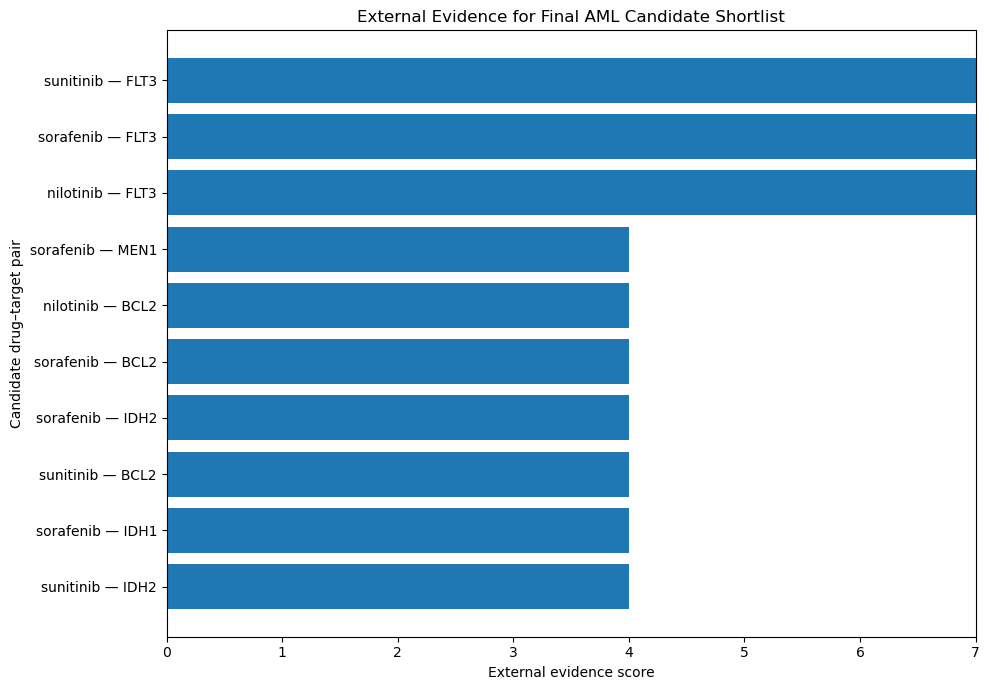

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/final_aml_candidate_evidence_scores.png


In [135]:
import matplotlib.pyplot as plt
final_shortlist_plot_df = (
    final_validated_shortlist_df
    .copy()
)

final_shortlist_plot_df[
    "candidate_label"
] = (
    final_shortlist_plot_df[
        "drug_name"
    ]
    + " — "
    + final_shortlist_plot_df[
        "gene_symbol"
    ]
)

final_shortlist_plot_df = (
    final_shortlist_plot_df
    .sort_values(
        [
            "external_evidence_score",
            "predicted_kiba_score",
        ],
        ascending=[
            True,
            True,
        ],
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    final_shortlist_plot_df[
        "candidate_label"
    ],
    final_shortlist_plot_df[
        "external_evidence_score"
    ],
)

plt.xlabel(
    "External evidence score"
)

plt.ylabel(
    "Candidate drug–target pair"
)

plt.title(
    "External Evidence for Final "
    "AML Candidate Shortlist"
)

plt.xlim(0, 7)

plt.tight_layout()

plt.savefig(
    final_shortlist_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(final_shortlist_plot_path)

In [136]:
highest_ranked_final_candidate = (
    final_validated_shortlist_df.iloc[0]
)

final_validation_summary = {
    "selected_prediction_model": (
        "GAT + CNN"
    ),
    "training_dataset": "KIBA",

    "total_validation_pairs": int(
        len(
            validation_evidence_final_df
        )
    ),

    "repurposing_candidate_pairs": int(
        len(
            final_candidate_assessment_df
        )
    ),

    "final_shortlist_size": int(
        len(
            final_validated_shortlist_df
        )
    ),

    "strong_support_candidates": int(
        (
            final_candidate_assessment_df[
                "external_evidence_strength"
            ]
            == "strong_external_support"
        ).sum()
    ),

    "moderate_support_candidates": int(
        (
            final_candidate_assessment_df[
                "external_evidence_strength"
            ]
            == "moderate_external_support"
        ).sum()
    ),

    "limited_support_candidates": int(
        (
            final_candidate_assessment_df[
                "external_evidence_strength"
            ]
            == "limited_external_support"
        ).sum()
    ),

    "model_only_candidates": int(
        (
            final_candidate_assessment_df[
                "external_evidence_strength"
            ]
            == "no_external_support_found"
        ).sum()
    ),

    "expected_reference_pairs": int(
        len(
            expected_reference_control_df
        )
    ),

    "recovered_reference_pairs": int(
        expected_reference_control_df[
            "reference_control_recovered"
        ].sum()
    ),

    "reference_control_recovery_rate": (
        float(
            reference_control_recovery_rate
        )
        if np.isfinite(
            reference_control_recovery_rate
        )
        else None
    ),

    "highest_ranked_candidate": {
        "drug_name": str(
            highest_ranked_final_candidate[
                "drug_name"
            ]
        ),
        "gene_symbol": str(
            highest_ranked_final_candidate[
                "gene_symbol"
            ]
        ),
        "predicted_kiba_score": float(
            highest_ranked_final_candidate[
                "predicted_kiba_score"
            ]
        ),
        "external_evidence_score": int(
            highest_ranked_final_candidate[
                "external_evidence_score"
            ]
        ),
        "external_evidence_strength": str(
            highest_ranked_final_candidate[
                "external_evidence_strength"
            ]
        ),
    },

    "important_interpretation": (
        "PubMed results are keyword-search "
        "results and require manual review. "
        "Clinical-trial records demonstrate "
        "drug–disease investigation but do "
        "not independently validate the "
        "predicted molecular target."
    ),

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "outputs": {
        "final_validation_assessment": str(
            final_validation_assessment_path
        ),
        "final_candidate_assessment": str(
            final_candidate_assessment_path
        ),
        "final_shortlist": str(
            final_validated_shortlist_path
        ),
        "top_candidate_per_target": str(
            final_top_candidate_per_target_path
        ),
        "reference_control_assessment": str(
            reference_control_assessment_path
        ),
        "evidence_summary": str(
            final_candidate_evidence_summary_path
        ),
        "evidence_plot": str(
            final_shortlist_plot_path
        ),
    },
}

with open(
    final_validation_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        final_validation_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        final_validation_summary,
        indent=4,
    )
)

{
    "selected_prediction_model": "GAT + CNN",
    "training_dataset": "KIBA",
    "total_validation_pairs": 54,
    "repurposing_candidate_pairs": 18,
    "final_shortlist_size": 10,
    "strong_support_candidates": 3,
    "moderate_support_candidates": 8,
    "limited_support_candidates": 7,
    "model_only_candidates": 0,
    "expected_reference_pairs": 6,
    "recovered_reference_pairs": 2,
    "reference_control_recovery_rate": 0.3333333333333333,
    "highest_ranked_candidate": {
        "drug_name": "sunitinib",
        "gene_symbol": "FLT3",
        "predicted_kiba_score": 12.93037223815918,
        "external_evidence_score": 7,
        "external_evidence_strength": "strong_external_support"
    },
    "important_interpretation": "PubMed results are keyword-search results and require manual review. Clinical-trial records demonstrate drug\u2013disease investigation but do not independently validate the predicted molecular target.",
    "created_utc": "2026-08-05T19:21:20.619338

In [137]:
final_validation_outputs = [
    final_validation_assessment_path,
    final_candidate_assessment_path,
    final_validated_shortlist_path,
    final_top_candidate_per_target_path,
    reference_control_assessment_path,
    final_candidate_evidence_summary_path,
    final_validation_summary_path,
    final_shortlist_plot_path,
    validation_evidence_path,
]

for output_path in (
    final_validation_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in final_validation_outputs
)

assert not final_candidate_assessment_df.empty

assert not final_validated_shortlist_df.empty

assert (
    final_validated_shortlist_df[
        "pair_id"
    ].is_unique
)

assert (
    final_candidate_assessment_df[
        "validation_record_type"
    ]
    == "repurposing_candidate"
).all()

print()

print(
    "Final AML candidate validation "
    "and evidence assessment completed."
)

final_validation_assessment.csv → True
final_candidate_assessment.csv → True
final_validated_candidate_shortlist.csv → True
final_top_candidate_per_target.csv → True
reference_control_assessment.csv → True
final_candidate_evidence_summary.csv → True
final_validation_summary.json → True
final_aml_candidate_evidence_scores.png → True
validation_evidence.csv → True

Final AML candidate validation and evidence assessment completed.


# Phase 8 Complete

The shortlisted AML drug–target predictions were assessed using:

- predicted transformed KIBA affinity scores;
- ChEMBL experimental binding evidence;
- PubMed literature-search evidence;
- ClinicalTrials.gov AML development evidence;
- expected reference-control recovery.

Candidates were classified as:

- strong external support;
- moderate external support;
- limited external support;
- no external support found.

The resulting shortlist represents externally assessed computational hypotheses.

PubMed articles and posted clinical-trial results must still be reviewed manually before claims of biological or clinical validation are made.